In [1]:
import pandas as pd
import numpy as np
import spacy
import matplotlib.pyplot as plt
import re
import unicodedata
import warnings
import joblib

from pathlib import Path
from collections import Counter
from spacy.matcher import PhraseMatcher
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, confusion_matrix

import seaborn as sns
from scipy.sparse import triu
from scipy.sparse.csgraph import connected_components
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'data').is_dir()
)

data_dir = project_root / 'data'
models_dir = project_root / 'models'
output_dir = project_root / 'outputs'

models_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)


In [2]:
df = pd.read_csv(data_dir / 'job_descriptions.csv')
df.head()

,Job Id,Experience,Qualifications,Salary Range,location,Country,latitude,longitude,Work Type,Company Size,...,Contact,Job Title,Role,Job Portal,Job Description,Benefits,skills,Responsibilities,Company,Company Profile
0,1089843540111562,5 to 15 Years,M.Tech,$59K-$99K,Douglas,Isle of Man,54.2361,-4.5481,Intern,26801,...,001-381-930-7517x737,Digital Marketing Specialist,Social Media Manager,Snagajob,Social Media Managers oversee an organizations...,"{'Flexible Spending Accounts (FSAs), Relocatio...","Social media platforms (e.g., Facebook, Twitte...","Manage and grow social media accounts, create ...",Icahn Enterprises,"{""Sector"":""Diversified"",""Industry"":""Diversifie..."
1,398454096642776,2 to 12 Years,BCA,$56K-$116K,Ashgabat,Turkmenistan,38.9697,59.5563,Intern,100340,...,461-509-4216,Web Developer,Frontend Web Developer,Idealist,Frontend Web Developers design and implement u...,"{'Health Insurance, Retirement Plans, Paid Tim...","HTML, CSS, JavaScript Frontend frameworks (e.g...","Design and code user interfaces for websites, ...",PNC Financial Services Group,"{""Sector"":""Financial Services"",""Industry"":""Com..."
2,481640072963533,0 to 12 Years,PhD,$61K-$104K,Macao,"Macao SAR, China",22.1987,113.5439,Temporary,84525,...,9687619505,Operations Manager,Quality Control Manager,Jobs2Careers,Quality Control Managers establish and enforce...,"{'Legal Assistance, Bonuses and Incentive Prog...",Quality control processes and methodologies St...,Establish and enforce quality control standard...,United Services Automobile Assn.,"{""Sector"":""Insurance"",""Industry"":""Insurance: P..."
3,688192671473044,4 to 11 Years,PhD,$65K-$91K,Porto-Novo,Benin,9.3077,2.3158,Full-Time,129896,...,+1-820-643-5431x47576,Network Engineer,Wireless Network Engineer,FlexJobs,"Wireless Network Engineers design, implement, ...","{'Transportation Benefits, Professional Develo...",Wireless network design and architecture Wi-Fi...,"Design, configure, and optimize wireless netwo...",Hess,"{""Sector"":""Energy"",""Industry"":""Mining, Crude-O..."
4,117057806156508,1 to 12 Years,MBA,$64K-$87K,Santiago,Chile,-35.6751,-71.5429,Intern,53944,...,343.975.4702x9340,Event Manager,Conference Manager,Jobs2Careers,A Conference Manager coordinates and manages c...,"{'Flexible Spending Accounts (FSAs), Relocatio...",Event planning Conference logistics Budget man...,Specialize in conference and convention planni...,Cairn Energy,"{""Sector"":""Energy"",""Industry"":""Energy - Oil & ..."


In [3]:
df.shape


(1615940, 23)

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1615940 entries, 0 to 1615939
Data columns (total 23 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   Job Id            1615940 non-null  int64  
 1   Experience        1615940 non-null  str    
 2   Qualifications    1615940 non-null  str    
 3   Salary Range      1615940 non-null  str    
 4   location          1615940 non-null  str    
 5   Country           1615940 non-null  str    
 6   latitude          1615940 non-null  float64
 7   longitude         1615940 non-null  float64
 8   Work Type         1615940 non-null  str    
 9   Company Size      1615940 non-null  int64  
 10  Job Posting Date  1615940 non-null  str    
 11  Preference        1615940 non-null  str    
 12  Contact Person    1615940 non-null  str    
 13  Contact           1615940 non-null  str    
 14  Job Title         1615940 non-null  str    
 15  Role              1615940 non-null  str    
 16  Job Portal 

In [5]:
df.duplicated().sum()


np.int64(0)

In [6]:
df.isnull().sum()


Job Id                 0
Experience             0
Qualifications         0
Salary Range           0
location               0
Country                0
latitude               0
longitude              0
Work Type              0
Company Size           0
Job Posting Date       0
Preference             0
Contact Person         0
Contact                0
Job Title              0
Role                   0
Job Portal             0
Job Description        0
Benefits               0
skills                 0
Responsibilities       0
Company                0
Company Profile     5478
dtype: int64

In [7]:
df['Job Title'].nunique()


147

In [8]:
df['Job Title'].value_counts().head(15)


Job Title
UX/UI Designer                  48551
Digital Marketing Specialist    27975
Software Engineer               27630
Network Engineer                24393
Software Tester                 20945
Executive Assistant             20776
Procurement Manager             20734
Financial Advisor               20687
Sales Representative            17664
Social Media Manager            17613
Network Administrator           17581
Administrative Assistant        17484
Data Analyst                    17402
Event Planner                   17384
Procurement Specialist          17348
Name: count, dtype: int64

In [9]:
df['skills'].head(10)


0    Social media platforms (e.g., Facebook, Twitte...
1    HTML, CSS, JavaScript Frontend frameworks (e.g...
2    Quality control processes and methodologies St...
3    Wireless network design and architecture Wi-Fi...
4    Event planning Conference logistics Budget man...
5    Quality assurance processes Testing methodolog...
6    Teaching pedagogy Classroom management Curricu...
7    UI design principles and best practices Graphi...
8    Interaction design principles User behavior an...
9    Wedding planning Vendor coordination Event man...
Name: skills, dtype: str

In [10]:
df['Job Description'].head(5)


0    Social Media Managers oversee an organizations...
1    Frontend Web Developers design and implement u...
2    Quality Control Managers establish and enforce...
3    Wireless Network Engineers design, implement, ...
4    A Conference Manager coordinates and manages c...
Name: Job Description, dtype: str

In [11]:
job_df = df.copy()


In [12]:
job_df.shape


(1615940, 23)

In [13]:
job_df = job_df[
    [
        'Job Id',
        'Job Title',
        'Role',
        'Job Description',
        'skills',
        'Responsibilities',
        'Experience',
        'Qualifications',
        'Work Type',
        'location'
    ]
].copy()


In [14]:
job_df.shape


(1615940, 10)

In [15]:
job_df.isnull().sum()


Job Id              0
Job Title           0
Role                0
Job Description     0
skills              0
Responsibilities    0
Experience          0
Qualifications      0
Work Type           0
location            0
dtype: int64

In [16]:
text_columns = [
    'Job Title',
    'Role',
    'Job Description',
    'skills',
    'Responsibilities',
    'Experience',
    'Qualifications'
]

job_df[text_columns].apply(
    lambda col: col.astype(str).str.strip().eq('').sum()
)


Job Title           0
Role                0
Job Description     0
skills              0
Responsibilities    0
Experience          0
Qualifications      0
dtype: int64

In [17]:
job_df['Job Id'].nunique()


1615940

In [18]:
job_df['Job Title'].nunique()


147

In [19]:
job_df['Job Title'].value_counts().head(15)


Job Title
UX/UI Designer                  48551
Digital Marketing Specialist    27975
Software Engineer               27630
Network Engineer                24393
Software Tester                 20945
Executive Assistant             20776
Procurement Manager             20734
Financial Advisor               20687
Sales Representative            17664
Social Media Manager            17613
Network Administrator           17581
Administrative Assistant        17484
Data Analyst                    17402
Event Planner                   17384
Procurement Specialist          17348
Name: count, dtype: int64

In [20]:
job_df['Job Title'].value_counts().describe()


count      147.000000
mean     10992.789116
std       5530.941189
min       3342.000000
25%       7079.000000
50%      10441.000000
75%      13754.000000
max      48551.000000
Name: count, dtype: float64

In [21]:
job_df['description_length'] = job_df['Job Description'].str.len()

job_df['description_length'].describe()


count    1.615940e+06
mean     1.853684e+02
std      5.174361e+01
min      8.100000e+01
25%      1.560000e+02
50%      1.780000e+02
75%      2.130000e+02
max      4.300000e+02
Name: description_length, dtype: float64

In [22]:
job_df['skills_length'] = job_df['skills'].str.len()

job_df['skills_length'].describe()


count    1.615940e+06
mean     1.390129e+02
std      5.888539e+01
min      4.900000e+01
25%      9.200000e+01
50%      1.240000e+02
75%      1.720000e+02
max      3.000000e+02
Name: skills_length, dtype: float64

In [23]:
job_df['skills'].head(10)


0    Social media platforms (e.g., Facebook, Twitte...
1    HTML, CSS, JavaScript Frontend frameworks (e.g...
2    Quality control processes and methodologies St...
3    Wireless network design and architecture Wi-Fi...
4    Event planning Conference logistics Budget man...
5    Quality assurance processes Testing methodolog...
6    Teaching pedagogy Classroom management Curricu...
7    UI design principles and best practices Graphi...
8    Interaction design principles User behavior an...
9    Wedding planning Vendor coordination Event man...
Name: skills, dtype: str

In [24]:
job_df['Responsibilities'].head(10)


0    Manage and grow social media accounts, create ...
1    Design and code user interfaces for websites, ...
2    Establish and enforce quality control standard...
3    Design, configure, and optimize wireless netwo...
4    Specialize in conference and convention planni...
5    Test software applications and systems to iden...
6    Plan and deliver engaging lessons, adapting te...
7    Create visually appealing user interfaces (UI)...
8    Work on interaction design, defining how users...
9    Offer expert advice and guidance to couples pl...
Name: Responsibilities, dtype: str

In [25]:
job_df['Qualifications'].head(10)


0    M.Tech
1       BCA
2       PhD
3       PhD
4       MBA
5       MCA
6       PhD
7     M.Com
8       BBA
9       BBA
Name: Qualifications, dtype: str

In [26]:
job_df['Experience'].value_counts().head(15)


Experience
5 to 8 Years     34120
5 to 12 Years    34056
5 to 9 Years     34020
3 to 13 Years    33915
3 to 15 Years    33878
2 to 9 Years     33862
3 to 8 Years     33854
1 to 11 Years    33820
3 to 12 Years    33805
1 to 10 Years    33793
4 to 11 Years    33776
3 to 9 Years     33744
4 to 14 Years    33744
4 to 12 Years    33737
2 to 8 Years     33736
Name: count, dtype: int64

In [27]:
job_df['min_experience'] = (
    job_df['Experience']
    .str.extract(r'(\d+)')
    .astype(int)
)

job_df['min_experience'].describe()


count    1.615940e+06
mean     2.501808e+00
std      1.707809e+00
min      0.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      4.000000e+00
max      5.000000e+00
Name: min_experience, dtype: float64

In [28]:
job_df['Work Type'].value_counts()


Work Type
Part-Time    324044
Temporary    323439
Contract     323131
Intern       323090
Full-Time    322236
Name: count, dtype: int64

In [29]:
job_df['location'].value_counts().head(15)


location
Seoul                        15104
Apia                         15057
Valletta                      7723
Caracas                       7694
Mogadishu                     7689
Freetown                      7656
Sri Jayawardenepura Kotte     7649
Hanoi                         7649
Baku                          7643
San Marino                    7638
Ashgabat                      7633
Kigali                        7630
Stockholm                     7626
Mexico City                   7617
Suva                          7612
Name: count, dtype: int64

In [30]:
job_df['Role'].nunique()


376

In [31]:
job_df['Role'].value_counts().head(15)


Role
Interaction Designer         20580
Network Administrator        17470
User Interface Designer      14036
Social Media Manager         13945
User Experience Designer     13935
Procurement Analyst          13757
Social Media Analyst         10659
Quality Assurance Analyst    10541
SEO Specialist               10512
Executive Assistant          10496
Database Administrator       10482
Procurement Manager          10407
Data Analyst                 10406
Backend Developer            10404
Demand Planner               10362
Name: count, dtype: int64

In [32]:
job_df[['Job Title', 'Role']].drop_duplicates().head(20)


,Job Title,Role
0,Digital Marketing Specialist,Social Media Manager
1,Web Developer,Frontend Web Developer
2,Operations Manager,Quality Control Manager
3,Network Engineer,Wireless Network Engineer
4,Event Manager,Conference Manager
5,Software Tester,Quality Assurance Analyst
6,Teacher,Classroom Teacher
7,UX/UI Designer,User Interface Designer
8,UX/UI Designer,Interaction Designer
9,Wedding Planner,Wedding Consultant


In [33]:
job_df['Qualifications'].value_counts().head(15)


Qualifications
BBA       162148
BA        162138
BCA       161733
M.Tech    161719
PhD       161662
MBA       161537
B.Tech    161443
M.Com     161396
B.Com     161298
MCA       160866
Name: count, dtype: int64

In [34]:
job_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1615940 entries, 0 to 1615939
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype
---  ------              --------------    -----
 0   Job Id              1615940 non-null  int64
 1   Job Title           1615940 non-null  str  
 2   Role                1615940 non-null  str  
 3   Job Description     1615940 non-null  str  
 4   skills              1615940 non-null  str  
 5   Responsibilities    1615940 non-null  str  
 6   Experience          1615940 non-null  str  
 7   Qualifications      1615940 non-null  str  
 8   Work Type           1615940 non-null  str  
 9   location            1615940 non-null  str  
 10  description_length  1615940 non-null  int64
 11  skills_length       1615940 non-null  int64
 12  min_experience      1615940 non-null  int64
dtypes: int64(4), str(9)
memory usage: 160.3 MB


In [35]:
job_df.memory_usage(deep=True).sort_values(ascending=False)


Responsibilities      379749856
Job Description       379298597
skills                303817496
Role                  112679427
Job Title             107215743
Experience             99783279
location               93666097
Work Type              92432119
Qualifications         85481616
Job Id                 12927520
skills_length          12927520
description_length     12927520
min_experience         12927520
Index                       132
dtype: int64

In [36]:
categorical_columns = [
    'Job Title',
    'Role',
    'Work Type',
    'Qualifications',
    'location'
]

for col in categorical_columns:
    job_df[col] = job_df[col].astype('category')


In [37]:
job_df.memory_usage(deep=True).sum() / (1024 ** 2)


np.float64(1170.4790420532227)

In [38]:
job_df.memory_usage(deep=True).sort_values(ascending=False).head(10)


Responsibilities      379749856
Job Description       379298597
skills                303817496
Experience             99783279
Job Id                 12927520
skills_length          12927520
min_experience         12927520
description_length     12927520
Role                    3258192
location                3244295
dtype: int64

In [39]:
job_df['Experience'].nunique()


48

In [40]:
job_df['Experience'] = job_df['Experience'].astype('category')


In [41]:
job_df.memory_usage(deep=True).sum() / (1024 ** 2)


np.float64(1076.8621988296509)

In [42]:
job_df[categorical_columns].nunique()


Job Title         147
Role              376
Work Type           5
Qualifications     10
location          214
dtype: int64

In [43]:
df2 = pd.read_csv(data_dir / 'Resume.csv')
df2.head()

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [44]:
df2['Category'].unique()


<StringArray>
[                    'HR',               'DESIGNER', 'INFORMATION-TECHNOLOGY',
                'TEACHER',               'ADVOCATE',   'BUSINESS-DEVELOPMENT',
             'HEALTHCARE',                'FITNESS',            'AGRICULTURE',
                    'BPO',                  'SALES',             'CONSULTANT',
          'DIGITAL-MEDIA',             'AUTOMOBILE',                   'CHEF',
                'FINANCE',                'APPAREL',            'ENGINEERING',
             'ACCOUNTANT',           'CONSTRUCTION',       'PUBLIC-RELATIONS',
                'BANKING',                   'ARTS',               'AVIATION']
Length: 24, dtype: str

In [45]:
df2.shape


(2484, 4)

In [46]:
df2.info()


<class 'pandas.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           2484 non-null   int64
 1   Resume_str   2484 non-null   str  
 2   Resume_html  2484 non-null   str  
 3   Category     2484 non-null   str  
dtypes: int64(1), str(3)
memory usage: 77.8 KB


In [47]:
df2['Category'].value_counts()


Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

In [48]:
df2['Resume_str'].iloc[0]


"         HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss pr

In [49]:
df2['Resume_str'].str.len().describe()


count     2484.000000
mean      6295.308776
std       2769.251458
min         21.000000
25%       5160.000000
50%       5886.500000
75%       7227.250000
max      38842.000000
Name: Resume_str, dtype: float64

In [50]:
df2['resume_length'] = df2['Resume_str'].str.len()

df2.sort_values('resume_length').head(10)[
    ['ID', 'Category', 'resume_length', 'Resume_str']
]


,ID,Category,resume_length,Resume_str
656,12632728,BUSINESS-DEVELOPMENT,21,
1931,22965804,CONSTRUCTION,881,CONSTRUCTION WORKER Highlig...
130,21705160,DESIGNER,985,GRAPHIC DESIGNER Expe...
1102,14381464,SALES,995,SALES ASSOCIATE Summary My g...
1049,12696104,SALES,1033,SALES ASSOCIATE Summary Moti...
1400,35468363,CHEF,1130,SUSHI CHEF Executive Profile ...
153,78149576,DESIGNER,1181,FLORAL DESIGNER Skills B...
1852,24799301,ACCOUNTANT,1210,ACCOUNTANT Summary Accountan...
1039,98108571,SALES,1212,SALES ASSOCIATE Experience ...
2322,30594821,ARTS,1272,CERTIFIED CUSTOM FRAMER Q...


In [51]:
df2.loc[df2['resume_length'].idxmin(), 'Resume_str']


'                     '

In [52]:
df2.loc[df2['resume_length'].idxmin(), 'Resume_str'].isspace()


True

In [53]:
df2['Resume_str'].str.strip().eq('').sum()


np.int64(1)

In [54]:
(df2['Resume_str'].str.strip().str.len() < 500).sum()


np.int64(1)

In [55]:
df2.loc[df2['resume_length'].idxmax(), 'Resume_str'][:2000]


'         CHEF       Credentials     National Registry of Food Safety Professionals Certified Food Safety Manager  National Registry of Food Safety Professionals Test Administrator/Proctor       Education and Training      High School Diploma     Jun 1991     Newington High School   －   City  ,   State            Summary    Passionate Chef with broad background in various culinary styles and positions. A natural leader with excellent interpersonal communication skills and the ability to get things done overcoming any obstacles.\xa0      Accomplishments     Voted Best Restaurant 2013  Multiple "Best Of" accolades       Experience      Chef     Oct 2016   to   Current      Company Name   －   City  ,   State      \xa0All aspects of an independently operated Hospital kitchen including staffing, payroll, menus, inventory/ordering, P&L, employee training and discipline, cleaning and equipment maintenance.      Monitor p&l and food and labor costs to maximize budget and minimize waste.      I

In [56]:
df2['Resume_str'].duplicated().sum()


np.int64(2)

In [57]:
duplicate_resumes = df2[df2['Resume_str'].duplicated(keep=False)]

duplicate_resumes[['ID', 'Category', 'Resume_str']]


,ID,Category,Resume_str
1490,19147603,FINANCE,FINANCE OFFICER Professional ...
1509,28398216,FINANCE,FINANCE OFFICER Professional ...
2444,16850314,AVIATION,STOREKEEPER II Professional Sum...
2483,37473139,AVIATION,STOREKEEPER II Professional Sum...


In [58]:
df2['Category'].value_counts().describe()


count     24.000000
mean     103.500000
std       26.073475
min       22.000000
25%      102.750000
50%      115.000000
75%      118.000000
max      120.000000
Name: count, dtype: float64

In [59]:
resume_df = df2.copy()

resume_df['Resume_str'] = resume_df['Resume_str'].str.strip()

resume_df = resume_df[resume_df['Resume_str'] != '']

resume_df = resume_df.drop_duplicates(subset='Resume_str')

resume_df = resume_df.reset_index(drop=True)


In [60]:
resume_df.shape


(2481, 5)

In [61]:
resume_df.isnull().sum()


ID               0
Resume_str       0
Resume_html      0
Category         0
resume_length    0
dtype: int64

In [62]:
resume_df['Resume_str'].str.strip().eq('').sum()


np.int64(0)

In [63]:
resume_df['Resume_str'].duplicated().sum()


np.int64(0)

In [64]:
print(resume_df['Resume_str'].iloc[0][:2000])


HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss prevention, sa

In [65]:
resume_df['Resume_str'].str.contains(
    r'[^a-zA-Z0-9\s.,;:/()&+-]',
    regex=True
).sum()


np.int64(2402)

In [66]:
from collections import Counter

characters = Counter(
    char
    for resume in resume_df['Resume_str']
    for char in resume
    if not (char.isalnum() or char.isspace() or char in '.,;:/()&+-')
)

characters.most_common(20)


[("'", 7129),
 ('－', 6890),
 ('%', 2533),
 ('"', 2505),
 ('$', 2210),
 ('*', 1974),
 ('–', 1502),
 ('•', 966),
 ('_', 866),
 (']', 748),
 ('[', 743),
 ('·', 617),
 ('|', 408),
 ('\u200b', 406),
 ('#', 293),
 ('=', 186),
 ('?', 157),
 ('\xad', 155),
 ('●', 127),
 ('!', 123)]

In [67]:
resume_df['Resume_str'].str.contains(
    r'<[^>]+>',
    regex=True
).sum()


np.int64(8)

In [68]:
html_resumes = resume_df[
    resume_df['Resume_str'].str.contains(r'<[^>]+>', regex=True)
]

html_resumes[['ID', 'Category', 'Resume_str']].head()


,ID,Category,Resume_str
626,14241621,BUSINESS-DEVELOPMENT,BUSINESS DEVELOPMENT CENTER MANAGER Pr...
1263,62700506,DIGITAL-MEDIA,DIGITAL CONSULTANT Summary I am see...
1422,14569498,CHEF,CHEF OWNER Executive Profile A combi...
1576,98513424,FINANCE,SR. FINANCE MANAGER Summary Finance ...
1702,43752620,ENGINEERING,ENGINEERING INTERN Summary Automotive...


In [69]:
resume_df.loc[
    resume_df['Resume_str'].str.contains(r'<[^>]+>', regex=True),
    ['ID', 'Category', 'Resume_str']
].iloc[0]


ID                                                     14241621
Category                                   BUSINESS-DEVELOPMENT
Resume_str    BUSINESS DEVELOPMENT CENTER MANAGER         Pr...
Name: 626, dtype: object

In [70]:
text = resume_df.loc[626, 'Resume_str']

import re

re.findall(r'<[^>]+>', text)


['<15>']

In [71]:
email_count = resume_df['Resume_str'].str.contains(
    r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
    regex=True
).sum()

url_count = resume_df['Resume_str'].str.contains(
    r'https?://|www\.',
    regex=True
).sum()

email_count, url_count


(np.int64(19), np.int64(99))

In [72]:
phone_count = resume_df['Resume_str'].str.contains(
    r'\b(?:\+?\d[\d\s().-]{7,}\d)\b',
    regex=True
).sum()

phone_count


np.int64(537)

In [73]:
phone_examples = resume_df[
    resume_df['Resume_str'].str.contains(
        r'\b(?:\+?\d[\d\s().-]{7,}\d)\b',
        regex=True
    )
]

phone_examples['Resume_str'].head(3).tolist()


['HR GENERALIST       Summary     A people-oriented, results-driven professional with outstanding communication skills.   Extensive experience delivering top-quality solutions for high-profile clients. Seeking to   obtain a position which would allow me to apply my current knowledge, obtain new information and grow with a company.       Highlights        Word, Excel, PowerPoint, Darwin, Act, Attendance Advisor, ERP/AS400, HRIS, ADP Payroll, Paycor, Internet Explorer, Outlook, Kronos, IFAS, PeopleSoft, Epicor, Winpak, E2, WASP            Accomplishments     Created and implemented Employee Requisition Procedure  Developed and executed Employee Internship/Co-Op Program       Experience      HR Generalist     Sep 2014   to   Current      Company Name   -   City  ,   State     Built the department from the ground up as the first HR person.  This involved putting policies and procedures in place to ensure compliance with          State and Federal law.  A significant amount of time and ener

In [74]:
job_df['Job Description'].str.contains(
    r'https?://|www\.',
    regex=True
).sum()


np.int64(0)

In [75]:
job_df['Job Description'].str.contains(
    r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
    regex=True
).sum()


np.int64(0)

In [76]:
job_df['skills'].str.contains(
    r'https?://|www\.|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}',
    regex=True
).sum()


np.int64(0)

In [77]:
text_columns = ['Job Title', 'Job Description', 'skills']

job_df[text_columns].isna().sum()


Job Title          0
Job Description    0
skills             0
dtype: int64

In [78]:
job_df['skills'].head(10).tolist()


['Social media platforms (e.g., Facebook, Twitter, Instagram) Content creation and scheduling Social media analytics and insights Community engagement Paid social advertising',
 'HTML, CSS, JavaScript Frontend frameworks (e.g., React, Angular) User experience (UX)',
 'Quality control processes and methodologies Statistical process control (SPC) Root cause analysis and corrective action Quality management systems (e.g., ISO 9001) Compliance and regulatory knowledge',
 'Wireless network design and architecture Wi-Fi standards and protocols RF (Radio Frequency) planning and optimization Wireless security protocols Troubleshooting wireless network issues',
 'Event planning Conference logistics Budget management Vendor coordination Marketing and promotion Client relations',
 'Quality assurance processes Testing methodologies (e.g., manual, automated) Bug tracking and reporting Test case development Regression testing',
 'Teaching pedagogy Classroom management Curriculum development Student 

In [79]:
job_df[['Job Description', 'Responsibilities']].head(5)


,Job Description,Responsibilities
0,Social Media Managers oversee an organizations...,"Manage and grow social media accounts, create ..."
1,Frontend Web Developers design and implement u...,"Design and code user interfaces for websites, ..."
2,Quality Control Managers establish and enforce...,Establish and enforce quality control standard...
3,"Wireless Network Engineers design, implement, ...","Design, configure, and optimize wireless netwo..."
4,A Conference Manager coordinates and manages c...,Specialize in conference and convention planni...


In [80]:
job_df['Responsibilities'].str.contains(
    r'https?://|www\.|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}',
    regex=True
).sum()


np.int64(0)

In [81]:
import unicodedata

job_df['skills_clean'] = (
    job_df['skills']
    .astype(str)
    .apply(lambda text: unicodedata.normalize('NFKC', text))
    .str.replace('\u200b', '', regex=False)
    .str.replace('\xad', '', regex=False)
    .str.replace(r'[‐‑‒–—−]', '-', regex=True)
    .str.strip()
)


In [82]:
job_df[['skills', 'skills_clean']].head(10)


,skills,skills_clean
0,"Social media platforms (e.g., Facebook, Twitte...","Social media platforms (e.g., Facebook, Twitte..."
1,"HTML, CSS, JavaScript Frontend frameworks (e.g...","HTML, CSS, JavaScript Frontend frameworks (e.g..."
2,Quality control processes and methodologies St...,Quality control processes and methodologies St...
3,Wireless network design and architecture Wi-Fi...,Wireless network design and architecture Wi-Fi...
4,Event planning Conference logistics Budget man...,Event planning Conference logistics Budget man...
5,Quality assurance processes Testing methodolog...,Quality assurance processes Testing methodolog...
6,Teaching pedagogy Classroom management Curricu...,Teaching pedagogy Classroom management Curricu...
7,UI design principles and best practices Graphi...,UI design principles and best practices Graphi...
8,Interaction design principles User behavior an...,Interaction design principles User behavior an...
9,Wedding planning Vendor coordination Event man...,Wedding planning Vendor coordination Event man...


In [83]:
print(job_df.loc[9, 'skills_clean'])


Wedding planning Vendor coordination Event management


In [84]:
text_columns = [
    'Job Title',
    'Role',
    'Job Description',
    'Responsibilities'
]

for col in text_columns:
    job_df[f'{col}_clean'] = (
        job_df[col]
        .astype(str)
        .apply(lambda text: unicodedata.normalize('NFKC', text))
        .str.replace('\u200b', '', regex=False)
        .str.replace('\xad', '', regex=False)
        .str.replace(r'[‐-‒–—−]', '-', regex=True)
        .str.strip()
    )


In [85]:
clean_columns = [
    'Job Title_clean',
    'Role_clean',
    'Job Description_clean',
    'Responsibilities_clean',
    'skills_clean'
]

job_df[clean_columns].isna().sum()


Job Title_clean           0
Role_clean                0
Job Description_clean     0
Responsibilities_clean    0
skills_clean              0
dtype: int64

In [86]:
job_df['job_text'] = (
    job_df['Job Title_clean'] + ' ' +
    job_df['Role_clean'] + ' ' +
    job_df['Job Description_clean'] + ' ' +
    job_df['Responsibilities_clean'] + ' ' +
    job_df['skills_clean']
)


In [87]:
print(job_df.loc[0, 'job_text'])

print("\nCharacter count:", len(job_df.loc[0, 'job_text']))


Digital Marketing Specialist Social Media Manager Social Media Managers oversee an organizations social media presence. They create and schedule content, engage with followers, and analyze social media metrics to drive brand awareness and engagement. Manage and grow social media accounts, create engaging content, and interact with the online community. Develop social media content calendars and strategies. Monitor social media trends and engagement metrics. Social media platforms (e.g., Facebook, Twitter, Instagram) Content creation and scheduling Social media analytics and insights Community engagement Paid social advertising

Character count: 634


In [88]:
resume_df['resume_clean'] = (
    resume_df['Resume_str']
    .apply(lambda text: unicodedata.normalize('NFKC', text))
    .str.replace('\u200b', '', regex=False)
    .str.replace('\xad', '', regex=False)
    .str.replace(r'[‐-‒–—−]', '-', regex=True)
    .str.strip()
)


In [89]:
print(resume_df.loc[0, 'resume_clean'][:2000])


HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss prevention, sa

In [90]:
resume_df['resume_clean'].str.contains(
    r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
    regex=True
).sum()


np.int64(19)

In [91]:
resume_df['resume_clean'] = (
    resume_df['resume_clean']
    .str.replace(
        r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
        ' ',
        regex=True
    )
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)


In [92]:
resume_df['resume_clean'].str.contains(
    r'https?://|www\.',
    regex=True
).sum()


np.int64(99)

In [93]:
resume_df['resume_clean'] = (
    resume_df['resume_clean']
    .str.replace(
        r'https?://\S+|www\.\S+',
        ' ',
        regex=True
    )
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)


In [94]:
resume_df['resume_clean'].str.contains(
    r'\b(?:\+?\d[\d\s().-]{7,}\d)\b',
    regex=True
).sum()


np.int64(531)

In [95]:
phone_pattern = r'\b(?:\+?\d[\d\s().-]{7,}\d)\b'

matches = resume_df['resume_clean'].str.extractall(
    f'({phone_pattern})'
)

matches.head(20)


0
   match             
13 0        1998-1999
14 0        2009-2010
23 0        2012 - 12
   1        2005 - 07
   2        2003 - 10
25 0        2012 - 09
   1        2008 - 09
   2        2003 - 03
28 0        2006-2010
   1        2002-2004
29 0        2319-1902
53 0        2008 - 02
   1        2008 - 11
   2        2002 - 08
   3        1998 - 02
59 0      2011 - 2015
   1      2011 - 2015
   2      2011 - 2015
   3      2011 - 2015
   4      2011 - 2015

In [96]:
resume_df['resume_clean'].str.contains(
    r'\s{2,}',
    regex=True
).sum()


np.int64(0)

In [97]:
resume_df['resume_clean'].str.len().describe()


count     2481.000000
mean      5925.696896
std       2681.638047
min        688.000000
25%       4814.000000
50%       5538.000000
75%       6839.000000
max      35215.000000
Name: resume_clean, dtype: float64

In [98]:
resume_df['resume_clean'].isna().sum(), (
    resume_df['resume_clean'].str.strip() == ''
).sum()


(np.int64(0), np.int64(0))

In [99]:
resume_df['Category'].value_counts().head(10)


Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
FINANCE                   117
SALES                     116
AVIATION                  116
Name: count, dtype: int64

In [100]:
resume_df.loc[0, 'resume_clean'][-1500:]


' / Marketing Assistant Jul 2007 to Jun 2010 Company Name - City , State Provided assistance to various department heads - Executive, Marketing, Customer Service, Human Resources. Managed front-end operations to ensure friendly and efficient transactions. Ensured the swift resolution of customer issues to preserve customer loyalty while complying with company policies. Exemplified the second-to-none customer service delivery in all interactions with customers and potential clients. Reservation & Front Office Manager Jun 2004 to Jul 2007 Company Name - City , State Owner/ Partner Dec 2001 to May 2004 Company Name - City , State Price Integrity Coordinator Aug 1999 to Dec 2001 Company Name - City , State Education N/A , Business Administration 1999 Jefferson College - City , State Business Administration Marketing / Advertising High School Diploma , College Prep. studies 1998 Sainte Genevieve Senior High - City , State Awarded American Shrubel Leadership Scholarship to Jefferson College 

In [101]:
resume_df['resume_clean'].str.contains(
    r'\bskills\b',
    case=False,
    regex=True
).sum()


np.int64(2457)

In [102]:
resume_df.loc[
    ~resume_df['resume_clean'].str.contains(
        r'\bskills\b',
        case=False,
        regex=True
    ),
    ['ID', 'Category']
].head(10)


,ID,Category
122,90066849,DESIGNER
160,10466583,DESIGNER
503,17021141,ADVOCATE
557,65708020,BUSINESS-DEVELOPMENT
576,98379112,BUSINESS-DEVELOPMENT
663,18937778,BUSINESS-DEVELOPMENT
669,28337049,BUSINESS-DEVELOPMENT
670,33424600,BUSINESS-DEVELOPMENT
733,11704150,HEALTHCARE
784,35422305,HEALTHCARE


In [103]:
resume_df.loc[
    resume_df['ID'] == 90066849,
    'resume_clean'
].iloc[0][:2000]


"INSTRUCTIONAL DESIGNER Summary Tamantha Uebele is a Home Health Clinical Analyst and Instructional Designer with over 28 years' experience in home health and hospice and the Epic Home Health application for 5 years. During an enterprise install for ProHealth Care, Tamantha served as Business Analyst, Principal Trainer, and Application Coordinator during an end-to-end implementation and system updates post go-live. She was into the build phase of a system upgrade when she went into consulting. As analyst consultant for Providence Health & Services, she led a Community Connect Home Health implementation project involving discovery, validation, workflow design, build, and testing. At Northwest Community Hospital, she served as build analyst on the Home Health team where her experience involved validation, workflow design, build, testing, and clinical break-out sessions. At Lahey Health, Tamantha was Instructional Designer leading their Home Health agency's training environment build, mat

In [104]:
resume_df['resume_clean'].str.count(
    r'\bSkills\b'
).value_counts().sort_index()


resume_clean
0       76
1     1676
2      547
3      110
4       32
5       17
6       13
7        4
8        2
9        1
10       1
13       1
20       1
Name: count, dtype: int64

In [105]:
for i in range(5):
    text = resume_df.loc[i, 'resume_clean']
    match = re.search(r'\bSkills\b', text, re.IGNORECASE)

    if match:
        print(f"\nRESUME {i}")
        print(text[match.start()-100:match.start()+700])



RESUME 0
paperwork that is submitted by healthcare providers. Required to have organizational and analytical skills as well as computer skills, knowledge of medical terminology and procedures, statistics, billing standards, data analysis and laws regarding medical billing. Assistant General Manager Jun 2010 to Dec 2010 Company Name - City , State Performed duties including but not limited to, budgeting and financial management, accounting, human resources, payroll and purchasing. Established and maintained close working relationships with all departments of the hotel to ensure maximum operation, productivity, morale and guest service. Handled daily operations and reported directly to the corporate office. Hired and trained staff on overall objectives and goals with an emphasis on high customer serv

RESUME 1
013 Bachelor of Arts : Relational Communication Western Connecticut State University - City , State Skills Adobe Photoshop, ADP, Asset Management, branding, brochures, content, Cu

In [106]:
nlp = spacy.load('en_core_web_sm')

print("spaCy model loaded successfully.")


spaCy model loaded successfully.


In [107]:
skills_dictionary = [
    'Python',
    'Java',
    'C++',
    'SQL',
    'Excel',
    'Microsoft Office',
    'Power BI',
    'Tableau',
    'Data Analysis',
    'Data Visualization',
    'Machine Learning',
    'Statistical Analysis',
    'Project Management',
    'Business Analysis',
    'Communication',
    'Leadership',
    'Problem Solving',
    'Customer Service',
    'Human Resources',
    'Recruitment',
    'Marketing',
    'Social Media Marketing',
    'Content Creation',
    'Graphic Design',
    'Adobe Photoshop',
    'Adobe Illustrator',
    'HTML',
    'CSS',
    'JavaScript',
    'React',
    'Network Administration',
    'Quality Assurance',
    'Testing',
    'Budgeting',
    'Accounting',
    'Financial Management',
    'Payroll',
    'Teaching',
    'Curriculum Development',
    'Event Planning',
    'Vendor Management'
]

print("Number of skills:", len(skills_dictionary))


Number of skills: 41


In [108]:
matcher = PhraseMatcher(nlp.vocab, attr='LOWER')

patterns = [nlp.make_doc(skill) for skill in skills_dictionary]

matcher.add('SKILLS', patterns)

doc = nlp("Experienced in Python, SQL, Data Analysis and Project Management.")

matches = matcher(doc)

[doc[start:end].text for _, start, end in matches]


['Python', 'SQL', 'Data Analysis', 'Project Management']

In [109]:
print("Unique skills descriptions:", job_df['skills'].nunique())

job_df['skills'].value_counts().head(10)


Unique skills descriptions: 376


skills
Interaction design principles User behavior and psychology Wireframing and prototyping tools Animation and micro-interaction design Collaborative design processes                                                                                   20580
Network management Troubleshooting Network security IT certifications (e.g., CCNA)                                                                                                                                                                   17470
UI design principles and best practices Graphic design tools (e.g., Adobe Photoshop, Illustrator) Typography and color theory Visual design and layout Responsive design                                                                             14036
Social media platforms (e.g., Facebook, Twitter, Instagram) Content creation and scheduling Social media analytics and insights Community engagement Paid social advertising                                                                    

In [110]:
additional_skills = [
    'Interaction Design',
    'User Behavior',
    'Wireframing',
    'Prototyping',
    'Animation',
    'Micro-interaction Design',
    'Collaborative Design',
    'Network Management',
    'Network Security',
    'Troubleshooting',
    'CCNA',
    'UI Design',
    'UX Design',
    'Typography',
    'Color Theory',
    'Visual Design',
    'Responsive Design',
    'User-Centered Design',
    'Sketch',
    'Adobe XD',
    'Usability Testing',
    'User Research',
    'Information Architecture',
    'User Flows',
    'Vendor Assessment',
    'Contract Negotiation',
    'Purchase Order Management',
    'Spend Analysis',
    'Market Research',
    'Supplier Relationship Management',
    'Financial Acumen',
    'Social Media Analytics',
    'Data Reporting',
    'ROI Measurement',
    'Competitive Analysis',
    'Trend Analysis',
    'Bug Tracking',
    'Test Case Development',
    'Regression Testing',
    'SEO',
    'Keyword Research',
    'On-page SEO',
    'Off-page SEO',
    'Google Analytics',
    'SEMrush',
    'SEO Content Strategy',
    'Calendar Management',
    'Travel Coordination',
    'Meeting Scheduling',
    'Office Administration',
    'Confidentiality',
    'Time Management'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 93


In [111]:
job_df['skills'].value_counts().iloc[10:30]


skills
Database management systems (e.g., MySQL, Oracle, SQL Server) Data security Database tuning and optimization Backup and recovery                                                                                                                                    10482
Procurement strategies Supplier management Negotiation Cost analysis Supply chain management                                                                                                                                                                        10407
Data analysis tools (e.g., SQL, Python) Data visualization tools (e.g., Tableau, Power BI) Statistical analysis Data cleansing and transformation Data modeling Communication of data insights Problem-solving Attention to detail Business acumen                  10406
Proficiency in one or more backend programming languages (e.g., Java, Python, Node.js, Ruby) API development Database management (SQL or NoSQL) Server management and deployment Security best prac

In [112]:
additional_skills_2 = [
    'MySQL',
    'Oracle',
    'SQL Server',
    'Database Management',
    'Database Security',
    'Data Security',
    'Database Optimization',
    'Database Backup and Recovery',
    'Supplier Management',
    'Supply Chain Management',
    'Cost Analysis',
    'Data Cleansing',
    'Data Transformation',
    'Data Modeling',
    'API Development',
    'Backend Development',
    'Node.js',
    'Ruby',
    'Django',
    'Express.js',
    'NoSQL',
    'Server Management',
    'Server Deployment',
    'Demand Forecasting',
    'Inventory Management',
    'Sales and Operations Planning',
    'ERP',
    'Facility Management',
    'Angular',
    'Vue.js',
    'Git',
    'Cross-browser Compatibility',
    'Frontend Performance Optimization',
    'Customer Relationship Management',
    'CRM',
    'Customer Onboarding',
    'Customer Feedback Analysis',
    'Customer Retention',
    'Cross-selling',
    'Upselling',
    'Retirement Planning',
    'Investment Products',
    'Tax Planning',
    'Estate Planning',
    'Sales Strategy',
    'Account Management',
    'Sales Forecasting',
    'Salesforce',
    'Lead Generation',
    'Sales Negotiation',
    'Figma',
    'Intrusion Detection',
    'Incident Response',
    'Firewall Administration',
    'Vulnerability Assessment',
    'Ethical Hacking',
    'Log Analysis',
    'Legal Research',
    'Document Drafting',
    'Case Management',
    'E-filing',
    'LexisNexis',
    'Training Material Development',
    'Learning Management Systems',
    'Logistics Management',
    'Sustainable Design',
    'Energy Efficiency',
    'LEED Certification',
    'Environmental Impact Assessment',
    'Scikit-learn',
    'TensorFlow',
    'PyTorch',
    'Hadoop',
    'Apache Spark',
    'R Programming'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_2
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 168


In [113]:
job_df['skills'].value_counts().iloc[30:50]


skills
System administration Server maintenance Active Directory Backup and recovery Cloud computing (e.g., AWS, Azure) Troubleshooting IT security best practices Collaboration Problem-solving Attention to detail Communication skills Technical knowledge                            7000
Data entry accuracy and speed Database software (e.g., Microsoft Access, Excel) Attention to detail Time management Organization Multitasking Keyboarding skills Data verification Problem-solving Communication skills Computer proficiency                                      6988
Manufacturing processes knowledge CAD/CAM software proficiency Lean manufacturing principles Quality control and assurance Six Sigma certification                                                                                                                                6983
Landscape design Plant selection and care Hardscape design                                                                                                  

In [114]:
additional_skills_3 = [
    'System Administration',
    'Server Maintenance',
    'Active Directory',
    'Backup and Recovery',
    'Cloud Computing',
    'AWS',
    'Microsoft Azure',
    'Google Cloud Platform',
    'IT Security',
    'Data Entry',
    'Microsoft Access',
    'Data Verification',
    'Keyboarding',
    'Manufacturing Processes',
    'CAD',
    'CAM',
    'Lean Manufacturing',
    'Six Sigma',
    'Landscape Design',
    'Plant Selection',
    'Hardscape Design',
    'Account Management',
    'Investment Management',
    'Financial Analysis',
    'Risk Assessment',
    'Asset Allocation',
    'Portfolio Optimization',
    'Portfolio Management',
    'Content Strategy',
    'Content Planning',
    'Content Marketing',
    'Product Positioning',
    'Product Messaging',
    'Product Launch Planning',
    'Marketing Collateral',
    'Pricing Strategy',
    'Inventory Control',
    'Warehouse Management',
    'Business Intelligence',
    'Data Modeling',
    'Data Reporting',
    'Market Research',
    'Data Collection',
    'Supply Chain Logistics',
    'Supplier Relationship Management',
    'Risk Mitigation',
    'Water Resources Engineering',
    'Hydrology',
    'Hydraulics',
    'Water Resource Modeling',
    'Watershed Management',
    'Python Scripting',
    'Bash',
    'CI/CD',
    'Docker',
    'Kubernetes',
    'Terraform',
    'Ansible',
    'Infrastructure as Code',
    'Cloud Monitoring',
    'Client Relationship Management',
    'Financial Modeling',
    'Financial Planning',
    'Investment Strategies',
    'Regulatory Compliance',
    'Venue Selection',
    'Catering',
    'Floral Design'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_3
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 231


In [115]:
job_df['skills'].value_counts().iloc[50:70]


skills
Front-end web development HTML, CSS, JavaScript Responsive design Web performance optimization Cross-browser compatibility                                                                                                                                                                                      6898
Family law Divorce proceedings Child custody Mediation Legal counseling Court representation                                                                                                                                                                                                                    6897
Content creation (e.g., writing, editing, graphic design, video production) Content marketing Social media management SEO optimization Creative storytelling Audience engagement Analytics and reporting Adaptability Communication skills Creativity                                                           6878
Event planning and coordination Budget management Vendor negotiati

In [116]:
additional_skills_4 = [
    'Frontend Development',
    'Web Performance Optimization',
    'Family Law',
    'Divorce Proceedings',
    'Child Custody',
    'Legal Counseling',
    'Court Representation',
    'Content Editing',
    'Video Production',
    'Creative Storytelling',
    'Audience Engagement',
    'Event Coordination',
    'Vendor Negotiation',
    'Timeline Planning',
    'Selenium',
    'Appium',
    'Test Automation',
    'Test Framework Development',
    'Continuous Integration',
    'Test Data Management',
    'Consumer Behavior Analysis',
    'Competitor Analysis',
    'Survey Design',
    'Survey Analysis',
    'SPSS',
    'SAS',
    'Report Writing',
    'Employee Benefits Administration',
    'Benefits Compliance',
    'HRIS',
    'Qualitative Research',
    'Quantitative Research',
    'Technical Troubleshooting',
    'Hardware Support',
    'Software Support',
    'UI Design',
    'UX Design',
    'Mobile Design',
    'Art History',
    'Digital Marketing Strategy',
    'PPC Advertising',
    'Geriatric Assessment',
    'Occupational Therapy',
    'Fall Prevention',
    'Care Coordination',
    'Assistive Technology',
    'Patient Advocacy',
    'Marketing Analytics',
    'Marketing Automation',
    'Adobe Creative Suite',
    'Web Design',
    'Visual Communication',
    'Patient Care',
    'Clinical Assessment',
    'Mediation',
    'Conflict Resolution',
    'Customer Support',
    'Customer Satisfaction',
    'Issue Resolution',
    'Performance Metrics',
    'Training and Development',
    'Virtualization',
    'VMware',
    'Hyper-V',
    'Storage Management',
    'Disaster Recovery',
    'Capacity Planning',
    'Cloud Infrastructure'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_4
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 297


In [117]:
job_df['skills'].value_counts().iloc[70:90]


skills
Family counseling Marriage and family therapy Conflict resolution skills                                                                                                                                                                                            3579
Brand promotion Marketing knowledge Communication skills Sales techniques Product knowledge                                                                                                                                                                         3576
Hospitality interior design Hotel and restaurant design Branding and theme integration FF&E (furniture, fixtures, and equipment) selection Customer experience design                                                                                               3575
Customer service Call center operations Problem-solving skills                                                                                                                                        

In [118]:
additional_skills_5 = [
    'Family Counseling',
    'Marriage and Family Therapy',
    'Brand Promotion',
    'Hospitality Interior Design',
    'Hotel Design',
    'Restaurant Design',
    'FF&E Selection',
    'Customer Experience Design',
    'Call Center Operations',
    'Sales Leadership',
    'Territory Management',
    'Sales Data Analysis',
    'Strategic Planning',
    'Sales Demonstration',
    'Family Medicine',
    'Health Assessment',
    'Pediatric Care',
    'Chronic Disease Management',
    'Patient Education',
    'Office Management',
    'Web Application Development',
    'Java Servlets',
    'JavaServer Pages',
    'User Authentication',
    'Security Protocols',
    'Code Documentation',
    'Forensic Accounting',
    'Fraud Detection',
    'JavaScript Programming',
    'DOM Manipulation',
    'AJAX',
    'Debugging',
    'Enterprise Architecture',
    'IT Governance',
    'Electrical Engineering',
    'Power System Analysis',
    'Renewable Energy',
    'Control Systems',
    'Network Infrastructure Design',
    'Routing and Switching',
    'TCP/IP',
    'Cisco',
    'Juniper Networks',
    'Wireless Networking',
    'Network Monitoring',
    'Statistical Process Control',
    'Root Cause Analysis',
    'Corrective Action',
    'Quality Management Systems',
    'ISO 9001',
    'Performance Testing',
    'Load Testing',
    'JMeter',
    'Test Scripting',
    'Performance Profiling',
    'Bottleneck Analysis',
    'Ceremony Planning',
    'Reception Planning',
    'Event Design',
    'E-discovery',
    'Document Review',
    'Document Production',
    'Litigation Support',
    'Relativity',
    'Sales Prospecting',
    'Consultative Selling',
    'Sales Tracking'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_5
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 364


In [119]:
job_df['skills'].value_counts().iloc[90:110]


skills
Art instruction Classroom management Art techniques Lesson planning Student assessment                                                                                                                                                                 3548
Marketing automation platforms (e.g., Marketo, Pardot) Lead nurturing Workflow automation CRM integration Analytics and reporting Email marketing Campaign optimization Marketing strategy Communication skills Problem-solving Attention to detail    3548
Marketing analytics Data analysis tools (e.g., Google Analytics, Adobe Analytics) Brand performance measurement Consumer behavior analysis Campaign effectiveness evaluation                                                                           3547
Environmental regulations Ecosystem analysis Environmental impact assessments Sustainability planning Project management                                                                                                                     

In [120]:
additional_skills_6 = [
    'Art Instruction',
    'Art Techniques',
    'Lesson Planning',
    'Marketing Automation Platforms',
    'Marketo',
    'Pardot',
    'Lead Nurturing',
    'Workflow Automation',
    'Email Marketing',
    'Campaign Optimization',
    'Adobe Analytics',
    'Brand Performance Measurement',
    'Campaign Analysis',
    'Environmental Regulations',
    'Ecosystem Analysis',
    'Environmental Impact Assessment',
    'Sustainability Planning',
    'Community Engagement',
    'Community Moderation',
    'Online Community Management',
    'Content Curation',
    'Crisis Management',
    'IT Systems Analysis',
    'IT Support',
    'IT Documentation',
    'Usability Evaluation',
    'Usability Assessment',
    'Competitive Analysis',
    'Business Strategy',
    'Surgical Procedures',
    'Operating Room Protocols',
    'Anesthesia Management',
    'Print Design',
    'Adobe InDesign',
    'Layout Design',
    'Print Production',
    'Corporate Tax Planning',
    'Tax Compliance',
    'Tax Credits',
    'Tax Strategy',
    'IRS Regulations',
    'Tax Software',
    'Test Automation Frameworks',
    'Continuous Testing',
    'Test Environment Management',
    'Quality Metrics',
    'KPIs',
    'Audit and Compliance',
    'Continuous Improvement',
    'Transportation Logistics',
    'Vendor Relations',
    'Risk Management',
    'Risk Assessment',
    'Dental Public Health',
    'Community Outreach',
    'Dental Health',
    'Epidemiology',
    'Data Architecture',
    'Database Design',
    'Environmental Compliance',
    'Environmental Auditing',
    'Legal Counsel',
    'Contract Law',
    'Legal Writing',
    'Client Representation',
    'Systems Engineering',
    'System Architecture',
    'Integration Testing',
    'Technical Documentation',
    'Configuration Management'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_6
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 431


In [121]:
job_df['skills'].value_counts().iloc[110:130]


skills
Data analysis techniques Research methodologies Data collection and interpretation Statistical analysis software (e.g., R, Python) Data visualization tools (e.g., Tableau, Power BI) Research report writing Critical thinking Problem-solving Communication skills Attention to detail    3531
Sales strategies and tactics Account management Relationship building Sales forecasting Industry and product knowledge                                                                                                                                                                      3530
UI/UX design Frontend web development Wireframing and prototyping User research Accessibility standards Responsive design Collaboration skills                                                                                                                                              3530
Pediatric healthcare Pediatric assessment Pediatric treatment Patient education Pediatric pharmacology                        

In [122]:
additional_skills_7 = [
    'Research Methodologies',
    'Data Interpretation',
    'Research Report Writing',
    'Sales Strategies',
    'Relationship Building',
    'UI/UX Design',
    'User Research',
    'Accessibility Standards',
    'Pediatric Healthcare',
    'Pediatric Assessment',
    'Pediatric Treatment',
    'Pediatric Pharmacology',
    'Facilities Management',
    'Property Maintenance',
    'Space Planning',
    'Health and Safety Compliance',
    'Desktop Support',
    'Windows',
    'macOS',
    'Remote Desktop Support',
    'Hardware Upgrades',
    'Software Upgrades',
    'Software Quality Assurance',
    'Test Planning',
    'Test Case Design',
    'Test Execution',
    'Defect Tracking',
    'Industrial Design',
    '3D Modeling',
    'SOC Operations',
    'Security Incident Response',
    'Threat Detection',
    'IDS',
    'IPS',
    'Security Alert Triage',
    'Cybersecurity',
    'Periodontal Therapy',
    'Dental Instrumentation',
    'Periodontal Disease Management',
    'Oral Health Education',
    'Investment Analysis',
    'SEO',
    'SEM',
    'A/B Testing',
    'Construction Project Management',
    'Building Codes',
    'Cost Control',
    'Construction Scheduling',
    'Contractor Coordination',
    'Subcontractor Coordination',
    'Veterinary Medicine',
    'Small Animal Care',
    'Animal Surgery',
    'Animal Diagnostics',
    'Preventive Medicine',
    'Radiology',
    'Anesthesia',
    'Laboratory Diagnostics',
    'Brand Strategy',
    'Brand Development',
    'Creative Direction',
    'Brand Management',
    'Pediatric Cardiology',
    'Pediatric Oncology',
    'Pediatric Diagnostics',
    'Clinical Nursing',
    'Critical Care',
    'Oncology Nursing',
    'Big Data',
    'Data Processing',
    'Distributed Computing',
    'Agile Methodologies',
    'Scrum',
    'Kanban',
    'Jira'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_7
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills:

 504


In [123]:
job_df['skills'].value_counts().iloc[130:150]


skills
Digital marketing strategies SEO and SEM Social media marketing Email marketing campaigns Content marketing Web analytics (e.g., Google Analytics) Marketing automation tools (e.g., HubSpot, Marketo)                                                                                                   3520
Cloud systems engineering Cloud infrastructure (e.g., AWS, Azure) DevOps practices Automation Security in the cloud Disaster recovery Scalability                                                                                                                                                        3520
Adult speech therapy Speech-language assessment Rehabilitation techniques Swallowing disorders Communication skills                                                                                                                                                                                      3518
Addiction counseling techniques Substance abuse treatment Counseling ethics            

In [124]:
additional_skills_8 = [
    'Cloud Systems Engineering',
    'DevOps',
    'Cloud Security',
    'Cloud Scalability',
    'HubSpot',
    'User Experience Strategy',
    'User Journey Mapping',
    'Design Thinking',
    'Addiction Counseling',
    'Substance Abuse Treatment',
    'Counseling Ethics',
    'Mailchimp',
    'Constant Contact',
    'Email Campaign Management',
    'Email Segmentation',
    'Email Deliverability',
    'Tax Preparation',
    'Tax Regulations',
    'Adult Speech Therapy',
    'Speech-language Assessment',
    'Speech Therapy',
    'Rehabilitation Techniques',
    'Swallowing Disorders',
    'Swift',
    'Kotlin',
    'Mobile App Development',
    'React Native',
    'Flutter',
    'Mobile App Design',
    'APIs',
    'Web Services Integration',
    'SEO Content Optimization',
    'Process Optimization',
    'Workflow Design',
    'Individual Tax Planning',
    'Tax Return Preparation',
    'Tax Deductions',
    'RESTful APIs',
    'Java EE',
    'Version Control',
    'Analytical Chemistry',
    'Laboratory Techniques',
    'Laboratory Instrumentation',
    'Sample Preparation',
    'ChemDraw',
    'Help Desk Support',
    'Ticket Resolution',
    'Knowledge Base Management',
    'Emergency Medical Care',
    'Triage',
    'Trauma Management',
    'Meta Tags',
    'Press Releases',
    'Media Outreach',
    'Crisis Communication',
    'Public Relations',
    'WCAG',
    'Assistive Technologies',
    'Accessibility Testing',
    'ARIA',
    'Lean Six Sigma',
    'Pediatric Care',
    'Pediatric Medical Procedures'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_8
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 566


In [125]:
job_df['skills'].value_counts().iloc[150:190]


skills
User interface (UI) design User experience (UX) design Web design principles Prototyping and wireframing Front-end development languages (e.g., HTML, CSS, JavaScript) Interaction design User testing Responsive design Usability testing Collaboration Attention to detail        3512
Pediatrics Pediatric care Diagnosis and treatment Pediatric medical procedures Patient care Communication skills                                                                                                                                                                    3512
Product design principles Prototyping and wireframing User research User testing UI/UX design 3D modeling (if applicable) Collaboration Problem-solving Creativity Attention to detail Communication skills Software proficiency (e.g., Sketch, Adobe XD)                           3512
Special education strategies Individualized education plans (IEPs) Behavior management techniques Collaboration with support staff Special education l

In [126]:
additional_skills_9 = [
    'Spring Framework',
    'Java Programming',
    'Object-Oriented Design',
    'Product Design',
    'Special Education',
    'Individualized Education Plans',
    'Behavior Management',
    'Curriculum Standards',
    'Instructional Design',
    'Assessment Development',
    'Educational Technology',
    'Records Management',
    'Strategic IT Planning',
    'IT Financial Management',
    'Enterprise Software',
    'Sourcing Strategies',
    'Supplier Evaluation',
    'Bridge Design',
    'Civil Engineering',
    'Structural Analysis',
    'AutoCAD',
    'Supplier Diversity',
    'Diversity and Inclusion',
    'Supplier Assessment',
    'SIEM',
    'Vulnerability Scanning',
    'B2B Sales',
    'Supply Chain Analysis',
    'Transportation Planning',
    'Test Reporting',
    'Code Review',
    'Traffic Engineering',
    'GIS',
    'Discovery Management',
    'Case Preparation',
    'Commercial Litigation',
    'Dispute Resolution',
    'Investment Evaluation',
    'Mechanical Engineering',
    'SolidWorks',
    'Finite Element Analysis',
    'Product Development',
    'Copywriting',
    'Sales Planning',
    'Tax Optimization',
    'Retirement Planning',
    'Estate Planning',
    'Server-side Programming',
    'ETL',
    'Data Integration',
    'Data Warehousing',
    'Circuit Design',
    'Electronics',
    'Acute Care Nursing',
    'Emergency Medicine',
    'Diagnostic Testing',
    'Employment Law',
    'Intellectual Property Law',
    'Contract Review',
    'Real Estate Transactions',
    'Title Searches',
    'Deed Preparation',
    'Commercial Interior Design',
    'Workplace Ergonomics',
    'Revit',
    'Keyword Mapping',
    'Employee Onboarding',
    'Technical Writing',
    'User Manuals',
    'Brand Storytelling',
    'Influencer Marketing',
    'Media Monitoring',
    'Business Systems Analysis',
    'Requirements Gathering',
    'Pediatric Surgery',
    'Advertising Campaign Development',
    'Media Planning',
    'Media Buying',
    'Reputation Management',
    'Stakeholder Communication',
    'Performance Management',
    'Employee Engagement',
    'Coaching and Mentoring'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_9
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 647


In [127]:
job_df['skills'].value_counts().iloc[190:230]


skills
Advertising and marketing knowledge Client relationship management Advertising campaign development Budget management Media planning and buying                                                                                                                                                     3492
Pediatric surgery Surgical procedures for children Operating room protocols Patient care Surgical techniques Pediatric anesthesia                                                                                                                                                                   3492
Social media management Content creation Audience engagement Marketing strategy Communication skills                                                                                                                                                                                                3492
Training and development Performance management Learning programs Employee engagement Coaching and men

In [128]:
additional_skills_10 = [
    'Survey Administration',
    'Wedding Planning',
    'Reception Duties',
    'Office Supplies Management',
    'Legal Administration',
    'Docketing',
    'Legal Transcription',
    'Pediatric Occupational Therapy',
    'Developmental Milestones',
    'Sensory Integration Therapy',
    'Pediatric Psychology',
    'Family-centered Care',
    'Individualized Treatment Plans',
    'Litigation',
    'Courtroom Representation',
    'Teaching Pedagogy',
    'Mergers and Acquisitions',
    'Corporate Governance',
    'Contract Drafting',
    'Due Diligence',
    'Network Configuration',
    'Literature Review',
    'Research Proposal Development',
    'Key Account Management',
    'Financial Reporting',
    'Product Lifecycle Management',
    'Market Segmentation',
    'Database Design',
    'Query Optimization',
    'Database Maintenance',
    'Firewall Management',
    'Security Analysis',
    'Security Audits',
    'Security Policy Development',
    'Penetration Testing',
    'Geriatric Healthcare',
    'Geriatric Assessment',
    'Geriatric Treatment',
    'Elderly Patient Care',
    'Geriatric Pharmacology',
    'Quality Control Testing',
    'Audit Procedures',
    'Compliance Standards',
    'Entity Formation',
    'Contract Management',
    'Aerospace Engineering',
    'Aerodynamics',
    'Aircraft Systems',
    'API Design',
    'OAuth',
    'JWT',
    'Corporate Event Planning',
    'Audiovisual Production',
    'Stress Testing',
    'Performance Monitoring',
    'Benchmarking',
    'Network Performance Analysis',
    'Wireshark',
    'Network Protocols',
    'Cash Handling',
    'School Social Work',
    'Student Intervention',
    'Family Engagement',
    'Cultural Competence',
    'SEO Tools',
    'Project Scheduling',
    'Waterfall',
    'QC Testing',
    'Architectural Project Management',
    'Construction Documentation',
    'Building Systems',
    'Lighting Design',
    'Architectural Lighting',
    'Brand Positioning',
    'Document Management',
    'Recordkeeping',
    'Geriatric Rehabilitation',
    'Fall Prevention',
    'Wealth Management',
    'Tax Management',
    'System Administration',
    'Security Management',
    'Art Direction',
    'Concept Development',
    'Architectural Design',
    '3D Visualization'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_10
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 729


In [129]:
job_df['skills'].value_counts().iloc[230:270]


skills
Employment law and regulations Employment contracts and agreements Workplace discrimination and harassment laws Legal compliance Client representation and advocacy                                                                                                  3474
Creative leadership Art direction Concept development Visual design Advertising and marketing expertise                                                                                                                                                              3474
Creative writing Copywriting Advertising copy Content creation Brand storytelling Marketing campaigns Proofreading and editing                                                                                                                                       3473
Sales techniques and strategies Relationship building CRM software usage Product knowledge Negotiation and closing skills                                                                          

In [130]:
additional_skills_11 = [
    'Customer Relationship Management',
    'Sales Negotiation',
    'Business Development',
    'Client Needs Analysis',
    'Employment Law',
    'Employment Contracts',
    'Workplace Discrimination',
    'Workplace Harassment',
    'Legal Compliance',
    'Creative Writing',
    'Advertising Copywriting',
    'Proofreading',
    'Copy Editing',
    'Employee Relations',
    'CRM Software',
    'Ticketing Systems',
    'Urban Design',
    'Urban Planning',
    'Zoning Regulations',
    'GIS Mapping',
    'Speech Pathology',
    'Articulation Therapy',
    'Language Disorders',
    'Speech Assessment',
    'Nursing Care',
    'Medication Administration',
    'Electronic Health Records',
    'Strategic Sourcing',
    'Supplier Selection',
    'Employee Onboarding',
    'New Employee Orientation',
    'HR Policies',
    'Orthopedic Assessment',
    'Orthopedic Rehabilitation',
    'Rehabilitation Exercises',
    'Research Chemistry',
    'Experimental Design',
    'Chemical Synthesis',
    'Scientific Writing',
    'Sales Team Leadership',
    'Social Media Advertising',
    'Google Analytics',
    'Content Management Systems',
    'CMS',
    'Corporate Communication',
    'Client Acquisition',
    'Security Protocols',
    'Security Incident Recovery',
    'Graphic Design',
    'Branding',
    'Visual Identity Design',
    'Intellectual Property Law',
    'Trademark Law',
    'Patent Law',
    'Copyright Law',
    'IP Portfolio Management',
    'Treasury Management',
    'Cash Flow Analysis',
    'Financial Forecasting',
    'Banking Relations',
    'E-commerce',
    'E-commerce Web Design',
    'Shopping Cart Integration',
    'Payment Gateway Integration',
    'Shopify',
    'Instructional Design',
    'eLearning',
    'Multimedia Design',
    'Learning Theory',
    'Psychotherapy',
    'Mental Health Assessment',
    'Treatment Planning',
    'Crisis Intervention',
    'Trauma-informed Care',
    'Group Therapy',
    'Sustainability Consulting',
    'Sustainability Assessment',
    'Green Building Standards',
    'Data Quality Assessment',
    'Data Profiling',
    'Data Validation',
    'Informatica',
    'Talend',
    'Data Governance',
    'Solution Design',
    'Technical Architecture',
    'Database Development',
    'Data Privacy',
    'Financial Auditing',
    'SAP',
    'GAAP',
    'Wi-Fi Standards',
    'RF Planning',
    'Email Copywriting',
    'Exotic Animal Medicine',
    'Avian Medicine',
    'Reptile Care',
    'Amphibian Care',
    'Exotic Animal Anesthesia',
    'Cognitive Behavioral Therapy',
    'Pediatric Rehabilitation',
    'Developmental Assessment',
    'Audience Segmentation',
    'Campaign Analytics',
    'Financial Planning',
    'Partnership Development',
    'Live Chat Support',
    'Online Customer Support'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_11
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 827


In [131]:
job_df['skills'].value_counts().iloc[270:310]


skills
Live chat support Online customer communication Problem resolution                                                                                                                                                                                  3455
Environmental impact analysis Data collection and analysis Environmental regulations Reporting GIS (Geographic Information Systems) Technical writing                                                                                               3454
Search engine marketing (SEM) Google Ads Bing Ads Keyword analysis Ad performance analysis SEM strategy development Bid management                                                                                                                  3454
Clinical psychology Counseling skills Assessment tools Diagnostic skills Empathy and listening skills                                                                                                                                               34

In [132]:
additional_skills_12 = [
    'Google Ads',
    'Bing Ads',
    'Keyword Analysis',
    'Ad Performance Analysis',
    'Bid Management',
    'Environmental Impact Analysis',
    'Technical Specifications',
    'Clinical Psychology',
    'Operations Management',
    'MongoDB',
    'Regression Testing',
    'Engineering Design',
    'Equine Veterinary Medicine',
    'Horse Anatomy',
    'Lameness Evaluation',
    'Equine Surgery',
    'Equine Dentistry',
    'Equine Emergency Care',
    'Equine Reproductive Health',
    'Brand Identity Design',
    'Cloud Platforms',
    'Containerization',
    'Art Curation',
    'Exhibition Planning',
    'Collections Management',
    'Art Market Analysis',
    'Nursing Leadership',
    'Charge Nurse',
    'Nursing Management',
    'Patient Care Coordination',
    'Staff Supervision',
    'Sustainable Landscape Design',
    'Native Plant Selection',
    'Water Conservation',
    'Soil Health',
    'Child Welfare',
    'Child Protective Services',
    'Child Development',
    'Case Management',
    'Court Procedures',
    'Event Management',
    'Machine Learning Algorithms',
    'Deep Learning',
    'Administrative Support',
    'Strategic HR Planning',
    'Talent Management',
    'Marketing Communications',
    'Agile Product Development',
    'Backlog Management',
    'User Story Writing',
    'Product Prioritization',
    'QuickBooks',
    'HIPAA',
    'Healthcare Data Analysis',
    'Electronic Medical Records',
    'EMR Systems',
    'Pediatric Speech Therapy',
    'Grammar',
    'Sales Management',
    'Product Management',
    'Product Roadmap Planning',
    'Zendesk',
    'Freshdesk',
    'Ticket Management',
    'Knowledge Base Creation',
    'Environmental Planning',
    'Child Custody Law',
    'Legal Advocacy',
    'Addiction Recovery',
    'Motivational Interviewing',
    'Relapse Prevention',
    'Environmental Management Systems',
    'Green Certifications',
    'Purchase Order Management'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_12
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 898


In [133]:
job_df['skills'].value_counts().iloc[310:340]


skills
Procurement processes Purchase order management Vendor communication Data analysis Inventory control                                                                                                                                                                                                3432
Electronics design PCB layout Embedded systems Circuit analysis Troubleshooting                                                                                                                                                                                                                     3431
PCB design Electronics PCB layout software proficiency Circuit design Quality control                                                                                                                                                                                                               3431
Market expansion strategies Market research Sales planning and execution                              

In [134]:
additional_skills_13 = [
    'Systems Integration',
    'Integration Architecture',
    'Data Mapping',
    'Middleware',
    'API Integration',
    'System Testing',
    'Electronics Design',
    'PCB Design',
    'PCB Layout',
    'Embedded Systems',
    'Circuit Analysis',
    'Market Expansion',
    'Construction Management',
    'SketchUp',
    'Material Selection',
    'Mergers and Acquisitions',
    'Valuation',
    'International Tax Law',
    'Transfer Pricing',
    'Cross-border Tax Planning',
    'Tax Treaties',
    'Foreign Tax Credits',
    'International Tax Compliance',
    'Multinational Tax',
    'Residential Interior Design',
    '3D Rendering',
    'Technical SEO',
    'SEO Audits',
    'Website Crawling',
    'Schema Markup',
    'XML Sitemaps',
    'Canonicalization',
    'Avionics',
    'Electronic Warfare',
    'Radar Systems',
    'Aircraft Communications',
    'School Psychology',
    'Psychological Assessment',
    'Administrative Leadership',
    'Court Procedures',
    'Legal Document Management',
    'Blog Management',
    'Content Promotion',
    'NoSQL Databases',
    'Cassandra',
    'Data Migration',
    'Performance Tuning',
    'Distributed Systems',
    'Chemical Engineering',
    'Process Design',
    'Chemical Reactions',
    'Art Education',
    'Curriculum Development',
    'Teacher Training',
    'Sales Training',
    'Sales Coaching',
    'Training Program Development',
    'Landscape Architecture',
    'Site Planning',
    'Database Security',
    'Data Encryption',
    'Access Control',
    'Database Auditing',
    'Database Monitoring',
    'HR Policies and Procedures'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_13
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 959


In [135]:
job_df['skills'].value_counts().iloc[340:376]


skills
Talent sourcing Interviewing Onboarding Recruitment strategies HR software                                                                                                                                                                                                       3410
Social media marketing strategy development Content planning and creation Social media advertising and targeting Data-driven decision-making Social media trends and platform updates                                                                                            3409
Medical product knowledge Understanding of healthcare regulations Relationship building with healthcare professionals Sales forecasting and planning Medical sales techniques                                                                                                    3408
Knowledge of HVAC systems and equipment Mechanical engineering skills Problem-solving abilities AutoCAD proficiency HVAC design and installation expertise     

In [136]:
additional_skills_14 = [
    'Talent Sourcing',
    'Recruitment Strategies',
    'Onboarding',
    'Social Media Strategy',
    'Content Planning',
    'Social Media Advertising',
    'HVAC Systems',
    'HVAC Design',
    'HVAC Installation',
    'Mechanical Engineering',
    'Medical Sales',
    'Healthcare Regulations',
    'Sales Forecasting',
    'ETL',
    'Data Integration',
    'Customer Experience Strategy',
    'Customer Journey Mapping',
    'Feedback Analysis',
    'User Research',
    'Research and Development',
    'Product Innovation',
    'Prototype Development',
    'Experimentation',
    'Nursing Education',
    'Clinical Instruction',
    'Corporate Law',
    'Contract Drafting',
    'Applicant Tracking Systems',
    'Structural Engineering',
    'Structural Analysis',
    'Building Codes',
    'Structural Design',
    'CAD',
    'Technical Drawing',
    'Blueprint Interpretation',
    'Drafting',
    '3D Modeling',
    'Control System Design',
    'PLC Programming',
    'Automation',
    'Instrumentation',
    'Load Calculations',
    'Energy Efficiency',
    'Architectural Drafting',
    'Blueprint Reading',
    'Email Deliverability',
    'Spam Filter Testing',
    'Email Authentication',
    'SPF',
    'DKIM',
    'Dental Hygiene',
    'Wealth Management',
    'Client Advisory',
    'Environmental Assessments',
    'Environmental Design',
    'Site Speed Optimization',
    'Employee Conflict Resolution',
    'Employee Engagement',
    'Transportation Engineering',
    'Traffic Analysis',
    'Roadway Design',
    'Wedding Design',
    'Decor Selection',
    'PPC Advertising',
    'Frontend Development',
    'Backend Development',
    'Inventory Management',
    'Stock Control',
    'Demand Forecasting',
    'Budget Planning',
    'Financial Forecasting',
    'Clinical Nursing',
    'Care Planning',
    'Social Science Research',
    'Qualitative Research',
    'Quantitative Research',
    'Survey Design',
    'Ethnographic Research',
    'Research Ethics',
    'NVivo',
    'Report Writing',
    'PPC Campaign Optimization',
    'Keyword Research',
    'Ad Copywriting',
    'A/B Testing',
    'Conversion Tracking'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_skills_14
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 1016


In [137]:
print("Total entries:", len(skills_dictionary))
print("Unique entries:", len(set(skills_dictionary)))


Total entries: 1016
Unique entries: 1016


In [138]:
overlapping_skills = []

for skill in skills_dictionary:
    for other in skills_dictionary:
        if skill != other and skill.lower() in other.lower():
            overlapping_skills.append((skill, other))

for skill, other in overlapping_skills[:40]:
    print(f"{skill}  →  {other}")

print("\nTotal overlapping pairs:", len(overlapping_skills))


Python  →  Python Scripting
Java  →  JavaScript
Java  →  Java Servlets
Java  →  JavaServer Pages
Java  →  JavaScript Programming
Java  →  Java EE
Java  →  Java Programming
SQL  →  MySQL
SQL  →  SQL Server
SQL  →  NoSQL
SQL  →  NoSQL Databases
Data Analysis  →  Sales Data Analysis
Data Analysis  →  Healthcare Data Analysis
Machine Learning  →  Machine Learning Algorithms
Project Management  →  Construction Project Management
Project Management  →  Architectural Project Management
Communication  →  Visual Communication
Communication  →  Crisis Communication
Communication  →  Stakeholder Communication
Communication  →  Corporate Communication
Communication  →  Marketing Communications
Communication  →  Aircraft Communications
Leadership  →  Sales Leadership
Leadership  →  Sales Team Leadership
Leadership  →  Nursing Leadership
Leadership  →  Administrative Leadership
Recruitment  →  Recruitment Strategies
Marketing  →  Social Media Marketing
Marketing  →  Content Marketing
Marketing  →  M

In [139]:
skill_token_sequences = {
    skill: tuple(token.text.lower() for token in nlp.make_doc(skill))
    for skill in skills_dictionary
}
containing_skill_phrases = {}
for containing_phrase, tokens in skill_token_sequences.items():
    for start_index in range(len(tokens)):
        for end_index in range(start_index + 1, len(tokens) + 1):
            containing_skill_phrases.setdefault(tokens[start_index:end_index], []).append(containing_phrase)
overlapping_skills = [
    (skill, containing_phrase)
    for skill, tokens in skill_token_sequences.items()
    for containing_phrase in containing_skill_phrases.get(tokens, [])
    if skill != containing_phrase
]
overlapping_skill_df = pd.DataFrame(overlapping_skills, columns=['Skill phrase', 'Containing phrase'])
overlapping_skill_summary = pd.DataFrame([{'Overlapping phrase pairs': len(overlapping_skill_df)}])
overlapping_skill_summary, overlapping_skill_df.head(25)


(   Overlapping phrase pairs
 0                       122,
           Skill phrase                 Containing phrase
 0               Python                  Python Scripting
 1                 Java                     Java Servlets
 2                 Java                           Java EE
 3                 Java                  Java Programming
 4                  SQL                        SQL Server
 5        Data Analysis               Sales Data Analysis
 6        Data Analysis          Healthcare Data Analysis
 7     Machine Learning       Machine Learning Algorithms
 8   Project Management   Construction Project Management
 9   Project Management  Architectural Project Management
 10       Communication              Visual Communication
 11       Communication              Crisis Communication
 12       Communication         Stakeholder Communication
 13       Communication           Corporate Communication
 14          Leadership                  Sales Leadership
 15          

In [140]:
matcher = PhraseMatcher(nlp.vocab, attr='LOWER')

patterns = [nlp.make_doc(skill) for skill in skills_dictionary]

matcher.add('SKILLS', patterns)


def extract_skills(text):
    doc = nlp(text)
    matches = matcher(doc)

    spans = sorted(
        [doc[start:end] for _, start, end in matches],
        key=lambda span: (-len(span), span.start)
    )

    selected = []

    for span in spans:
        overlaps = any(
            span.start < existing.end and existing.start < span.end
            for existing in selected
        )

        if not overlaps:
            selected.append(span)

    canonical_skills = {
        skill.lower(): skill
        for skill in skills_dictionary
    }

    extracted_skills = {
        canonical_skills[span.text.lower()]
        for span in selected
    }

    return sorted(extracted_skills, key=str.lower)


sample_skills = extract_skills(resume_df.loc[0, 'resume_clean'])

print("Skills extracted:", len(sample_skills))
print(sample_skills)


Skills extracted: 19
['Accounting', 'Budgeting', 'Conflict Resolution', 'Customer Satisfaction', 'Customer Service', 'Data Analysis', 'Employee Relations', 'Financial Management', 'Human Resources', 'Inventory Control', 'Leadership', 'Marketing', 'Marketing Collateral', 'Payroll', 'Public Relations', 'Sales Strategies', 'Swift', 'Time Management', 'Training and Development']


In [141]:
matcher = PhraseMatcher(nlp.vocab, attr='LOWER')

patterns = [nlp.make_doc(skill) for skill in skills_dictionary]

matcher.add('SKILLS', patterns)

canonical_skills = {
    tuple(token.lower_ for token in nlp.make_doc(skill)): skill
    for skill in skills_dictionary
}


def extract_skills_from_doc(doc):
    matches = matcher(doc)

    spans = sorted(
        [doc[start:end] for _, start, end in matches],
        key=lambda span: (-len(span), span.start)
    )

    selected = []

    for span in spans:
        overlaps = any(
            span.start < existing.end and existing.start < span.end
            for existing in selected
        )

        if not overlaps:
            selected.append(span)

    extracted_skills = {
        canonical_skills[
            tuple(token.lower_ for token in span)
        ]
        for span in selected
    }

    return sorted(extracted_skills, key=str.lower)


In [142]:
resume_texts = resume_df['resume_clean'].tolist()

resume_docs = nlp.pipe(
    resume_texts,
    batch_size=64,
    disable=nlp.pipe_names
)

resume_df['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in resume_docs
]

resume_df['skill_count'] = resume_df['extracted_skills'].apply(len)

print("Total resumes:", len(resume_df))
print("Resumes with extracted skills:", (resume_df['skill_count'] > 0).sum())
print("Resumes without extracted skills:", (resume_df['skill_count'] == 0).sum())


Total resumes: 2481
Resumes with extracted skills: 2465
Resumes without extracted skills: 16


In [143]:
resume_df['skill_count'].describe()


count    2481.000000
mean        9.850060
std         5.495828
min         0.000000
25%         6.000000
50%         9.000000
75%        13.000000
max        40.000000
Name: skill_count, dtype: float64

In [144]:
resume_df[
    ['Category', 'skill_count', 'extracted_skills']
].sample(5, random_state=42)


,Category,skill_count,extracted_skills
254,INFORMATION-TECHNOLOGY,26,"[Active Directory, Communication, Continuous I..."
621,BUSINESS-DEVELOPMENT,8,"[Business Development, Employee Engagement, Hu..."
1730,ENGINEERING,17,"[Aerodynamics, Avionics, CAD, Communication, C..."
1792,ENGINEERING,9,"[C++, CAD, Communication, Electronics, Excel, ..."
819,FITNESS,1,[Testing]


In [145]:
sample = resume_df.sample(5, random_state=42)

for index, row in sample.iterrows():
    print(f"\nCategory: {row['Category']}")
    print(f"Skill count: {row['skill_count']}")
    print("Extracted skills:")
    print(", ".join(row['extracted_skills']))



Category: INFORMATION-TECHNOLOGY
Skill count: 26
Extracted skills:
Active Directory, Communication, Continuous Improvement, Customer Retention, Customer Support, Cybersecurity, Database Management, IT Governance, IT Security, IT Support, Leadership, Microsoft Office, Network Administration, Network Configuration, Problem Solving, Project Management, Quality Assurance, Research and Development, System Administration, Technical Specifications, Test Reporting, Testing, Time Management, Troubleshooting, VMware, Windows

Category: BUSINESS-DEVELOPMENT
Skill count: 8
Extracted skills:
Business Development, Employee Engagement, Human Resources, Leadership, Marketing, Relationship Building, Sales Management, Strategic Planning

Category: ENGINEERING
Skill count: 17
Extracted skills:
Aerodynamics, Avionics, CAD, Communication, Customer Service, Jira, Load Testing, Mechanical Engineering, Microsoft Office, Oracle, Problem Solving, Python, Scrum, SolidWorks, SQL, Teaching, Time Management

Categ

In [146]:
fitness_resume = resume_df[
    resume_df['Category'] == 'FITNESS'
].iloc[0]

print("Resume ID:", fitness_resume['ID'])
print("Extracted skills:", fitness_resume['extracted_skills'])
print(fitness_resume['resume_clean'][:3000])


Resume ID: 17576030
Extracted skills: ['Marketing', 'Special Education']
FITNESS CONSULTANT Experience 09/2013 to 03/2014 Fitness Consultant Company Name - City , State Conducted tours, and gave wellness advice to help every person change their lives. Also, did outside marketing to help drive in business and conducted calls to prospective members. 08/2012 to 05/2013 DAEP/Special Education/Coach Company Name - City , State Taught in the DAEP (Disciplinary Alternative Educational Program) Also worked in the Special Education wings in the Middle and Elementary schools with Autism and Down Syndrome children, also coached Football, Basketball, and conducted the Strength and Conditioning programs for Middle school and high school athletes. 08/2009 to 05/2012 PE/Special Education/Coach Company Name - City , State Taught three PE classes in the Middle School and also taught in the Content Mastery programs to help children with disabilities. Also worked with the Special Educational settings in 

In [147]:
additional_fitness_skills = [
    'Fitness Consulting',
    'Wellness Coaching',
    'Strength and Conditioning',
    'Physical Education',
    'Sports Coaching',
    'Athletic Coaching',
    'Recreation Management',
    'CPR',
    'AED',
    'Crisis Prevention Intervention',
    'Special Olympics Coordination',
    'Sports Program Management'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_fitness_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 1028


In [148]:
category_skill_summary = (
    resume_df.groupby('Category', observed=True)['skill_count']
    .agg(['count', 'mean', 'min', 'max'])
    .sort_values('mean')
)

category_skill_summary


,count,mean,min,max
Category,,,,
TEACHER,102,5.941176,0,25
CHEF,118,6.559322,0,30
FITNESS,117,6.760684,0,18
SALES,116,7.362069,0,27
ARTS,103,7.873786,0,22
CONSTRUCTION,112,8.348214,0,21
AGRICULTURE,63,8.460317,2,24
APPAREL,97,8.567010,1,25
AVIATION,116,8.715517,0,21


In [149]:
teacher_resume = (
    resume_df[resume_df['Category'] == 'TEACHER']
    .sort_values('skill_count')
    .iloc[0]
)

print("Resume ID:", teacher_resume['ID'])
print("Extracted skills:", teacher_resume['extracted_skills'])
print(teacher_resume['resume_clean'][:3000])


Resume ID: 15899269
Extracted skills: []
TEACHER Experience 08/2015 to 07/2017 Teacher Company Name - City , State Implement instructional activities contributing to meaningful learning experiences. Prepare syllabi and detailed lesson plans based on course standards and objectives. Communicate effectively, both orally and in writing, with students, parents, and other professionals on a regular basis. Established and maintained cooperative working relationships with students, parents, and co-workers. Collaborate with peers to enhance the instructional environment. 05/2014 to Current Social Services Specialist Company Name - City , State Ensure new mothers have the necessary supplies and resources needed for a safe newborn discharge. Arrange newborn and maternal appointments with primary providers for follow- up care. Coordinate, assess, and evaluate patients specific needs to facilitate discharge planning. Provide community referrals to agencies and resources to ensure continuity of car

In [150]:
additional_teacher_skills = [
    'Lesson Planning',
    'Syllabus Development',
    'Instructional Planning',
    'Classroom Instruction',
    'Student Assessment',
    'Learning Activities',
    'Student Engagement',
    'Educational Communication',
    'Discharge Planning',
    'Patient Assessment',
    'Case Management',
    'Community Referrals',
    'Patient Needs Assessment',
    'Care Coordination',
    'Social Work',
    'Clinical Psychology',
    'Case Documentation',
    'Interpersonal Communication',
    'Stakeholder Collaboration',
    'Relationship Building'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_teacher_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 1043


In [151]:
chef_resume = (
    resume_df[resume_df['Category'] == 'CHEF']
    .sort_values('skill_count')
    .iloc[0]
)

print("Resume ID:", chef_resume['ID'])
print("Extracted skills:", chef_resume['extracted_skills'])
print(chef_resume['resume_clean'][:3000])


Resume ID: 32518109
Extracted skills: []
CHEF Summary Highly organized and efficient in fast-paced multitasking environments; able to prioritize effectively to accomplish objectives with creativity, enthusiasm and humor. An experienced supervisor and trainer; able to explain information clearly, recognize excellence in individuals, and inspire team members to achieve their potential while working toward common goals. Experience 07/2009 to 07/2014 Chef Company Name - City , State Prepared food items consistently and in compliance with recipes, portioning, cooking and waste control guidelines. Led shifts while personally preparing food items and executing requests based on required specifications. 06/2014 to 08/2014 Laborer Company Name - City , State Loaded and unloaded building materials used for construction. Manually carried roofing materials up ladders. Consistently assumed additional responsibilities and worked extended hours to meet project deadlines. 06/2015 to 08/2016 Laborer & 

In [152]:
additional_chef_skills = [
    'Culinary Arts',
    'Menu Development',
    'Food Preparation',
    'Kitchen Management',
    'Food Ordering',
    'Kitchen Scheduling',
    'Food Service',
    'Food Sanitation',
    'Food Safety',
    'ServSafe',
    'ServSafe Certification',
    'Teamwork',
    'Ingredient Preparation',
    'Menu Planning',
    'Beer Pairing'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_chef_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 1058


In [153]:
sales_resume = (
    resume_df[resume_df['Category'] == 'SALES']
    .sort_values('skill_count')
    .iloc[0]
)

print("Resume ID:", sales_resume['ID'])
print("Extracted skills:", sales_resume['extracted_skills'])
print(sales_resume['resume_clean'][:3000])


Resume ID: 31199035
Extracted skills: []
SALES ASSOCIATE Skill Highlights Great ability to multi-task Self-Starter and driven Extensive customer services and caregiver knowledge Neat and well organized Volunteer Work: Personal care worker and supportive home care Job duties: Give assistance to people who are sick, injured, mentally or physically disabled, or the elderly and fragile. Professional Experience 01/2010 to 01/2011 Sales Associate Company Name - City , State Assisting customers to the area in the store they needed to go to or need help in. Putting merchandise in the correct it was assign to. Assist customers with choices and help them locate them and provide information about the product in question. Helping customers who don't know English as a second language. Telephone # 414-764-2474. 03/2014 to 03/2015 Cashier Company Name - City , State My duty was to greet all customers entering into the store. Handling all the cash transactions and receiving payments with cash, credit/

In [154]:
additional_sales_skills = [
    'Retail Sales',
    'Sales Assistance',
    'Product Knowledge',
    'Product Demonstration',
    'Merchandising',
    'Cash Handling',
    'Point of Sale',
    'POS',
    'Payment Processing',
    'Customer Assistance',
    'Product Recommendations',
    'Customer Relations',
    'Customer Query Resolution',
    'Customer Communication',
    'Multilingual Communication',
    'Cashiering',
    'Employee Training',
    'Personal Care',
    'Housekeeping',
    'Multitasking',
    'Organization',
    'Organisational Skills'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_sales_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 1079


In [155]:
arts_resume = (
    resume_df[resume_df['Category'] == 'ARTS']
    .sort_values('skill_count')
    .iloc[0]
)

print("Resume ID:", arts_resume['ID'])
print("Extracted skills:", arts_resume['extracted_skills'])
print(arts_resume['resume_clean'][:3000])


Resume ID:

 17033567
Extracted skills: []
VIDEO DIRECTOR, EAST COAST VIDEO FOR ENTERPRISE BRANDS Summary Athletics have always been an integral part of my life in one way or another. After years of using my physical fitness to supplement the successes of my previous career choices, the decision to bring fitness to the forefront of my life is one that would satisfy my desire to not only continue to foster a personal healthy lifestyle but also to allow a greater platform for sharing my discoveries of healthiness with others. Highlights Passionate about learning Take pride in sharing accurate information Reliable Hard working Physically fit Excellent problem solver Approachable Accomplishments Bicycled Across North America - May 14th to July 4th 2007 Start: New Jersey End: San Francisco Experience Video Director, East Coast Video for Enterprise Brands Jan 2015 to Aug 2017 Company Name - City , State Developed better interpersonal skills while directing highly accomplished business individuals. Produ

In [156]:
additional_arts_skills = [
    'Veterinary Assistance',
    'Veterinary Medicine',
    'Veterinary Nursing',
    'Veterinary Technology',
    'Veterinary Pharmacology',
    'Animal Care',
    'Pet First Aid',
    'Animal Shelter',
    'Childcare',
    'Camp Counseling',
    'Arts and Crafts',
    'Activity Planning',
    'Ticket Scanning',
    'Ushering',
    'Shipment Handling'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_arts_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills:

 1093


In [157]:
construction_resume = (
    resume_df[resume_df['Category'] == 'CONSTRUCTION']
    .sort_values('skill_count')
    .iloc[0]
)

print("Resume ID:", construction_resume['ID'])
print("Extracted skills:", construction_resume['extracted_skills'])
print(construction_resume['resume_clean'][:3000])


Resume ID: 22965804
Extracted skills: []
CONSTRUCTION WORKER Highlights Highly Motivated. Dependable. Ethical and honest. Dedicated. Hard working. Experience Company Name May 2014 to May 2014 Construction Worker City , State I performed demolition work by taking down the rooms, cleaning them up and getting them ready to be remodeled. Company Name May 2013 to August 2013 Assembly Line Painter City , State Paint Shop Assembly line: E-Z Go. I retrieve the parts from the paint shop and take them off the assembly line. Company Name April 2012 to August 2012 Bus Washer City , State Start date. End date. Education Stetson University 2016 Bachelor of Science : International Business City , State , US Skills Assembly, Paint Shop


In [158]:
additional_construction_skills = [
    'Demolition',
    'Site Preparation',
    'Remodeling',
    'Assembly Line Operations',
    'Assembly Line',
    'Industrial Painting',
    'Parts Handling',
    'Paint Shop',
    'Construction Cleaning',
    'Bus Washing'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_construction_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 1103


In [159]:
matcher = PhraseMatcher(nlp.vocab, attr='LOWER')

patterns = [nlp.make_doc(skill) for skill in skills_dictionary]
matcher.add('SKILLS', patterns)

canonical_skills = {
    tuple(token.lower_ for token in nlp.make_doc(skill)): skill
    for skill in skills_dictionary
}

resume_docs = nlp.pipe(
    resume_df['resume_clean'].tolist(),
    batch_size=64,
    disable=nlp.pipe_names
)

resume_df['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in resume_docs
]

resume_df['skill_count'] = resume_df['extracted_skills'].apply(len)

print("Total resumes:", len(resume_df))
print("Resumes with extracted skills:", (resume_df['skill_count'] > 0).sum())
print("Resumes without extracted skills:", (resume_df['skill_count'] == 0).sum())
print("\nSkill count summary:")
print(resume_df['skill_count'].describe())


Total resumes: 2481
Resumes with extracted skills: 2476
Resumes without extracted skills: 5

Skill count summary:
count    2481.000000
mean       10.925836
std         5.598616
min         0.000000
25%         7.000000
50%        10.000000
75%        14.000000
max        41.000000
Name: skill_count, dtype: float64


In [160]:
unmatched_resumes = resume_df[
    resume_df['skill_count'] == 0
]

for _, row in unmatched_resumes.iterrows():
    print("\nResume ID:", row['ID'])
    print("Category:", row['Category'])
    print(row['resume_clean'][:1500])



Resume ID: 21705160
Category: DESIGNER
GRAPHIC DESIGNER Experience Graphic Designer January 2014 to January 2015 Company Name - City , State With a personal interest in design, Rowena served as one of the Club Officers from Fall 2014 to Spring 2015 as the Graphic Designer where she designs and creates event posters not only for the club itself but also other clubs on campus. Human Resource Manager - Intern January 2006 Company Name - City , State Sales Person January 2002 to January 2004 Company Name - City , State Education 2010 Holy Innocents' High School Singapore Singapore Journalism , 2015 De Anza College - City , State Journalism Additional Information profile Rowena is a dedicated aspiring fashion journalist hoping to transfer from De Anza College to Rutgers University in Fall 2016. Skills Graphic Designer, posters

Resume ID: 15936656
Category: DESIGNER
FLORAL DESIGNER Summary Floral Designer with more than six years experience in artistically arranging real flowers, leaves, a

In [161]:
additional_unmatched_skills = [
    'Graphic Design',
    'Poster Design',
    'Floral Design',
    'Flower Arranging',
    'Bouquet Making',
    'Wedding Decorations',
    'Event Displays',
    'Sushi Preparation',
    'Sushi Rolling',
    'Food Preparation',
    'Aircraft Maintenance',
    'Aircraft Painting',
    'Aircraft Cleaning',
    'Corrosion Control',
    'Surface Preparation',
    'Plastic Media Blasting',
    'Sandblasting',
    'Spray Painting',
    'Livestock Handling',
    'Loading and Unloading',
    'Inventory Management',
    'HVAC',
    'Pesticide Application'
]

skills_dictionary = list(dict.fromkeys(
    skills_dictionary + additional_unmatched_skills
))

print("Total unique skills:", len(skills_dictionary))


Total unique skills: 1122


In [162]:
matcher = PhraseMatcher(nlp.vocab, attr='LOWER')

patterns = [nlp.make_doc(skill) for skill in skills_dictionary]
matcher.add('SKILLS', patterns)

canonical_skills = {
    tuple(token.lower_ for token in nlp.make_doc(skill)): skill
    for skill in skills_dictionary
}

resume_docs = nlp.pipe(
    resume_df['resume_clean'].tolist(),
    batch_size=64,
    disable=nlp.pipe_names
)

resume_df['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in resume_docs
]

resume_df['skill_count'] = resume_df['extracted_skills'].apply(len)

print("Total resumes:", len(resume_df))
print("Resumes with extracted skills:", (resume_df['skill_count'] > 0).sum())
print("Resumes without extracted skills:", (resume_df['skill_count'] == 0).sum())
print("Average skills per resume:", round(resume_df['skill_count'].mean(), 2))


Total resumes: 2481
Resumes with extracted skills: 2479
Resumes without extracted skills: 2
Average skills per resume: 10.96


In [163]:
sample_size = 20000
job_sample = job_df.sample(
    n=min(sample_size, len(job_df)),
    replace=False,
    random_state=42,
).copy()
sampling_diagnostics = pd.DataFrame([{
    'Method': 'pandas.DataFrame.sample without replacement',
    'Random_State': 42,
    'Population_Rows': len(job_df),
    'Sample_Rows': len(job_sample),
}])
sampling_diagnostics

,Method,Random_State,Population_Rows,Sample_Rows
0,pandas.DataFrame.sample without replacement,42,1615940,20000


In [164]:
job_docs = nlp.pipe(
    job_sample['job_text'].tolist(),
    batch_size=64,
    disable=nlp.pipe_names
)

job_sample['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in job_docs
]

job_sample['skill_count'] = job_sample['extracted_skills'].apply(len)

print("Total jobs:", len(job_sample))
print("Jobs with extracted skills:", (job_sample['skill_count'] > 0).sum())
print("Jobs without extracted skills:", (job_sample['skill_count'] == 0).sum())
print("Average skills per job:", round(job_sample['skill_count'].mean(), 2))


Total jobs: 20000
Jobs with extracted skills: 20000
Jobs without extracted skills: 0
Average skills per job: 6.05


In [165]:
job_sample[
    ['Job Title', 'Role', 'extracted_skills', 'skill_count']
].sample(10, random_state=42)


,Job Title,Role,extracted_skills,skill_count
1226877,Front-End Developer,Accessibility Developer,"[Accessibility Standards, Accessibility Testin...",8
542043,Public Relations Specialist,Crisis Communication Manager,"[Crisis Communication, Public Relations, Reput...",4
109488,Network Engineer,Network Administrator,"[CCNA, Network Management, Network Security, T...",4
1271153,Mechanical Engineer,Mechanical Design Engineer,"[AutoCAD, CAD, Finite Element Analysis, Mechan...",7
365617,Customer Service Manager,Customer Experience Strategist,"[Communication, Customer Experience Strategy, ...",7
913380,Research Scientist,Senior Researcher,"[Communication, Data Analysis, Experimental De...",8
1059513,Network Technician,Network Security Specialist,"[Cybersecurity, Firewall Management, Intrusion...",6
15080,Research Analyst,Social Science Researcher,"[Communication, Data Analysis, Ethnographic Re...",8
1148409,Sales Manager,Sales Team Leader,"[Sales Leadership, Sales Strategies, Sales Str...",3
618707,SEO Specialist,Content SEO Strategist,"[Content Marketing, Content Strategy, Keyword ...",5


In [166]:
for _, row in job_sample.sample(5, random_state=42).iterrows():
    print("\nJob Title:", row['Job Title'])
    print("Role:", row['Role'])
    print("Skills:", row['extracted_skills'])



Job Title: Front-End Developer
Role: Accessibility Developer
Skills: ['Accessibility Standards', 'Accessibility Testing', 'ARIA', 'Assistive Technologies', 'CSS', 'HTML', 'Usability Testing', 'WCAG']

Job Title: Public Relations Specialist
Role: Crisis Communication Manager
Skills: ['Crisis Communication', 'Public Relations', 'Reputation Management', 'Stakeholder Communication']

Job Title: Network Engineer
Role: Network Administrator
Skills: ['CCNA', 'Network Management', 'Network Security', 'Troubleshooting']

Job Title: Mechanical Engineer
Role: Mechanical Design Engineer
Skills: ['AutoCAD', 'CAD', 'Finite Element Analysis', 'Mechanical Engineering', 'Product Development', 'Prototyping', 'SolidWorks']

Job Title: Customer Service Manager
Role: Customer Experience Strategist
Skills: ['Communication', 'Customer Experience Strategy', 'Customer Journey Mapping', 'Customer Service', 'Feedback Analysis', 'KPIs', 'User Research']


In [167]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=50000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

combined_text = (
    resume_df['resume_clean'].tolist() +
    job_sample['job_text'].tolist()
)

tfidf_matrix = vectorizer.fit_transform(combined_text)

resume_tfidf = tfidf_matrix[:len(resume_df)]
job_tfidf = tfidf_matrix[len(resume_df):]

print("TF-IDF matrix:", tfidf_matrix.shape)
print("Resume vectors:", resume_tfidf.shape)
print("Job vectors:", job_tfidf.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))


TF-IDF matrix: (22481, 50000)
Resume vectors: (2481, 50000)
Job vectors: (20000, 50000)
Vocabulary size: 50000


In [168]:
similarity_matrix = cosine_similarity(
    resume_tfidf,
    job_tfidf,
    dense_output=False
)

print("Similarity matrix:", similarity_matrix.shape)
print("Number of candidate-job comparisons:", similarity_matrix.shape[0] * similarity_matrix.shape[1])


Similarity matrix: (2481, 20000)
Number of candidate-job comparisons: 49620000


In [169]:
print("Candidate skills:")
print(resume_df.iloc[0]['extracted_skills'])

print("\nJob skills:")
print(job_sample.iloc[0]['extracted_skills'])


Candidate skills:
['Accounting', 'Budgeting', 'Conflict Resolution', 'Customer Satisfaction', 'Customer Service', 'Data Analysis', 'Employee Relations', 'Financial Management', 'Human Resources', 'Inventory Control', 'Leadership', 'Marketing', 'Marketing Collateral', 'Payroll', 'Public Relations', 'Sales Strategies', 'Swift', 'Time Management', 'Training and Development']

Job skills:
['Communication', 'Data Collection', 'Diversity and Inclusion', 'Relationship Building', 'Strategic Planning', 'Supplier Assessment', 'Supplier Diversity']


In [170]:
resume_skills = resume_df['extracted_skills'].tolist()
job_skills = job_sample['extracted_skills'].tolist()

skill_encoder = MultiLabelBinarizer(sparse_output=True)

skill_encoder.fit(resume_skills + job_skills)

resume_skill_matrix = skill_encoder.transform(resume_skills)
job_skill_matrix = skill_encoder.transform(job_skills)

skill_overlap_matrix = (
    resume_skill_matrix @ job_skill_matrix.T
)

job_skill_counts = np.asarray(
    job_skill_matrix.sum(axis=1)
).ravel()

inverse_job_counts = np.divide(
    1.0,
    job_skill_counts,
    out=np.zeros_like(job_skill_counts, dtype=float),
    where=job_skill_counts != 0
)

skill_match_matrix = skill_overlap_matrix.multiply(
    inverse_job_counts
).tocsr()

print("Shared skill vocabulary:", len(skill_encoder.classes_))
print("Resume skill matrix:", resume_skill_matrix.shape)
print("Job skill matrix:", job_skill_matrix.shape)
print("Skill match matrix:", skill_match_matrix.shape)
print("Jobs with zero recognised skills:", (job_skill_counts == 0).sum())


Shared skill vocabulary: 1027
Resume skill matrix: (2481, 1027)
Job skill matrix: (20000, 1027)
Skill match matrix: (2481, 20000)
Jobs with zero recognised skills: 0


In [171]:
candidate_index = 0
job_index = 0

candidate_skills = set(
    resume_df.iloc[candidate_index]['extracted_skills']
)

required_skills = set(
    job_sample.iloc[job_index]['extracted_skills']
)

matched_skills = sorted(candidate_skills & required_skills)
missing_skills = sorted(required_skills - candidate_skills)

print("Candidate:", resume_df.iloc[candidate_index]['Category'])
print("Job:", job_sample.iloc[job_index]['Job Title'])
print("Matched skills:", matched_skills)
print("Missing skills:", missing_skills)
print("Skill match score:", round(skill_match_matrix[candidate_index, job_index] * 100, 2), "%")
print("TF-IDF similarity:", round(similarity_matrix[candidate_index, job_index] * 100, 2), "%")


Candidate: HR
Job: Procurement Manager
Matched skills: []
Missing skills: ['Communication', 'Data Collection', 'Diversity and Inclusion', 'Relationship Building', 'Strategic Planning', 'Supplier Assessment', 'Supplier Diversity']
Skill match score: 0.0 %
TF-IDF similarity: 1.47 %


In [172]:
candidate_index = 0

candidate_similarities = (
    similarity_matrix[candidate_index].toarray().ravel()
)

best_job_index = candidate_similarities.argmax()

print("Candidate category:", resume_df.iloc[candidate_index]['Category'])
print("Best matching job:", job_sample.iloc[best_job_index]['Job Title'])
print("Job role:", job_sample.iloc[best_job_index]['Role'])
print("TF-IDF similarity:", round(candidate_similarities[best_job_index] * 100, 2), "%")
print("Skill match:", round(skill_match_matrix[candidate_index, best_job_index] * 100, 2), "%")


Candidate category: HR
Best matching job: Human Resources Manager
Job role: HR Generalist
TF-IDF similarity: 8.92 %
Skill match: 33.33 %


In [173]:
candidate_skills = set(
    resume_df.iloc[candidate_index]['extracted_skills']
)

required_skills = set(
    job_sample.iloc[best_job_index]['extracted_skills']
)

print("Candidate skills:", sorted(candidate_skills))
print("Required job skills:", sorted(required_skills))
print("Matched skills:", sorted(candidate_skills & required_skills))
print("Missing skills:", sorted(required_skills - candidate_skills))


Candidate skills: ['Accounting', 'Budgeting', 'Conflict Resolution', 'Customer Satisfaction', 'Customer Service', 'Data Analysis', 'Employee Relations', 'Financial Management', 'Human Resources', 'Inventory Control', 'Leadership', 'Marketing', 'Marketing Collateral', 'Payroll', 'Public Relations', 'Sales Strategies', 'Swift', 'Time Management', 'Training and Development']
Required job skills: ['Communication', 'Employee Relations', 'HR Policies', 'HR Policies and Procedures', 'Human Resources', 'Recruitment']
Matched skills: ['Employee Relations', 'Human Resources']
Missing skills: ['Communication', 'HR Policies', 'HR Policies and Procedures', 'Recruitment']


In [174]:
experimental_50_50_score_matrix = (
    0.5 * similarity_matrix +
    0.5 * skill_match_matrix
).tocsr()

print("Experimental 50/50 score matrix:", experimental_50_50_score_matrix.shape)


Experimental 50/50 score matrix: (2481, 20000)


In [175]:
candidate_index = 0

candidate_scores = experimental_50_50_score_matrix[candidate_index].toarray().ravel()

top_job_indices = np.argsort(candidate_scores)[::-1][:10]

top_jobs = job_sample.iloc[top_job_indices][
    ['Job Title', 'Role', 'location']
].copy()

top_jobs['TF-IDF Score (%)'] = (
    similarity_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Skill Match (%)'] = (
    skill_match_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Experimental 50/50 Score (%)'] = (
    candidate_scores[top_job_indices] * 100
)

top_jobs = top_jobs.reset_index(drop=True)

top_jobs


,Job Title,Role,location,TF-IDF Score (%),Skill Match (%),Experimental 50/50 Score (%)
0,Psychologist,Research Psychologist,Maputo,1.137988,100.0,50.568994
1,Psychologist,Research Psychologist,Kampala,1.137988,100.0,50.568994
2,Psychologist,Research Psychologist,Asmara,1.137988,100.0,50.568994
3,Psychologist,Research Psychologist,Podgorica,1.137988,100.0,50.568994
4,Psychologist,Research Psychologist,BogotÃ¡,1.137988,100.0,50.568994
5,Psychologist,Research Psychologist,Cockburn Town,1.137988,100.0,50.568994
6,Psychologist,Research Psychologist,Addis Ababa,1.137988,100.0,50.568994
7,Psychologist,Research Psychologist,Banjul,1.137988,100.0,50.568994
8,Psychologist,Research Psychologist,Windhoek,1.137988,100.0,50.568994
9,Psychologist,Research Psychologist,Sri Jayawardenepura Kotte,1.137988,100.0,50.568994


In [176]:
top_job_index = top_job_indices[0]

print("Job title:", job_sample.iloc[top_job_index]['Job Title'])
print("Job role:", job_sample.iloc[top_job_index]['Role'])
print("Extracted skill count:", job_sample.iloc[top_job_index]['skill_count'])
print("Required skills:", job_sample.iloc[top_job_index]['extracted_skills'])
print("Candidate skills:", resume_df.iloc[candidate_index]['extracted_skills'])


Job title: Psychologist
Job role: Research Psychologist
Extracted skill count: 1
Required skills: ['Data Analysis']
Candidate skills: ['Accounting', 'Budgeting', 'Conflict Resolution', 'Customer Satisfaction', 'Customer Service', 'Data Analysis', 'Employee Relations', 'Financial Management', 'Human Resources', 'Inventory Control', 'Leadership', 'Marketing', 'Marketing Collateral', 'Payroll', 'Public Relations', 'Sales Strategies', 'Swift', 'Time Management', 'Training and Development']


In [177]:
job_sample['skill_count'].describe()


count    20000.000000
mean         6.046900
std          2.463312
min          1.000000
25%          4.000000
50%          6.000000
75%          7.000000
max         15.000000
Name: skill_count, dtype: float64

In [178]:
job_sample['skill_count'].value_counts().sort_index()


skill_count
1      111
2      611
3     1781
4     3425
5     3567
6     2831
7     2894
8     1697
9     1293
10     642
11     585
12      70
13     410
15      83
Name: count, dtype: int64

In [179]:
min_skills = 4

eligible_job_indices = np.where(
    job_sample['skill_count'].values >= min_skills
)[0]

print("Total jobs:", len(job_sample))
print("Eligible jobs:", len(eligible_job_indices))
print("Excluded jobs:", len(job_sample) - len(eligible_job_indices))


Total jobs: 20000
Eligible jobs: 17497
Excluded jobs: 2503


In [180]:
candidate_scores = experimental_50_50_score_matrix[candidate_index, eligible_job_indices].toarray().ravel()

top_positions = np.argsort(candidate_scores)[::-1][:10]

top_job_indices = eligible_job_indices[top_positions]

top_jobs = job_sample.iloc[top_job_indices][
    ['Job Title', 'Role', 'location', 'skill_count']
].copy()

top_jobs['TF-IDF Score (%)'] = (
    similarity_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Skill Match (%)'] = (
    skill_match_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Experimental 50/50 Score (%)'] = (
    candidate_scores[top_positions] * 100
)

top_jobs = top_jobs.reset_index(drop=True)

top_jobs


,Job Title,Role,location,skill_count,TF-IDF Score (%),Skill Match (%),Experimental 50/50 Score (%)
0,Marketing Coordinator,Event Marketing Coordinator,Canberra,4,4.699466,75.0,39.849733
1,Marketing Coordinator,Event Marketing Coordinator,Marigot,4,4.699466,75.0,39.849733
2,Marketing Coordinator,Event Marketing Coordinator,Moscow,4,4.699466,75.0,39.849733
3,Marketing Coordinator,Event Marketing Coordinator,Conakry,4,4.699466,75.0,39.849733
4,Marketing Coordinator,Event Marketing Coordinator,Dili,4,4.699466,75.0,39.849733
5,Marketing Coordinator,Event Marketing Coordinator,Bern,4,4.699466,75.0,39.849733
6,Marketing Coordinator,Event Marketing Coordinator,Lisbon,4,4.699466,75.0,39.849733
7,Marketing Coordinator,Event Marketing Coordinator,Nairobi,4,4.699466,75.0,39.849733
8,Marketing Coordinator,Event Marketing Coordinator,Dushanbe,4,4.699466,75.0,39.849733
9,Marketing Coordinator,Event Marketing Coordinator,Nassau,4,4.699466,75.0,39.849733


In [181]:
top_job_index = top_job_indices[0]

candidate_skills = set(
    resume_df.iloc[candidate_index]['extracted_skills']
)

required_skills = set(
    job_sample.iloc[top_job_index]['extracted_skills']
)

print("Candidate skills:", sorted(candidate_skills))
print("Required skills:", sorted(required_skills))
print("Matched skills:", sorted(candidate_skills & required_skills))
print("Missing skills:", sorted(required_skills - candidate_skills))


Candidate skills: ['Accounting', 'Budgeting', 'Conflict Resolution', 'Customer Satisfaction', 'Customer Service', 'Data Analysis', 'Employee Relations', 'Financial Management', 'Human Resources', 'Inventory Control', 'Leadership', 'Marketing', 'Marketing Collateral', 'Payroll', 'Public Relations', 'Sales Strategies', 'Swift', 'Time Management', 'Training and Development']
Required skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Matched skills: ['Budgeting', 'Financial Management', 'Marketing']
Missing skills: ['Event Planning']


In [182]:
top_10_jobs = job_sample.iloc[top_job_indices]

profile_columns = [
    'Job Title',
    'Role',
    'Job Description_clean',
    'Responsibilities_clean',
    'skills_clean',
    'Experience',
    'Qualifications',
    'Work Type'
]

print("Unique job profiles:", top_10_jobs[profile_columns].drop_duplicates().shape[0])
print("Total ranked jobs:", len(top_10_jobs))


Unique job profiles: 10
Total ranked jobs: 10


In [183]:
for index in top_job_indices:
    job = job_sample.iloc[index]

    print("Job ID:", job['Job Id'])
    print("Skills:", job['extracted_skills'])
    print("Experience:", job['Experience'])
    print("Qualifications:", job['Qualifications'])
    print()


Job ID: 965345366962043
Skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Experience: 1 to 8 Years
Qualifications: BCA

Job ID: 1147532946748430
Skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Experience: 4 to 10 Years
Qualifications: MCA

Job ID: 891202509849045
Skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Experience: 1 to 13 Years
Qualifications: BCA

Job ID: 2199062604613990
Skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Experience: 3 to 12 Years
Qualifications: BA

Job ID: 2717855782366038
Skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Experience: 0 to 13 Years
Qualifications: MCA

Job ID: 1530102117768017
Skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Experience: 0 to 11 Years
Qualifications: B.Tech

Job ID: 2969069641797444
Skills: ['Budgeting', 'Event Planning', 'Financial Management', 'Marketing']
Exper

In [184]:
print(resume_df.iloc[candidate_index]['resume_clean'])


HR ADMINISTRATOR/MARKETING ASSOCIATE HR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management. Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service. Highlights Focused on customer satisfaction Team management Marketing savvy Conflict resolution techniques Training and development Skilled multi-tasker Client relations specialist Accomplishments Missouri DOT Supervisor Training Certification Certified by IHG in Customer Loyalty and Marketing by Segment Hilton Worldwide General Manager Training Certification Accomplished Trainer for cross server hospitality systems such as Hilton OnQ , Micros Opera PMS , Fidelio OPERA Reservation System (ORS) , Holidex Completed courses and seminars in customer service, sales strategies, inventory control, loss prevention, safety, time management, leadership and performance assessment. Experience HR Adm

In [185]:
candidate_experience = 15

top_job_experience = job_sample.iloc[top_job_indices]['min_experience']

experience_scores = (
    candidate_experience >= top_job_experience
).astype(float) * 100

print(pd.DataFrame({
    'Job Title': job_sample.iloc[top_job_indices]['Job Title'].values,
    'Minimum Experience': top_job_experience.values,
    'Candidate Experience': candidate_experience,
    'Experience Match (%)': experience_scores.values
}))


               Job Title  Minimum Experience  Candidate Experience  \
0  Marketing Coordinator                   1                    15   
1  Marketing Coordinator                   4                    15   
2  Marketing Coordinator                   1                    15   
3  Marketing Coordinator                   3                    15   
4  Marketing Coordinator                   0                    15   
5  Marketing Coordinator                   0                    15   
6  Marketing Coordinator                   1                    15   
7  Marketing Coordinator                   0                    15   
8  Marketing Coordinator                   0                    15   
9  Marketing Coordinator                   1                    15   

   Experience Match (%)  
0                 100.0  
1                 100.0  
2                 100.0  
3                 100.0  
4                 100.0  
5                 100.0  
6                 100.0  
7                 100

In [186]:
job_sample.iloc[eligible_job_indices]['Qualifications'].value_counts()


Qualifications
B.Tech    1803
M.Com     1774
BA        1758
BBA       1754
PhD       1748
B.Com     1746
MBA       1742
M.Tech    1733
BCA       1722
MCA       1717
Name: count, dtype: int64

In [187]:
resume_df['Category'].value_counts().head(10)


Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
FINANCE                   117
SALES                     116
AVIATION                  116
Name: count, dtype: int64

In [188]:
candidate_index = resume_df[
    resume_df['Category'] == 'INFORMATION-TECHNOLOGY'
].index[0]

print("Candidate index:", candidate_index)
print("Category:", resume_df.iloc[candidate_index]['Category'])
print("Extracted skills:", resume_df.iloc[candidate_index]['extracted_skills'])
print()
print(resume_df.iloc[candidate_index]['resume_clean'][:3000])


Candidate index: 217
Category: INFORMATION-TECHNOLOGY
Extracted skills: ['Active Directory', 'Big Data', 'HTML', 'Network Configuration', 'Product Lifecycle Management', 'Risk Management', 'Troubleshooting', 'Vendor Relations', 'Windows']

INFORMATION TECHNOLOGY Summary Dedicated Information Assurance Professional well-versed in analyzing and mitigating risk and finding cost-effective solutions. Excels at boosting performance and productivity by establishing realistic goals and enforcing deadlines. Versatile IT professional with 37 years of Enterprise design and engineering methodology. Skills Enterprise platforms Knowledge of Product Lifecycle Management (PLM) Project tracking Hardware and software upgrade planning Product requirements documentation Self-directed MS Visio Decisive Collaborative Domain Active Directory Layout Data storage engineering Information Assurance Risk Management Framework (RMF) Active Directory design and deployment Workstation build and deployment Systems Acc

In [189]:
candidate_scores = experimental_50_50_score_matrix[
    candidate_index, eligible_job_indices
].toarray().ravel()

top_positions = np.argsort(candidate_scores)[::-1][:10]

top_job_indices = eligible_job_indices[top_positions]

top_jobs = job_sample.iloc[top_job_indices][
    ['Job Title', 'Role', 'location', 'skill_count']
].copy()

top_jobs['TF-IDF Score (%)'] = (
    similarity_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Skill Match (%)'] = (
    skill_match_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Experimental 50/50 Score (%)'] = (
    candidate_scores[top_positions] * 100
)

top_jobs = top_jobs.reset_index(drop=True)

top_jobs


,Job Title,Role,location,skill_count,TF-IDF Score (%),Skill Match (%),Experimental 50/50 Score (%)
0,Data Engineer,Big Data Engineer,Tehran,4,8.81331,25.0,16.906655
1,Data Engineer,Big Data Engineer,Naypyidaw,4,8.81331,25.0,16.906655
2,Data Engineer,Big Data Engineer,Lisbon,4,8.81331,25.0,16.906655
3,Data Engineer,Big Data Engineer,Gitega,4,8.81331,25.0,16.906655
4,Data Engineer,Big Data Engineer,Luxembourg,4,8.81331,25.0,16.906655
5,Data Engineer,Big Data Engineer,Lisbon,4,8.81331,25.0,16.906655
6,Data Engineer,Big Data Engineer,Phnom Penh,4,8.81331,25.0,16.906655
7,Data Engineer,Big Data Engineer,Dublin,4,8.81331,25.0,16.906655
8,Data Engineer,Big Data Engineer,Nuuk,4,8.81331,25.0,16.906655
9,Data Engineer,Big Data Engineer,Tripoli,4,8.81331,25.0,16.906655


In [190]:
top_job_index = top_job_indices[0]

candidate_skills = set(
    resume_df.iloc[candidate_index]['extracted_skills']
)

required_skills = set(
    job_sample.iloc[top_job_index]['extracted_skills']
)

print("Candidate skills:", sorted(candidate_skills))
print("Required skills:", sorted(required_skills))
print("Matched skills:", sorted(candidate_skills & required_skills))
print("Missing skills:", sorted(required_skills - candidate_skills))


Candidate skills: ['Active Directory', 'Big Data', 'HTML', 'Network Configuration', 'Product Lifecycle Management', 'Risk Management', 'Troubleshooting', 'Vendor Relations', 'Windows']
Required skills: ['Big Data', 'Data Processing', 'Distributed Computing', 'Hadoop']
Matched skills: ['Big Data']
Missing skills: ['Data Processing', 'Distributed Computing', 'Hadoop']


In [191]:
job = job_sample.iloc[top_job_index]

print("Job title:", job['Job Title'])
print("Job description:", job['Job Description_clean'])
print("Responsibilities:", job['Responsibilities_clean'])
print("Skills field:", job['skills_clean'])


Job title:

 Data Engineer
Job description: A Big Data Engineer develops and manages big data solutions, including data storage, processing, and analysis platforms, to extract valuable insights and support data-driven decisions.
Responsibilities: Work with large and complex datasets, using technologies like Hadoop and Spark. Develop and maintain big data solutions. Optimize data processing and storage for performance.
Skills field: Big data technologies (Hadoop, Spark, etc.) Data processing and analysis Distributed computing


In [192]:
new_skills = [
    'Hadoop',
    'Spark',
    'Data Processing',
    'Distributed Computing'
]

for skill in new_skills:
    if skill not in skills_dictionary:
        skills_dictionary.append(skill)

print("Updated dictionary size:", len(skills_dictionary))


Updated dictionary size:

 1123


In [193]:
candidate_doc = nlp(resume_df.iloc[candidate_index]['resume_clean'])
job_doc = nlp(job_sample.iloc[top_job_index]['job_text'])

candidate_skills = extract_skills_from_doc(candidate_doc)
required_skills = extract_skills_from_doc(job_doc)

print("Candidate skills:", candidate_skills)
print("Required skills:", required_skills)
print("Matched skills:", sorted(set(candidate_skills) & set(required_skills)))
print("Missing skills:", sorted(set(required_skills) - set(candidate_skills)))


Candidate skills: ['Active Directory', 'Big Data', 'HTML', 'Network Configuration', 'Product Lifecycle Management', 'Risk Management', 'Troubleshooting', 'Vendor Relations', 'Windows']
Required skills: ['Big Data', 'Data Processing', 'Distributed Computing', 'Hadoop']
Matched skills: ['Big Data']
Missing skills: ['Data Processing', 'Distributed Computing', 'Hadoop']


In [194]:
test_jobs = job_sample.sample(n=10, random_state=42)

test_docs = nlp.pipe(test_jobs['job_text'].tolist(), disable=nlp.pipe_names)

for job, doc in zip(test_jobs.itertuples(), test_docs):
    print(job._2, ":", extract_skills_from_doc(doc))


Front-End Developer : ['Accessibility Standards', 'Accessibility Testing', 'ARIA', 'Assistive Technologies', 'CSS', 'HTML', 'Usability Testing', 'WCAG']
Public Relations Specialist : ['Crisis Communication', 'Public Relations', 'Reputation Management', 'Stakeholder Communication']
Network Engineer : ['CCNA', 'Network Management', 'Network Security', 'Troubleshooting']
Mechanical Engineer : ['AutoCAD', 'CAD', 'Finite Element Analysis', 'Mechanical Engineering', 'Product Development', 'Prototyping', 'SolidWorks']
Customer Service Manager : ['Communication', 'Customer Experience Strategy', 'Customer Journey Mapping', 'Customer Service', 'Feedback Analysis', 'KPIs', 'User Research']
Research Scientist : ['Communication', 'Data Analysis', 'Experimental Design', 'Literature Review', 'Research Methodologies', 'Research Proposal Development', 'SPSS', 'Statistical Analysis']
Network Technician : ['Cybersecurity', 'Firewall Management', 'Intrusion Detection', 'Network Security', 'Security Analys

In [195]:
test_jobs = test_jobs.copy()

test_jobs['test_extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in nlp.pipe(test_jobs['job_text'].tolist(), disable=nlp.pipe_names)
]

test_jobs[
    ['Job Title', 'skills_clean', 'test_extracted_skills']
]


,Job Title,skills_clean,test_extracted_skills
1226877,Front-End Developer,"Web accessibility standards (e.g., WCAG) Assis...","[Accessibility Standards, Accessibility Testin..."
542043,Public Relations Specialist,Crisis communication planning Crisis response ...,"[Crisis Communication, Public Relations, Reput..."
109488,Network Engineer,Network management Troubleshooting Network sec...,"[CCNA, Network Management, Network Security, T..."
1271153,Mechanical Engineer,"Mechanical engineering CAD software (e.g., Sol...","[AutoCAD, CAD, Finite Element Analysis, Mechan..."
365617,Customer Service Manager,Customer experience strategy Customer journey ...,"[Communication, Customer Experience Strategy, ..."
913380,Research Scientist,Research methodologies and data analysis Liter...,"[Communication, Data Analysis, Experimental De..."
1059513,Network Technician,Network security Cybersecurity Intrusion detec...,"[Cybersecurity, Firewall Management, Intrusion..."
15080,Research Analyst,Social science research methods Qualitative an...,"[Communication, Data Analysis, Ethnographic Re..."
1148409,Sales Manager,Sales leadership Team management Sales strateg...,"[Sales Leadership, Sales Strategies, Sales Str..."
618707,SEO Specialist,Content strategy SEO content optimization Cont...,"[Content Marketing, Content Strategy, Keyword ..."


In [196]:
pd.set_option('display.max_colwidth', None)

test_jobs[
    ['Job Title', 'skills_clean', 'test_extracted_skills']
]


,Job Title,skills_clean,test_extracted_skills
1226877,Front-End Developer,"Web accessibility standards (e.g., WCAG) Assistive technologies Accessibility testing tools HTML and CSS for accessibility ARIA (Accessible Rich Internet Applications) User experience (UX) for accessibility Usability testing with individuals with disabilities Collaboration Attention to detail","[Accessibility Standards, Accessibility Testing, ARIA, Assistive Technologies, CSS, HTML, Usability Testing, WCAG]"
542043,Public Relations Specialist,Crisis communication planning Crisis response Media relations Reputation management Stakeholder communication,"[Crisis Communication, Public Relations, Reputation Management, Stakeholder Communication]"
109488,Network Engineer,"Network management Troubleshooting Network security IT certifications (e.g., CCNA)","[CCNA, Network Management, Network Security, Troubleshooting]"
1271153,Mechanical Engineer,"Mechanical engineering CAD software (e.g., SolidWorks, AutoCAD) Finite element analysis Product development Prototyping","[AutoCAD, CAD, Finite Element Analysis, Mechanical Engineering, Product Development, Prototyping, SolidWorks]"
365617,Customer Service Manager,Customer experience strategy Customer journey mapping Feedback analysis User research Metrics and KPIs Communication skills,"[Communication, Customer Experience Strategy, Customer Journey Mapping, Customer Service, Feedback Analysis, KPIs, User Research]"
913380,Research Scientist,"Research methodologies and data analysis Literature review and synthesis Statistical analysis software (e.g., SPSS, R) Research proposal development Strong communication and reporting skills","[Communication, Data Analysis, Experimental Design, Literature Review, Research Methodologies, Research Proposal Development, SPSS, Statistical Analysis]"
1059513,Network Technician,Network security Cybersecurity Intrusion detection Security analysis Firewall management,"[Cybersecurity, Firewall Management, Intrusion Detection, Network Security, Security Analysis, Security Audits]"
15080,Research Analyst,"Social science research methods Qualitative and quantitative data analysis Survey design and implementation Ethnographic research Interviewing skills Research ethics Statistical software (e.g., Stata, NVivo) Report writing Communication skills Critical thinking Empathy","[Communication, Data Analysis, Ethnographic Research, NVivo, Report Writing, Research Ethics, Social Science Research, Survey Design]"
1148409,Sales Manager,Sales leadership Team management Sales strategy and planning,"[Sales Leadership, Sales Strategies, Sales Strategy]"
618707,SEO Specialist,Content strategy SEO content optimization Content marketing Keyword mapping Analytics,"[Content Marketing, Content Strategy, Keyword Mapping, SEO, SEO Content Optimization]"


In [197]:
new_skills = [
    'Collaboration',
    'Attention to Detail',
    'User Experience (UX)',
    'Media Relations',
    'Team Management',
    'Sales Planning',
    'Interviewing',
    'Critical Thinking',
    'Empathy',
    'Reporting'
]

for skill in new_skills:
    if skill not in skills_dictionary:
        skills_dictionary.append(skill)

print("Updated dictionary size:", len(skills_dictionary))


Updated dictionary size: 1132


In [198]:
matcher = PhraseMatcher(nlp.vocab, attr='LOWER')

patterns = [
    nlp.make_doc(skill)
    for skill in skills_dictionary
]

matcher.add('SKILLS', patterns)

canonical_skills = {
    tuple(token.lower_ for token in nlp.make_doc(skill)): skill
    for skill in skills_dictionary
}

for job, doc in zip(test_jobs.itertuples(), nlp.pipe(test_jobs['job_text'].tolist(), disable=nlp.pipe_names)):
    print(job._2, ":", extract_skills_from_doc(doc))


Front-End Developer : ['Accessibility Standards', 'Accessibility Testing', 'ARIA', 'Assistive Technologies', 'Attention to Detail', 'Collaboration', 'CSS', 'HTML', 'Usability Testing', 'User Experience (UX)', 'WCAG']
Public Relations Specialist : ['Crisis Communication', 'Media Relations', 'Public Relations', 'Reputation Management', 'Stakeholder Communication']
Network Engineer : ['CCNA', 'Network Management', 'Network Security', 'Troubleshooting']
Mechanical Engineer : ['AutoCAD', 'CAD', 'Finite Element Analysis', 'Mechanical Engineering', 'Product Development', 'Prototyping', 'SolidWorks']
Customer Service Manager : ['Communication', 'Customer Experience Strategy', 'Customer Journey Mapping', 'Customer Service', 'Feedback Analysis', 'KPIs', 'User Research']
Research Scientist : ['Communication', 'Data Analysis', 'Experimental Design', 'Literature Review', 'Reporting', 'Research Methodologies', 'Research Proposal Development', 'SPSS', 'Statistical Analysis']
Network Technician : ['Cy

In [199]:
resume_docs = nlp.pipe(
    resume_df['resume_clean'].tolist(),
    batch_size=256,
    disable=nlp.pipe_names
)

resume_df['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in resume_docs
]

resume_df['skill_count'] = resume_df['extracted_skills'].apply(len)

job_docs = nlp.pipe(
    job_sample['job_text'].tolist(),
    batch_size=256,
    disable=nlp.pipe_names
)

job_sample['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in job_docs
]

job_sample['skill_count'] = job_sample['extracted_skills'].apply(len)

print("Resume extraction complete:", len(resume_df))
print("Job extraction complete:", len(job_sample))
print("Average skills per resume:", round(resume_df['skill_count'].mean(), 2))
print("Average skills per job:", round(job_sample['skill_count'].mean(), 2))


Resume extraction complete: 2481
Job extraction complete: 20000
Average skills per resume: 11.56
Average skills per job: 6.38


In [200]:
resume_skills = resume_df['extracted_skills'].tolist()
job_skills = job_sample['extracted_skills'].tolist()

skill_encoder = MultiLabelBinarizer(sparse_output=True)
skill_encoder.fit(resume_skills + job_skills)

resume_skill_matrix = skill_encoder.transform(resume_skills)
job_skill_matrix = skill_encoder.transform(job_skills)

skill_overlap_matrix = resume_skill_matrix @ job_skill_matrix.T

job_skill_counts = np.asarray(
    job_skill_matrix.sum(axis=1)
).ravel()

inverse_job_counts = np.divide(
    1.0,
    job_skill_counts,
    out=np.zeros_like(job_skill_counts, dtype=float),
    where=job_skill_counts != 0
)

skill_match_matrix = skill_overlap_matrix.multiply(
    inverse_job_counts
).tocsr()

print("Shared skill vocabulary:", len(skill_encoder.classes_))
print("Resume skill matrix:", resume_skill_matrix.shape)
print("Job skill matrix:", job_skill_matrix.shape)
print("Skill match matrix:", skill_match_matrix.shape)


Shared skill vocabulary: 1037
Resume skill matrix: (2481, 1037)
Job skill matrix: (20000, 1037)
Skill match matrix: (2481, 20000)


In [201]:
min_skills = 4

eligible_job_indices = np.where(
    job_sample['skill_count'].values >= min_skills
)[0]

excluded_job_indices = np.where(
    job_sample['skill_count'].values < min_skills
)[0]

print("Eligible jobs:", len(eligible_job_indices))
print("Excluded jobs:", len(excluded_job_indices))
print("Eligible percentage:", round(
    len(eligible_job_indices) / len(job_sample) * 100, 2
), "%")


Eligible jobs: 17701
Excluded jobs: 2299
Eligible percentage: 88.5 %


In [202]:
experimental_50_50_score_matrix = (
    0.5 * similarity_matrix +
    0.5 * skill_match_matrix
).tocsr()

eligible_experimental_50_50_scores = experimental_50_50_score_matrix[:, eligible_job_indices]

print("Experimental 50/50 score matrix:", experimental_50_50_score_matrix.shape)
print("Eligible experimental score matrix:", eligible_experimental_50_50_scores.shape)


Experimental 50/50 score matrix: (2481, 20000)
Eligible experimental score matrix: (2481, 17701)


In [203]:
candidate_index = 0

candidate_scores = eligible_experimental_50_50_scores.getrow(
    candidate_index
).toarray().ravel()

top_positions = np.argsort(candidate_scores)[::-1][:10]
top_job_indices = eligible_job_indices[top_positions]

top_jobs = job_sample.iloc[top_job_indices].copy()

top_jobs['TF-IDF Similarity'] = (
    similarity_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Skill Match'] = (
    skill_match_matrix[candidate_index, top_job_indices].toarray().ravel() * 100
)

top_jobs['Experimental 50/50 Score'] = (
    candidate_scores[top_positions] * 100
)

top_jobs[
    [
        'Job Title',
        'Role',
        'TF-IDF Similarity',
        'Skill Match',
        'Experimental 50/50 Score',
        'skill_count'
    ]
]


,Job Title,Role,TF-IDF Similarity,Skill Match,Experimental 50/50 Score,skill_count
740826,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
818285,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
850068,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
882130,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
249398,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
809311,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
855534,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
429502,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
494765,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4
1331984,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.0,39.849733,4


In [204]:
top_jobs[
    [
        'Job Id',
        'Job Description',
        'Responsibilities',
        'skills',
        'Experience',
        'Qualifications',
        'location'
    ]
].to_string(index=False)


'          Job Id                                                                                                                                          Job Description                                                                                                                               Responsibilities                                                                                                                                                        skills    Experience Qualifications    location\n1092395026908334 Event Marketing Coordinators focus on marketing events, including trade shows, exhibitions, and product launches, to maximize attendance and engagement. Plan and coordinate marketing events and promotions. Execute event marketing campaigns and activations. Collaborate with vendors and sponsors. Event planning and management Budgeting and financial management Vendor and sponsor relations Promotion and publicity Event logistics and coordination skills 5 to 11 Years  

In [205]:
profile_columns = [
    'Job Title_clean',
    'Role_clean',
    'Job Description_clean',
    'Responsibilities_clean',
    'skills_clean'
]

unique_profiles = job_sample.drop_duplicates(
    subset=profile_columns
)

print("Total sampled jobs:", len(job_sample))
print("Unique job profiles:", len(unique_profiles))
print("Repeated job records:", len(job_sample) - len(unique_profiles))
print(
    "Unique profile percentage:",
    round(len(unique_profiles) / len(job_sample) * 100, 2),
    "%"
)


Total sampled jobs: 20000
Unique job profiles: 376
Repeated job records: 19624
Unique profile percentage: 1.88 %


In [206]:
candidate_index = 0

eligible_jobs = job_sample.iloc[eligible_job_indices].copy()

eligible_jobs['TF-IDF Similarity'] = (
    similarity_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Skill Match'] = (
    skill_match_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Experimental 50/50 Score'] = (
    eligible_experimental_50_50_scores.getrow(candidate_index).toarray().ravel() * 100
)

unique_values = lambda values: ', '.join(pd.unique(values.astype(str)))

top_profiles = (
    eligible_jobs
    .groupby(profile_columns, as_index=False, sort=False)
    .agg(
        Listings=('Job Id', 'size'),
        Locations=('location', unique_values),
        Experience=('Experience', unique_values),
        Qualifications=('Qualifications', unique_values),
        TF_IDF=('TF-IDF Similarity', 'max'),
        Skill_Match=('Skill Match', 'max'),
        Experimental_50_50_Score=('Experimental 50/50 Score', 'max')
    )
    .sort_values('Experimental_50_50_Score', ascending=False)
    .head(10)
)

top_profiles[
    [
        'Job Title_clean',
        'Role_clean',
        'TF_IDF',
        'Skill_Match',
        'Experimental_50_50_Score',
        'Listings',
        'Locations',
        'Experience',
        'Qualifications'
    ]
]


,Job Title_clean,Role_clean,TF_IDF,Skill_Match,Experimental_50_50_Score,Listings,Locations,Experience,Qualifications
77,Marketing Coordinator,Event Marketing Coordinator,4.699466,75.000000,39.849733,49,"Canberra, Conakry, Paramaribo, Dushanbe, Wellington, Castries, Cockburn Town, Gitega, Tbilisi, Kingston, Hagatna, Belmopan, Vilnius, Porto-Novo, Kuala Lumpur, Brazzaville, Charlotte Amalie, Tarawa, Willemstad, Torshavn, Bissau, Vienna, Marigot, Gaborone, Douglas, Mogadishu, Islamabad, Jakarta, Moscow, Tehran, Nairobi, Nassau, Bern, Dili, Tokyo, Lisbon, Budapest, Paris, Hanoi, Monrovia, Ulaanbaatar, Saint George's, Tunis, Ngerulmud","1 to 8 Years, 3 to 12 Years, 0 to 15 Years, 3 to 15 Years, 4 to 12 Years, 4 to 8 Years, 5 to 11 Years, 2 to 12 Years, 3 to 14 Years, 3 to 11 Years, 2 to 11 Years, 2 to 10 Years, 1 to 10 Years, 2 to 15 Years, 1 to 11 Years, 4 to 10 Years, 4 to 14 Years, 3 to 9 Years, 1 to 12 Years, 2 to 13 Years, 4 to 13 Years, 4 to 9 Years, 1 to 13 Years, 0 to 11 Years, 0 to 13 Years, 5 to 15 Years, 4 to 15 Years, 5 to 8 Years","BCA, BA, M.Tech, B.Com, MCA, MBA, BBA, PhD, M.Com, B.Tech"
215,Finance Manager,Accounting Manager,4.594199,60.000000,32.297100,47,"Seoul, Podgorica, Thimphu, Panama City, Paris, Vienna, Manila, Riyadh, Skopje, Montevideo, Washington, D.C., Antananarivo, Tbilisi, Dublin, Kabul, Yaounde, Brasilia, Sucre (de jure), Port Moresby, Algiers, Doha, Bangkok, Papeete, Monaco, Stockholm, Praia, Nuku?alofa, Beijing, BogotÃ¡, Madrid, Kingstown, New Delhi, Andorra la Vella, Saint George's, Pretoria, Abuja, Rome, Ljubljana, Bridgetown, Quito, Georgetown, Libreville, LomÃ©, Helsinki, Tashkent","0 to 12 Years, 2 to 8 Years, 0 to 15 Years, 0 to 14 Years, 1 to 8 Years, 0 to 13 Years, 3 to 12 Years, 3 to 15 Years, 3 to 14 Years, 1 to 9 Years, 2 to 11 Years, 3 to 13 Years, 4 to 15 Years, 4 to 10 Years, 1 to 12 Years, 1 to 13 Years, 4 to 9 Years, 5 to 14 Years, 4 to 11 Years, 3 to 10 Years, 1 to 10 Years, 2 to 15 Years, 1 to 11 Years, 0 to 8 Years, 0 to 9 Years, 5 to 8 Years, 1 to 15 Years, 5 to 12 Years, 3 to 8 Years, 3 to 9 Years, 5 to 9 Years, 2 to 14 Years, 5 to 10 Years, 5 to 15 Years, 3 to 11 Years, 2 to 9 Years","B.Com, BA, M.Com, MCA, PhD, M.Tech, BCA, B.Tech, MBA, BBA"
33,HR Manager,Human Resources Director,8.556150,50.000000,29.278075,49,"Yaren District (de facto), Gaborone, Skopje, Kabul, Saint John's, Juba, Yerevan, Ankara, Apia, LomÃ©, Tunis, Tokyo, Conakry, Naypyidaw, Freetown, Gitega, Amman, Kampala, Brussels, Kingston, San Marino, Sucre (de jure), Tbilisi, Nicosia, Belmopan, Accra, Sarajevo, Kuala Lumpur, Riyadh, Podgorica, Guatemala City, Algiers, Beijing, Suva, George Town, Canberra, Asmara, Ashgabat, Baku, N'Djamena, Douglas, Vienna, Andorra la Vella, Athens","5 to 10 Years, 1 to 14 Years, 0 to 9 Years, 5 to 14 Years, 5 to 12 Years, 2 to 14 Years, 0 to 8 Years, 5 to 9 Years, 0 to 15 Years, 2 to 15 Years, 4 to 14 Years, 5 to 11 Years, 2 to 12 Years, 4 to 9 Years, 2 to 11 Years, 1 to 12 Years, 5 to 13 Years, 0 to 12 Years, 2 to 13 Years, 4 to 11 Years, 0 to 11 Years, 3 to 9 Years, 1 to 8 Years, 3 to 14 Years, 0 to 10 Years, 3 to 15 Years, 4 to 10 Years, 1 to 13 Years, 1 to 15 Years, 4 to 15 Years, 1 to 10 Years, 4 to 12 Years, 2 to 8 Years, 2 to 10 Years","B.Com, BA, PhD, MBA, BBA, MCA, B.Tech, BCA, M.Tech, M.Com"
64,Sales Manager,Sales Team Leader,3.761578,50.000000,26.880789,40,"Stockholm, London, Madrid, Juba, Dili, Ankara, Ottawa, Saint John's, Zagreb, Apia, Abu Dhabi, BogotÃ¡, Yaounde, Lilongwe, Copenhagen, Male, Vilnius, Vienna, Valletta, Santo Domingo, Bangui, Manila, Willemstad, Yamoussoukro, Ulaanbaatar, Thimphu, Baku, Kinshasa, Tokyo, Harare, Kingston, Bandar Seri Begawan, Brazzaville, Lima, Paris, Bratislava, Libreville, Sarajevo, Berlin","1 to 10 Years, 4 to 13 Years, 3 to 11 Years, 2 to 12 Years, 1 to 12 Years, 3 to 12 Years, 1 to 11 Years, 3 to 10 Years, 2 to 11 Years, 0 to 9 Years, 4 to 8 Years, 1 to 8 Years, 4 to 15 Years, 0 to 15 Years, 4 to 11 Years, 2 to 9 Years, 2 to 8 Years, 

In [207]:
candidate_skills = set(
    resume_df.iloc[candidate_index]['extracted_skills']
)

profile_skill_gaps = []

for _, profile in top_profiles.iterrows():
    profile_jobs = eligible_jobs[
        (eligible_jobs['Job Title_clean'] == profile['Job Title_clean']) &
        (eligible_jobs['Role_clean'] == profile['Role_clean']) &
        (eligible_jobs['Job Description_clean'] == profile['Job Description_clean']) &
        (eligible_jobs['Responsibilities_clean'] == profile['Responsibilities_clean']) &
        (eligible_jobs['skills_clean'] == profile['skills_clean'])
    ]

    required_skills = set(
        profile_jobs.iloc[0]['extracted_skills']
    )

    matched = sorted(candidate_skills & required_skills)
    missing = sorted(required_skills - candidate_skills)

    profile_skill_gaps.append({
        'Job Title': profile['Job Title_clean'],
        'Matched Skills': matched,
        'Missing Skills': missing
    })

profile_skill_gaps_df = pd.DataFrame(profile_skill_gaps)

profile_skill_gaps_df


,Job Title,Matched Skills,Missing Skills
0,Marketing Coordinator,"[Budgeting, Financial Management, Marketing]",[Event Planning]
1,Finance Manager,"[Accounting, Budgeting, Team Management]","[Financial Analysis, Financial Reporting]"
2,HR Manager,"[Employee Relations, Human Resources, Leadership]","[Recruitment, Strategic HR Planning, Talent Management]"
3,Sales Manager,"[Sales Strategies, Team Management]","[Sales Leadership, Sales Strategy]"
4,Event Manager,"[Budgeting, Marketing]","[Catering, Event Planning]"
5,Customer Service Manager,"[Customer Satisfaction, Customer Service, Leadership, Training and Development]","[Customer Support, Issue Resolution, KPIs, Performance Management, Performance Metrics]"
6,Operations Manager,"[Budgeting, Leadership, Team Management]","[Financial Analysis, Operations Management, Organization, Strategic Planning]"
7,Account Director,"[Data Analysis, Marketing]","[Account Management, Campaign Optimization, Communication]"
8,Customer Success Manager,"[Customer Satisfaction, Customer Service]","[Communication, Customer Support, Product Knowledge]"
9,Business Development Manager,"[Leadership, Sales Strategies]","[Business Development, Sales Management, Sales Strategy]"


In [208]:
skill_aliases = {
    'Sales Strategies': 'Sales Strategy'
}

def standardise_skills(skills):
    return sorted(
        set(skill_aliases.get(skill, skill) for skill in skills),
        key=str.lower
    )

resume_df['extracted_skills'] = (
    resume_df['extracted_skills'].apply(standardise_skills)
)

job_sample['extracted_skills'] = (
    job_sample['extracted_skills'].apply(standardise_skills)
)

resume_df['skill_count'] = resume_df['extracted_skills'].apply(len)
job_sample['skill_count'] = job_sample['extracted_skills'].apply(len)

print("Resume skills standardised.")
print("Job skills standardised.")


Resume skills standardised.
Job skills standardised.


In [209]:
print("JOB REQUIREMENTS")
print("\nExperience requirements:")
print(job_sample['Experience'].value_counts().head(10))

print("\nQualification requirements:")
print(job_sample['Qualifications'].value_counts())

print("\nRESUME INFORMATION")

audit_indices = [0, 217] + list(
    resume_df.sample(3, random_state=42).index
)

for idx in audit_indices:
    text = resume_df.loc[idx, 'resume_clean']

    print(f"\nResume index: {idx}")
    print("Category:", resume_df.loc[idx, 'Category'])

    for label, pattern in {
        'Experience': r'\b(experience|employment|work history|career history)\b',
        'Education': r'\b(education|academic|qualification|degree|university|college)\b'
    }.items():
        matches = list(re.finditer(pattern, text, re.IGNORECASE))

        print(f"\n{label}:")

        for match in matches[:2]:
            start = max(0, match.start() - 100)
            end = min(len(text), match.end() + 350)
            print(text[start:end])


JOB REQUIREMENTS

Experience requirements:
Experience
3 to 13 Years    468
2 to 14 Years    458
2 to 15 Years    453
3 to 15 Years    451
5 to 9 Years     451
0 to 9 Years     447
2 to 10 Years    443
3 to 14 Years    443
4 to 8 Years     441
4 to 12 Years    438
Name: count, dtype: int64

Qualification requirements:
Qualifications
PhD       2032
B.Tech    2026
M.Com     2025
BA        2021
BBA       2000
MBA       1990
B.Com     1988
M.Tech    1987
BCA       1971
MCA       1960
Name: count, dtype: int64

RESUME INFORMATION

Resume index: 0
Category: HR

Experience:
R/MARKETING ASSOCIATE HR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management. Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service. Highlights Focused on customer satisfaction Team management Marketing savvy Conflict resolution techniques Training and development Skille

In [210]:
experience_pattern = re.compile(
    r'(?:(?:over|more than|approximately|around)\s*)?'
    r'(\d{1,2})\s*\+?\s*years?\s+of\s+experience',
    re.IGNORECASE
)

for idx in [0, 217, 254, 621, 1730]:
    text = resume_df.loc[idx, 'resume_clean']
    matches = experience_pattern.findall(text)

    print(
        "Resume:", idx,
        "| Category:", resume_df.loc[idx, 'Category'],
        "| Explicit experience:", matches
    )


Resume: 0 | Category: HR | Explicit experience: ['15']
Resume: 217 | Category: INFORMATION-TECHNOLOGY | Explicit experience: []
Resume: 254 | Category: INFORMATION-TECHNOLOGY | Explicit experience: []
Resume: 621 | Category: BUSINESS-DEVELOPMENT | Explicit experience: []
Resume: 1730 | Category: ENGINEERING | Explicit experience: []


In [211]:
date_pattern = re.compile(
    r'\b(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|'
    r'Jun(?:e)?|Jul(?:y)?|Aug(?:ust)?|Sep(?:tember)?|'
    r'Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)'
    r'\s+\d{4}\s+to\s+(?:Current|Present|'
    r'(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|'
    r'Jun(?:e)?|Jul(?:y)?|Aug(?:ust)?|Sep(?:tember)?|'
    r'Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)\s+\d{4})',
    re.IGNORECASE
)

for idx in [0, 217, 254, 621, 1730]:
    text = resume_df.loc[idx, 'resume_clean']
    matches = date_pattern.findall(text)

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")
    print("Employment periods:", matches[:10])



Resume: 0 | HR
Employment periods: ['Dec 2013 to Current', 'Mar 2012 to Dec 2013', 'Jun 2010 to Dec 2010', 'Jul 2007 to Jun 2010', 'Jun 2004 to Jul 2007', 'Dec 2001 to May 2004', 'Aug 1999 to Dec 2001']

Resume: 217 | INFORMATION-TECHNOLOGY
Employment periods: []

Resume: 254 | INFORMATION-TECHNOLOGY
Employment periods: []

Resume: 621 | BUSINESS-DEVELOPMENT
Employment periods: []

Resume: 1730 | ENGINEERING
Employment periods: ['Feb 2017 to Apr 2017', 'May 2016 to Jan 2017', 'Feb 2016 to May 2016', 'Aug 2015 to Jul 2017']


In [212]:
date_pattern = re.compile(
    r'\b(?:'
    r'(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|Jun(?:e)?|'
    r'Jul(?:y)?|Aug(?:ust)?|Sep(?:tember)?|Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)'
    r'\s+\d{4}'
    r'|\d{1,2}/\d{4}'
    r')\s+to\s+(?:Current|Present|'
    r'(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|Jun(?:e)?|'
    r'Jul(?:y)?|Aug(?:ust)?|Sep(?:tember)?|Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)'
    r'\s+\d{4}'
    r'|\d{1,2}/\d{4})',
    re.IGNORECASE
)

for idx in [0, 217, 254, 621, 1730]:
    text = resume_df.loc[idx, 'resume_clean']
    matches = date_pattern.findall(text)

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")
    print("Employment periods:", matches[:10])



Resume: 0 | HR
Employment periods: ['Dec 2013 to Current', 'Mar 2012 to Dec 2013', 'Jun 2010 to Dec 2010', 'Jul 2007 to Jun 2010', 'Jun 2004 to Jul 2007', 'Dec 2001 to May 2004', 'Aug 1999 to Dec 2001']

Resume: 217 | INFORMATION-TECHNOLOGY
Employment periods: ['02/2011 to Current', '02/2006 to 02/2011', '02/1999 to 02/2006']

Resume: 254 | INFORMATION-TECHNOLOGY
Employment periods: []

Resume: 621 | BUSINESS-DEVELOPMENT
Employment periods: ['05/1997 to Current', '08/1989 to 04/1997', '04/1988 to 08/1989']

Resume: 1730 | ENGINEERING
Employment periods: ['Feb 2017 to Apr 2017', 'May 2016 to Jan 2017', 'Feb 2016 to May 2016', 'Aug 2015 to Jul 2017']


In [213]:
date_patterns = {
    'Month YYYY': r'\b(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|Jun(?:e)?|Jul(?:y)?|Aug(?:ust)?|Sep(?:tember)?|Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)\s+\d{4}\b',
    'MM/YYYY': r'\b\d{1,2}/\d{4}\b',
    'YYYY to YYYY': r'\b(?:19|20)\d{2}\s+to\s+(?:19|20)\d{2}\b',
    'YYYY - YYYY': r'\b(?:19|20)\d{2}\s*[-–]\s*(?:19|20)\d{2}\b'
}

for label, pattern in date_patterns.items():
    count = resume_df['resume_clean'].str.contains(
        pattern, case=False, regex=True
    ).sum()

    print(f"{label}: {count} resumes ({count / len(resume_df) * 100:.1f}%)")


Month YYYY: 1471 resumes (59.3%)
MM/YYYY: 1431 resumes (57.7%)


YYYY to YYYY: 48 resumes (1.9%)


YYYY - YYYY: 276 resumes (11.1%)


In [214]:
employment_periods = resume_df['resume_clean'].apply(
    lambda text: date_pattern.findall(text)
)

matched_resumes = employment_periods.apply(bool).sum()

print("Resumes with detected employment periods:", matched_resumes)
print(
    "Coverage:",
    round(matched_resumes / len(resume_df) * 100, 1),
    "%"
)
print(
    "Resumes without detected periods:",
    len(resume_df) - matched_resumes
)


Resumes with detected employment periods: 2323
Coverage: 93.6 %
Resumes without detected periods: 158


In [215]:
audit_indices = resume_df.index[
    employment_periods.apply(bool)
].to_series().sample(10, random_state=42)

for idx in audit_indices:
    text = resume_df.loc[idx, 'resume_clean']
    matches = date_pattern.finditer(text)

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")

    for match in list(matches)[:3]:
        start = max(0, match.start() - 120)
        end = min(len(text), match.end() + 120)
        print(text[start:end])



Resume: 1672 | APPAREL
Management Event Planning & Fashion Show Production Data Analysis Professional Experience Director of PR & Social Media 06/2015 to Current Company Name City , State Lead the PR & Social Media Strategy for the relaunch of dELiA*s, successfully repositioning t
 key Trade, Ad and Finance publications, Fashion Stylists and Bloggers in the contemporary and teen markets. PR Manager 02/2012 to 06/2015 Company Name City , State Primary Press Liaison for Foley+Corinna, Isabella Fiore, Snob Essentials, Charlotte Ronson, L
nd L.A.M.B. fashion shows and presentations during NYFW. Served as the official company spokesperson. Account Executive 07/2011 to 02/2012 Company Name City , State Managed 8 client accounts (Jewelry, Accessories, Contemporary Clothing, Handbags, Denim) Secu

Resume: 897 | FITNESS
aging social media to nurture relationships with customers. Skills Work History Management Consultant/Sales Executive , 06/2017 to Current Company Name - City , State Holistic 

In [216]:
from datetime import datetime

month_lookup = {
    month.lower(): number
    for number, month in enumerate(
        ['January', 'February', 'March', 'April', 'May', 'June',
         'July', 'August', 'September', 'October', 'November', 'December'],
        start=1
    )
}

def parse_date(value):
    value = value.strip()

    if value.lower() in ['current', 'present']:
        return None

    if '/' in value:
        month, year = map(int, value.split('/'))
        return year * 12 + month

    parts = value.split()
    month_name = parts[0][:3].lower()
    year = int(parts[1])

    month_number = next(
        number for name, number in month_lookup.items()
        if name.startswith(month_name)
    )

    return year * 12 + month_number

for idx in [0, 217, 254, 621, 1730]:
    text = resume_df.loc[idx, 'resume_clean']

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")

    for match in date_pattern.finditer(text):
        print(match.group(0))
        print("Parsed:", parse_date(match.group(0).split(' to ')[0]),
              "to", parse_date(match.group(0).split(' to ')[1]))



Resume: 0 | HR
Dec 2013 to Current
Parsed: 24168 to None
Mar 2012 to Dec 2013
Parsed: 24147 to 24168
Jun 2010 to Dec 2010
Parsed: 24126 to 24132
Jul 2007 to Jun 2010
Parsed: 24091 to 24126
Jun 2004 to Jul 2007
Parsed: 24054 to 24091
Dec 2001 to May 2004
Parsed: 24024 to 24053
Aug 1999 to Dec 2001
Parsed: 23996 to 24024

Resume: 217 | INFORMATION-TECHNOLOGY
02/2011 to Current
Parsed: 24134 to None
02/2006 to 02/2011
Parsed: 24074 to 24134
02/1999 to 02/2006
Parsed: 23990 to 24074

Resume: 254 | INFORMATION-TECHNOLOGY

Resume: 621 | BUSINESS-DEVELOPMENT
05/1997 to Current
Parsed: 23969 to None
08/1989 to 04/1997
Parsed: 23876 to 23968
04/1988 to 08/1989
Parsed: 23860 to 23876

Resume: 1730 | ENGINEERING
Feb 2017 to Apr 2017
Parsed: 24206 to 24208
May 2016 to Jan 2017
Parsed: 24197 to 24205
Feb 2016 to May 2016
Parsed: 24194 to 24197
Aug 2015 to Jul 2017
Parsed: 24188 to 24211


In [217]:
def extract_employment_periods(text):
    completed = []
    ongoing = []

    for match in date_pattern.finditer(text):
        start_text, end_text = match.group(0).split(' to ')

        start = parse_date(start_text)
        end = parse_date(end_text)

        if end is None:
            ongoing.append(start)
        else:
            completed.append((start, end))

    completed.sort()

    merged = []

    for start, end in completed:
        if merged and start <= merged[-1][1]:
            merged[-1] = (
                merged[-1][0],
                max(merged[-1][1], end)
            )
        else:
            merged.append((start, end))

    completed_months = sum(
        end - start for start, end in merged
    )

    return completed_months, ongoing, merged


for idx in [0, 217, 254, 621, 1730]:
    text = resume_df.loc[idx, 'resume_clean']

    months, ongoing, merged = extract_employment_periods(text)

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")
    print("Completed employment:", round(months / 12, 1), "years")
    print("Ongoing employment starts:", ongoing)
    print("Merged completed periods:", merged)



Resume: 0 | HR
Completed employment: 13.0 years
Ongoing employment starts: [24168]
Merged completed periods: [(23996, 24053), (24054, 24132), (24147, 24168)]

Resume: 217 | INFORMATION-TECHNOLOGY
Completed employment: 12.0 years
Ongoing employment starts: [24134]
Merged completed periods: [(23990, 24134)]

Resume: 254 | INFORMATION-TECHNOLOGY
Completed employment: 0.0 years
Ongoing employment starts: []
Merged completed periods: []

Resume: 621 | BUSINESS-DEVELOPMENT
Completed employment: 9.0 years
Ongoing employment starts: [23969]
Merged completed periods: [(23860, 23968)]

Resume: 1730 | ENGINEERING
Completed employment: 1.9 years
Ongoing employment starts: []
Merged completed periods: [(24188, 24211)]


In [218]:
experience_results = resume_df['resume_clean'].apply(
    extract_employment_periods
)

resume_df['completed_experience_years'] = (
    experience_results.apply(lambda result: result[0] / 12)
)

resume_df['has_ongoing_employment'] = (
    experience_results.apply(lambda result: bool(result[1]))
)

resume_df['ongoing_start'] = (
    experience_results.apply(
        lambda result: min(result[1]) if result[1] else np.nan
    )
)

print("Experience extraction summary")
print(resume_df[
    [
        'completed_experience_years',
        'has_ongoing_employment'
    ]
].describe())

print("\nOngoing employment detected:")
print(resume_df['has_ongoing_employment'].value_counts())

print("\nMissing employment history:")
print(resume_df['completed_experience_years'].eq(0).sum())


Experience extraction summary
       completed_experience_years
count                 2481.000000
mean                     9.480687
std                      7.625586
min                    -18.416667
25%                      3.750000
50%                      7.916667
75%                     13.583333
max                     43.000000

Ongoing employment detected:
has_ongoing_employment
True     1442
False    1039
Name: count, dtype: int64

Missing employment history:
179


In [219]:
negative_indices = resume_df.index[
    resume_df['completed_experience_years'] < 0
]

print("Negative experience records:", len(negative_indices))

for idx in negative_indices[:10]:
    print(f"\nResume: {idx}")
    print("Category:", resume_df.loc[idx, 'Category'])

    for match in date_pattern.finditer(
        resume_df.loc[idx, 'resume_clean']
    ):
        print(match.group(0))


Negative experience records: 2

Resume: 1049
Category: SALES
10/2015 to Current
07/2013 to 12/2015
08/2011 to 07/2012
09/2008 to 04/2005

Resume: 1095
Category: SALES
05/2017 to 04/1993
12/1998 to Current
04/1993 to 12/1998
07/1983 to Current


In [220]:
def extract_employment_periods(text):
    completed = []
    ongoing = []
    invalid = []

    for match in date_pattern.finditer(text):
        start_text, end_text = match.group(0).split(' to ')

        start = parse_date(start_text)
        end = parse_date(end_text)

        if end is None:
            ongoing.append(start)
        elif end < start:
            invalid.append(match.group(0))
        else:
            completed.append((start, end))

    completed.sort()

    merged = []

    for start, end in completed:
        if merged and start <= merged[-1][1]:
            merged[-1] = (
                merged[-1][0],
                max(merged[-1][1], end)
            )
        else:
            merged.append((start, end))

    completed_months = sum(
        end - start for start, end in merged
    )

    return completed_months, ongoing, merged, invalid


In [221]:
experience_results = resume_df['resume_clean'].apply(
    extract_employment_periods
)

resume_df['completed_experience_years'] = (
    experience_results.apply(lambda result: result[0] / 12)
)

resume_df['has_ongoing_employment'] = (
    experience_results.apply(lambda result: bool(result[1]))
)

resume_df['ongoing_start'] = (
    experience_results.apply(
        lambda result: min(result[1]) if result[1] else np.nan
    )
)

resume_df['invalid_period_count'] = (
    experience_results.apply(lambda result: len(result[3]))
)

print(resume_df['completed_experience_years'].describe())
print("\nInvalid employment periods:", resume_df['invalid_period_count'].sum())
print("Negative experience records:",
      (resume_df['completed_experience_years'] < 0).sum())


count    2481.000000
mean        9.499563
std         7.602632
min         0.000000
25%         3.750000
50%         8.000000
75%        13.583333
max        43.000000
Name: completed_experience_years, dtype: float64

Invalid employment periods: 27
Negative experience records: 0


In [222]:
print("Experience extraction coverage")

print(
    "Resumes with completed experience:",
    (resume_df['completed_experience_years'] > 0).sum()
)

print(
    "Resumes with ongoing employment:",
    resume_df['has_ongoing_employment'].sum()
)

print(
    "Resumes with neither detected:",
    (
        (resume_df['completed_experience_years'] == 0) &
        (~resume_df['has_ongoing_employment'])
    ).sum()
)

print(
    "Resumes containing invalid periods:",
    (resume_df['invalid_period_count'] > 0).sum()
)


Experience extraction coverage
Resumes with completed experience: 2302
Resumes with ongoing employment: 1442
Resumes with neither detected: 159
Resumes containing invalid periods: 25


In [223]:
job_sample[['min_experience', 'max_experience']] = (
    job_sample['Experience']
    .str.extract(r'(\d+)\s+to\s+(\d+)')
    .astype(int)
)

print(job_sample[['Experience', 'min_experience', 'max_experience']].head(10))

print("\nMinimum required experience:")
print(job_sample['min_experience'].value_counts().sort_index())

print("\nMaximum required experience:")
print(job_sample['max_experience'].value_counts().sort_index())


            Experience  min_experience  max_experience
108318   5 to 10 Years               5              10
7787     0 to 12 Years               0              12
1237496  0 to 11 Years               0              11
55757    5 to 12 Years               5              12
818970   4 to 13 Years               4              13
403614   5 to 10 Years               5              10
1369376  3 to 11 Years               3              11
447926   5 to 14 Years               5              14
272262   5 to 12 Years               5              12
1222281   4 to 8 Years               4               8

Minimum required experience:
min_experience
0    3269
1    3324
2    3364
3    3362
4    3414
5    3267
Name: count, dtype: int64

Maximum required experience:
max_experience
8     2459
9     2559
10    2455
11    2442
12    2472
13    2488
14    2506
15    2619
Name: count, dtype: int64


In [224]:
candidate_indices = [0, 217, 254, 621, 1730]
job_indices = np.arange(5)

completed = resume_df.loc[
    candidate_indices, 'completed_experience_years'
].to_numpy()[:, None]

ongoing = resume_df.loc[
    candidate_indices, 'has_ongoing_employment'
].to_numpy(dtype=bool)[:, None]

required = job_sample.iloc[
    job_indices
]['min_experience'].to_numpy()[None, :]

experience_status = np.where(
    completed >= required,
    'Meets requirement',
    np.where(
        ongoing,
        'Potential match',
        'Below requirement'
    )
)

experience_status = np.where(
    (completed == 0) & (ongoing == False),
    'Insufficient information',
    experience_status
)

experience_status_df = pd.DataFrame(
    experience_status,
    index=candidate_indices,
    columns=job_sample.index[job_indices]
)

print(experience_status_df)


                       108318                    7787     \
0            Meets requirement         Meets requirement   
217          Meets requirement         Meets requirement   
254   Insufficient information  Insufficient information   
621          Meets requirement         Meets requirement   
1730         Below requirement         Meets requirement   

                       1237496                   55757    \
0            Meets requirement         Meets requirement   
217          Meets requirement         Meets requirement   
254   Insufficient information  Insufficient information   
621          Meets requirement         Meets requirement   
1730         Meets requirement         Below requirement   

                       818970   
0            Meets requirement  
217          Meets requirement  
254   Insufficient information  
621          Meets requirement  
1730         Below requirement  


In [225]:
print("Job qualification requirements:")
print(
    job_sample['Qualifications']
    .value_counts()
    .sort_index()
)

print("\nQualification examples in resumes:")

for idx in [0, 217, 254, 621, 1730]:
    text = resume_df.loc[idx, 'resume_clean']

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")

    matches = re.findall(
        r'\b(?:Bachelor|Master|Associate|Doctor|PhD|B\.?A\.?|'
        r'B\.?Sc\.?|B\.?Tech|BBA|MBA|MCA|M\.?Tech|'
        r'M\.?Com|B\.?Com|BCA|Diploma|High School)\b'
        r'.{0,100}',
        text,
        re.IGNORECASE
    )

    for match in matches[:8]:
        print(match.strip())


Job qualification requirements:
Qualifications
B.Com     1988
B.Tech    2026
BA        2021
BBA       2000
BCA       1971
M.Com     2025
M.Tech    1987
MBA       1990
MCA       1960
PhD       2032
Name: count, dtype: int64

Qualification examples in resumes:

Resume: 0 | HR
ASSOCIATE HR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15+ years of experience in Hospita
Associate HR Administrator Dec 2013 to Current Company Name - City , State Helps to develop policies, directs
Associate Designed and created marketing collateral for sales meetings, trade shows and company executives. M
High School Diploma , College Prep. studies 1998 Sainte Genevieve Senior High - City , State Awarded American S

Resume: 217 | INFORMATION-TECHNOLOGY
Associate of Science : Electronic Engineering 1980 Florence Darlington Technical School , City , State Electr

Resume: 254 | INFORMATION-TECHNOLOGY
Associate of Science Science Technology , 2003 Phoenix East Aviation - City , State | F.A.A Aircr

In [226]:
qualification_patterns = {
    'B.Com': r'\b(?:B\.?\s*Com\.?|Bachelor of Commerce)\b',
    'B.Tech': r'\b(?:B\.?\s*Tech\.?|Bachelor of Technology)\b',
    'BA': r'\b(?:B\.?\s*A\.?|Bachelor of Arts)\b',
    'BBA': r'\b(?:B\.?\s*B\.?\s*A\.?|Bachelor of Business Administration)\b',
    'BCA': r'\b(?:B\.?\s*C\.?\s*A\.?|Bachelor of Computer Applications)\b',
    'M.Com': r'\b(?:M\.?\s*Com\.?|Master of Commerce)\b',
    'M.Tech': r'\b(?:M\.?\s*Tech\.?|Master of Technology)\b',
    'MBA': r'\b(?:M\.?\s*B\.?\s*A\.?|Master of Business Administration)\b',
    'MCA': r'\b(?:M\.?\s*C\.?\s*A\.?|Master of Computer Applications)\b',
    'PhD': r'\b(?:Ph\.?\s*D\.?|Doctor of Philosophy)\b'
}

for qualification, pattern in qualification_patterns.items():
    count = resume_df['resume_clean'].str.contains(
        pattern,
        case=False,
        regex=True
    ).sum()

    print(f"{qualification}: {count} resumes")


B.Com: 21 resumes


B.Tech: 13 resumes


BA: 514 resumes
BBA: 96 resumes


BCA: 2 resumes


M.Com: 2 resumes


M.Tech: 2 resumes
MBA: 225 resumes


MCA: 8 resumes


PhD: 34 resumes


In [227]:
education_patterns = {
    'Bachelor degree': r'\bBachelor(?:\'s)?\b',
    'Master degree': r'\bMaster(?:\'s)?\b',
    'Associate degree': r'\bAssociate(?:\'s)?\b',
    'Doctorate': r'\b(?:Ph\.?D\.?|Doctor of Philosophy|Doctorate)\b',
    'Diploma': r'\bDiploma\b',
    'High school': r'\bHigh School Diploma\b',
    'Engineering degree': r'\b(?:Bachelor of Engineering|Master of Engineering|B\.?E\.?|M\.?E\.?)\b',
    'Science degree': r'\b(?:Bachelor of Science|Master of Science|B\.?Sc\.?|M\.?Sc\.?)\b'
}

for label, pattern in education_patterns.items():
    count = resume_df['resume_clean'].str.contains(
        pattern,
        case=False,
        regex=True
    ).sum()

    print(f"{label}: {count} resumes")


Bachelor degree: 1258 resumes


Master degree: 535 resumes
Associate degree: 799 resumes


Doctorate: 43 resumes


Diploma: 495 resumes


High school: 365 resumes
Engineering degree: 805 resumes


Science degree: 753 resumes


In [228]:
education_heading_pattern = re.compile(
    r'\b(?:education|education and training|academic background|'
    r'academic qualifications|educational background)\b',
    re.IGNORECASE
)

education_heading_count = resume_df['resume_clean'].apply(
    lambda text: bool(education_heading_pattern.search(text))
).sum()

print("Resumes with education headings:", education_heading_count)
print(
    "Coverage:",
    round(education_heading_count / len(resume_df) * 100, 1),
    "%"
)

for idx in resume_df.index[
    resume_df['resume_clean'].apply(
        lambda text: bool(education_heading_pattern.search(text))
    )
].to_series().sample(5, random_state=42):

    text = resume_df.loc[idx, 'resume_clean']
    match = education_heading_pattern.search(text)

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")
    print(text[match.start():match.start() + 700])


Resumes with education headings: 2461
Coverage: 99.2 %



Resume: 1966 | CONSTRUCTION
Education Master of Science : Civil Engineering , 11/2019 Auburn University - City , State Coursework in Construction Law, Project Management and Cost Estimation Member of University Tennis Club Bachelor of Science : Civil Engineering , 05/2017 L.J. Institute of Technology - City Elected Captain of Tennis Team Member of College Quiz Club Thesis: Energy Generation in Floating City Hobbies National level Lawn Tennis Champion Registered Adult development tennis coach with Professional Tennis Registry Avid Reader Additional Information Authorized to work for any employer in U.S.A. PROJECT WORK Event Center design for SIFAT,Alabama Rock and Dirt clearing plan, Long term erosion control plan, Land

Resume: 1766 | ENGINEERING
Education Student- Customer Care. Business Cooperative Education Student- Customer Care 06/2011 to 08/2012 Company Name City , State Provide assistance to and back up department Senior Admin Specialist for various duties including payroll, bu

In [229]:
degree_pattern = re.compile(
    r'\b(?:Bachelor(?:\'s)?(?:\s+of\s+[A-Za-z]+(?:\s+[A-Za-z]+)?)?'
    r'|Master(?:\'s)?(?:\s+of\s+[A-Za-z]+(?:\s+[A-Za-z]+)?)?'
    r'|Associate(?:\'s)?(?:\s+of\s+[A-Za-z]+(?:\s+[A-Za-z]+)?)?'
    r'|Ph\.?\s*D\.?|Doctor of Philosophy'
    r'|High School Diploma|Diploma'
    r'|BBA|MBA|BCA|MCA|B\.Com|M\.Com|B\.Tech|M\.Tech)\b',
    re.IGNORECASE
)

for idx in resume_df.sample(5, random_state=42).index:
    text = resume_df.loc[idx, 'resume_clean']
    matches = list(degree_pattern.finditer(text))

    print(f"\nResume: {idx} | {resume_df.loc[idx, 'Category']}")

    for match in matches[:5]:
        start = max(0, match.start() - 100)
        end = min(len(text), match.end() + 180)
        print(text[start:end])



Resume: 254 | INFORMATION-TECHNOLOGY
ol of finished products. Education and Training The Federal Polytechnic, Ado-Ekiti - City , State | Associate of Science Science Technology , 2003 Phoenix East Aviation - City , State | F.A.A Aircraft Dispatcher License Aviation , 2014 University Of Colorado At Boulder - City | Certificate Cybersecurity Pol

Resume: 621 | BUSINESS-DEVELOPMENT
ng, Human Resources, Finding New Accounts, Relationship Building and Strategic Direction. Education Bachelor of Business Administration : Finance, General Business 1988 Western Michigan University City , State , US Earned over 85% of all educational/living costs. Jobs worked while in college, industrial heavy cons

Resume: 1730 | ENGINEERING
 C/Python R STK CATIA ANSYS LaTeX SolidWorks Microsoft Office Microsoft Project Academic Background High School Diploma , MATHEMATICS,PHYSICS,CHEMISTRY,ENGINEERING 2012 NORTMEAD HIGH SCHOOL - City , State , AUSTRALIA Ranked 1st place in 2 Unit Mathematics, Physics, Chemist

In [230]:
resume_df['degree_mentions'] = resume_df['resume_clean'].apply(
    lambda text: list(dict.fromkeys(
        match.group(0).strip()
        for match in degree_pattern.finditer(text)
    ))
)

resume_df['degree_count'] = (
    resume_df['degree_mentions'].apply(len)
)

print("Resumes with detected qualifications:",
      (resume_df['degree_count'] > 0).sum())

print("Resumes without detected qualifications:",
      (resume_df['degree_count'] == 0).sum())

print("\nNumber of qualifications per resume:")
print(resume_df['degree_count'].value_counts().sort_index())

print("\nExamples:")
for idx in [0, 217, 254, 621, 1730]:
    print(idx, resume_df.loc[idx, 'degree_mentions'])


Resumes with detected qualifications: 2117
Resumes without detected qualifications: 364

Number of qualifications per resume:
degree_count
0    364
1    982
2    731
3    280
4     93
5     23
6      6
7      2
Name: count, dtype: int64

Examples:
0 ['ASSOCIATE', 'Associate', 'High School Diploma']
217 ['Associate of Science']
254 ['Associate of Science Science']
621 ['Bachelor of Business Administration']
1730 ['High School Diploma', 'Bachelor of Science', 'Bachelor of Engineering']


In [231]:
qualification_patterns = {
    'B.Com': r'\b(?:B\.?\s*Com\.?|Bachelor of Commerce)\b',
    'B.Tech': r'\b(?:B\.?\s*Tech\.?|Bachelor of Technology)\b',
    'BA': r'\b(?:B\.?\s*A\.?|Bachelor of Arts)\b',
    'BBA': r'\b(?:B\.?\s*B\.?\s*A\.?|Bachelor of Business Administration)\b',
    'BCA': r'\b(?:B\.?\s*C\.?\s*A\.?|Bachelor of Computer Applications)\b',
    'M.Com': r'\b(?:M\.?\s*Com\.?|Master of Commerce)\b',
    'M.Tech': r'\b(?:M\.?\s*Tech\.?|Master of Technology)\b',
    'MBA': r'\b(?:M\.?\s*B\.?\s*A\.?|Master of Business Administration)\b',
    'MCA': r'\b(?:M\.?\s*C\.?\s*A\.?|Master of Computer Applications)\b',
    'PhD': r'\b(?:Ph\.?\s*D\.?|Doctor of Philosophy)\b',
    'BSc': r'\b(?:B\.?\s*Sc\.?|Bachelor of Science)\b',
    'MSc': r'\b(?:M\.?\s*Sc\.?|Master of Science)\b',
    'BE': r'\b(?:B\.?\s*E\.?|Bachelor of Engineering)\b',
    'ME': r'\b(?:M\.?\s*E\.?|Master of Engineering)\b',
    'Associate of Science': r'\bAssociate of Science\b',
    'High School Diploma': r'\bHigh School Diploma\b'
}

for qualification, pattern in qualification_patterns.items():
    count = resume_df['resume_clean'].str.contains(
        pattern,
        case=False,
        regex=True
    ).sum()

    print(f"{qualification}: {count}")


B.Com: 21


B.Tech: 13


BA: 514


BBA: 96
BCA: 2


M.Com: 2


M.Tech: 2


... (3 outputs left out)

BSc: 671
MSc: 178


BE: 678


ME: 260


Associate of Science: 117
High School Diploma: 365


In [232]:
for qualification in ['BE', 'ME']:
    pattern = qualification_patterns[qualification]

    print(f"\n{qualification} examples:")

    count = 0

    for idx, text in resume_df['resume_clean'].items():
        for match in re.finditer(pattern, text, re.IGNORECASE):
            start = max(0, match.start() - 60)
            end = min(len(text), match.end() + 80)

            print(f"Resume {idx}: {text[start:end]}")

            count += 1

            if count == 10:
                break

        if count == 10:
            break



BE examples:
Resume 2: tion descriptions and determined if reclassification should be pursued; reviewed position descriptions for new positions and determined the ap
Resume 8:  manager to ensure or to request additional salary needs to be included in budgetary revisions/and legislative special requests. Salary admini
Resume 22: ed a non-paid internship program for the agency, which will be available agency wide internship FY-15. Successfully established a non-paid int
Resume 29: size cannot determine the relationship, further studies can be done to conclude or disprove the findings of the current study. Publications Sn
Resume 40:  autonomy and feedback. Therefore, special attention should be given to that factor in order to increase the internal motivation and job satis
Resume 41: i girls Higher Secondary School - City , State 7.1 GPA 2010 B.E : Computer Science Engineering Lord Venkateshwaraa Engineering College - City ,
Resume 42:  matters. Process various correspondence and forms t

In [233]:
qualification_patterns['BE'] = (
    r'\b(?:B\.E\.|Bachelor of Engineering)\b'
)

qualification_patterns['ME'] = (
    r'\b(?:M\.E\.|Master of Engineering)\b'
)


In [234]:
for qualification, pattern in qualification_patterns.items():
    count = resume_df['resume_clean'].str.contains(
        pattern,
        case=False,
        regex=True
    ).sum()

    print(f"{qualification}: {count}")


B.Com: 21


B.Tech: 13


BA: 514
BBA: 96


BCA: 2


M.Com: 2


M.Tech: 2


... (4 outputs left out)

MSc: 178


BE: 30


ME: 2


Associate of Science: 117
High School Diploma: 365


In [235]:
pattern = qualification_patterns['BA']

count = 0

for idx, text in resume_df['resume_clean'].items():
    for match in re.finditer(pattern, text, re.IGNORECASE):
        start = max(0, match.start() - 70)
        end = min(len(text), match.end() + 100)

        print(f"Resume {idx}: {text[start:end]}")

        count += 1

        if count == 10:
            break

    if count == 10:
        break


Resume 1: cation & Public Relations Sacred Heart University - City , State 2013 Bachelor of Arts : Relational Communication Western Connecticut State University - City , State Skills Adobe Photosh
Resume 5:  Education 8/2013 ABA Approved Paralegal Program Certification 8/2013 BA : Justice Studies Montclair State University - City , State Justice Studies 06/2002 AS : Psychology
Resume 8: Practice of Trainers/Educational Leaders. Education and Training 2007 Bachelor of Arts : English Lit/Language NC State University - City , State , US
Resume 20: s. Stocked and maintained silverware, linen and condiments. Education BACHELOR OF ARTS PSYCHOLOGY : 12 2012 North Carolina Agricultural & Technical State University - City , State , Unit
Resume 22: ted examining and Code of Federal Regulations. Education and Training Bachelor of Arts (BA) : Broadcast and Print Journalism 05/1998 St. Augustine's University City , State Broadcast and
Resume 22: Code of Federal Regulations. Education and Training B

In [236]:
qualification_summary = (
    job_sample
    .groupby('Qualifications')
    .agg(
        Job_Count=('Job Id', 'count'),
        Job_Titles=('Job Title', lambda x: ', '.join(x.drop_duplicates().head(5))),
        Roles=('Role', lambda x: ', '.join(x.drop_duplicates().head(5)))
    )
    .sort_values('Job_Count', ascending=False)
)

print(qualification_summary.to_string())


                Job_Count                                                                                                         Job_Titles                                                                                                                                         Roles
Qualifications                                                                                                                                                                                                                                                                            
PhD                  2032  Account Manager, Network Administrator, Digital Marketing Specialist, Interior Designer, Customer Service Manager  Client Relationship Manager, Network Security Analyst, Social Media Manager, Commercial Interior Designer, Service Quality Assurance Manager
B.Tech               2026                   Human Resources Manager, Chemical Analyst, Art Teacher, Social Media Coordinator, UX/UI Designer           

In [237]:
qualification_by_role = pd.crosstab(
    job_sample['Role_clean'],
    job_sample['Qualifications']
)

print(
    "Average qualification types per role:",
    qualification_by_role.gt(0).sum(axis=1).mean()
)

print(
    "Roles containing all 10 qualification types:",
    (qualification_by_role.gt(0).sum(axis=1) == 10).sum()
)

print("\nQualification distribution for selected roles:")
print(
    qualification_by_role.loc[
        qualification_by_role.index[:10]
    ].to_string()
)


Average qualification types per role: 9.888297872340425
Roles containing all 10 qualification types: 338

Qualification distribution for selected roles:
Qualifications                 B.Com  B.Tech  BA  BBA  BCA  M.Com  M.Tech  MBA  MCA  PhD
Role_clean                                                                              
API Developer                      2       8   6    2    5      2       8    5    4    3
Accessibility Developer            1       4   2    4    2      5       3    4    7    7
Account Executive                  3       9   8    4    6      7       6    6   13    7
Account Manager                    5       4   7    4    4      3       3    4    3    1
Account Strategist                 5       8   6    3    1      5       2    6    5    5
Accounting Controller              4       3   4    6    3      3       3    6    3    5
Accounting Manager                 4       2   6    4    6      6       5    3    4    7
Acute Care Nurse Practitioner      6       3  

In [238]:
experience_by_role = job_sample.groupby(
    'Role_clean',
    observed=True
)['min_experience'].agg(['mean', 'min', 'max', 'nunique'])

print(experience_by_role.describe())

print("\nRoles with all six minimum experience values:")
print(
    (experience_by_role['nunique'] == 6).sum()
)

print("\nSelected roles:")
print(experience_by_role.head(15).to_string())


             mean         min    max     nunique
count  376.000000  376.000000  376.0  376.000000
mean     2.505737    0.002660    5.0    5.994681
std      0.254249    0.051571    0.0    0.072835
min      1.727273    0.000000    5.0    5.000000
25%      2.340182    0.000000    5.0    6.000000
50%      2.513553    0.000000    5.0    6.000000
75%      2.679615    0.000000    5.0    6.000000
max      3.312500    1.000000    5.0    6.000000

Roles with all six minimum experience values:
374

Selected roles:
                                   mean  min  max  nunique
Role_clean                                                
API Developer                  2.533333    0    5        6
Accessibility Developer        2.512821    0    5        6
Account Executive              2.521739    0    5        6
Account Manager                2.342105    0    5        6
Account Strategist             2.543478    0    5        6
Accounting Controller          2.525000    0    5        6
Accounting Manager 

In [239]:
candidate_index = 217

print("Candidate category:", resume_df.loc[candidate_index, 'Category'])
print("Candidate skills:")
print(resume_df.loc[candidate_index, 'extracted_skills'])


Candidate category: INFORMATION-TECHNOLOGY
Candidate skills:
['Active Directory', 'Big Data', 'Collaboration', 'HTML', 'Network Configuration', 'Product Lifecycle Management', 'Risk Management', 'Troubleshooting', 'Vendor Relations', 'Windows']


In [240]:
candidate_index = 217

eligible_jobs = job_sample.iloc[eligible_job_indices].copy()

eligible_jobs['TF-IDF Similarity'] = (
    similarity_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Skill Match'] = (
    skill_match_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Experimental 50/50 Score'] = (
    eligible_experimental_50_50_scores.getrow(candidate_index).toarray().ravel() * 100
)

top_profiles_it = (
    eligible_jobs
    .groupby(profile_columns, as_index=False, sort=False)
    .agg(
        Listings=('Job Id', 'size'),
        Locations=('location', lambda x: ', '.join(pd.unique(x.astype(str)))),
        TF_IDF=('TF-IDF Similarity', 'max'),
        Skill_Match=('Skill Match', 'max'),
        Experimental_50_50_Score=('Experimental 50/50 Score', 'max')
    )
    .sort_values('Experimental_50_50_Score', ascending=False)
    .head(10)
)

print(
    top_profiles_it[
        ['Job Title_clean', 'Role_clean', 'Listings',
         'TF_IDF', 'Skill_Match', 'Experimental_50_50_Score']
    ].to_string(index=False)
)


             Job Title_clean                     Role_clean  Listings   TF_IDF  Skill_Match  Experimental_50_50_Score
       Network Administrator          Systems Administrator       104 8.750503    27.272727                 18.011615
               Brand Manager          Product Brand Manager        47 3.437369    28.571429                 16.004399
       IT Support Specialist     Desktop Support Technician        43 6.446107    25.000000                 15.723054
                Web Designer          Frontend Web Designer        46 1.534624    28.571429                 15.053026
            Network Engineer          Network Administrator       222 4.437204    25.000000                 14.718602
               Data Engineer              Big Data Engineer        48 8.813310    20.000000                 14.406655
     Procurement Coordinator         Purchasing Coordinator        41 2.978362    25.000000                 13.989181
                     Teacher      Special Education Teac

In [241]:
candidate_skills = set(
    resume_df.loc[candidate_index, 'extracted_skills']
)

it_skill_gaps = []

for _, profile in top_profiles_it.iterrows():
    profile_jobs = eligible_jobs[
        (eligible_jobs['Job Title_clean'] == profile['Job Title_clean']) &
        (eligible_jobs['Role_clean'] == profile['Role_clean']) &
        (eligible_jobs['Job Description_clean'] == profile['Job Description_clean']) &
        (eligible_jobs['Responsibilities_clean'] == profile['Responsibilities_clean']) &
        (eligible_jobs['skills_clean'] == profile['skills_clean'])
    ]

    required_skills = set(
        profile_jobs.iloc[0]['extracted_skills']
    )

    it_skill_gaps.append({
        'Job Title': profile['Job Title_clean'],
        'Matched Skills': sorted(candidate_skills & required_skills),
        'Missing Skills': sorted(required_skills - candidate_skills)
    })

it_skill_gaps_df = pd.DataFrame(it_skill_gaps)

print(it_skill_gaps_df.to_string(index=False))


                   Job Title                                     Matched Skills                                                                                                                          Missing Skills
       Network Administrator [Active Directory, Collaboration, Troubleshooting] [AWS, Attention to Detail, Backup and Recovery, Cloud Computing, Communication, IT Security, Server Maintenance, System Administration]
               Brand Manager      [Collaboration, Product Lifecycle Management]                                                  [Branding, Market Segmentation, Marketing, Product Launch Planning, Product Messaging]
       IT Support Specialist                         [Troubleshooting, Windows]                                       [Customer Service, Desktop Support, IT Support, Remote Desktop Support, Software Upgrades, macOS]
                Web Designer                              [Collaboration, HTML]                                                 [Adobe C

In [242]:
candidate_overlap = skill_overlap_matrix[
    candidate_index, eligible_job_indices
].toarray().ravel()

match_distribution = pd.Series(
    candidate_overlap
).value_counts().sort_index()

print("Matched skills per eligible job:")
print(match_distribution.to_string())

print("\nPercentage of jobs with fewer than 2 matched skills:",
      round((candidate_overlap < 2).mean() * 100, 2), "%")

print("Percentage of jobs with fewer than 3 matched skills:",
      round((candidate_overlap < 3).mean() * 100, 2), "%")


Matched skills per eligible job:
0    14328
1     2884
2      385
3      104

Percentage of jobs with fewer than 2 matched skills: 97.24 %
Percentage of jobs with fewer than 3 matched skills: 99.41 %


In [243]:
print(
    resume_df.loc[candidate_index, 'resume_clean'][:5000]
)


INFORMATION TECHNOLOGY Summary Dedicated Information Assurance Professional well-versed in analyzing and mitigating risk and finding cost-effective solutions. Excels at boosting performance and productivity by establishing realistic goals and enforcing deadlines. Versatile IT professional with 37 years of Enterprise design and engineering methodology. Skills Enterprise platforms Knowledge of Product Lifecycle Management (PLM) Project tracking Hardware and software upgrade planning Product requirements documentation Self-directed MS Visio Decisive Collaborative Domain Active Directory Layout Data storage engineering Information Assurance Risk Management Framework (RMF) Active Directory design and deployment Workstation build and deployment Systems Accreditation Packages Red Hat Enterprise Linux installation and hardening Network Design & Troubleshooting High Performance Computing Experience Company Name City , State Information Technology 02/2011 to Current I was hired to manage accredi

In [244]:
candidate_missing_terms = [
    'Information Assurance',
    'Risk Management Framework',
    'Red Hat Enterprise Linux',
    'High Performance Computing',
    'Vulnerability Management',
    'STIG Compliance',
    'Security Hardening',
    'Systems Accreditation',
    'Network Design',
    'Workstation Build and Deployment',
    'Data Storage Engineering',
    'Application Patching',
    'Data Backup',
    'Enterprise Architecture',
    'Systems Engineering'
]

for term in candidate_missing_terms:
    job_count = job_sample['job_text'].str.contains(
        re.escape(term),
        case=False,
        regex=True
    ).sum()

    resume_count = resume_df['resume_clean'].str.contains(
        re.escape(term),
        case=False,
        regex=True
    ).sum()

    print(f'{term}: Jobs={job_count}, Resumes={resume_count}')


Information Assurance: Jobs=0, Resumes=15
Risk Management Framework: Jobs=0, Resumes=1


Red Hat Enterprise Linux: Jobs=0, Resumes=3
High Performance Computing: Jobs=0, Resumes=3


Vulnerability Management: Jobs=0, Resumes=1


STIG Compliance: Jobs=0, Resumes=1


Security Hardening: Jobs=0, Resumes=0


Systems Accreditation: Jobs=0, Resumes=1
Network Design: Jobs=33, Resumes=12


Workstation Build and Deployment: Jobs=0, Resumes=1
Data Storage Engineering: Jobs=0, Resumes=1


Application Patching: Jobs=0, Resumes=1
Data Backup: Jobs=0, Resumes=10


Enterprise Architecture: Jobs=28, Resumes=6


Systems Engineering: Jobs=84, Resumes=17


In [245]:
terms_to_inspect = [
    'Network Design',
    'Enterprise Architecture',
    'Systems Engineering'
]

for term in terms_to_inspect:
    print(f'\n{term}')

    matches = job_sample[
        job_sample['job_text'].str.contains(
            re.escape(term),
            case=False,
            regex=True
        )
    ]

    for _, row in matches.head(5).iterrows():
        print(
            row['Job Title_clean'],
            '|',
            row['Role_clean'],
            '|',
            row['skills_clean']
        )



Network Design
Network Engineer | Wireless Network Engineer | Wireless network design and architecture Wi-Fi standards and protocols RF (Radio Frequency) planning and optimization Wireless security protocols Troubleshooting wireless network issues
Network Engineer | Wireless Network Engineer | Wireless network design and architecture Wi-Fi standards and protocols RF (Radio Frequency) planning and optimization Wireless security protocols Troubleshooting wireless network issues
Network Engineer | Wireless Network Engineer | Wireless network design and architecture Wi-Fi standards and protocols RF (Radio Frequency) planning and optimization Wireless security protocols Troubleshooting wireless network issues
Network Engineer | Wireless Network Engineer | Wireless network design and architecture Wi-Fi standards and protocols RF (Radio Frequency) planning and optimization Wireless security protocols Troubleshooting wireless network issues
Network Engineer | Wireless Network Engineer | Wirel

Software Architect | Enterprise Architect | Enterprise architecture Business strategy alignment IT governance and compliance
Software Architect | Enterprise Architect | Enterprise architecture Business strategy alignment IT governance and compliance
Software Architect | Enterprise Architect | Enterprise architecture Business strategy alignment IT governance and compliance
Software Architect | Enterprise Architect | Enterprise architecture Business strategy alignment IT governance and compliance
Software Architect | Enterprise Architect | Enterprise architecture Business strategy alignment IT governance and compliance

Systems Engineering
Systems Engineer | Cloud Systems Engineer | Cloud systems engineering Cloud infrastructure (e.g., AWS, Azure) DevOps practices Automation Security in the cloud Disaster recovery Scalability
Systems Engineer | Cloud Systems Engineer | Cloud systems engineering Cloud infrastructure (e.g., AWS, Azure) DevOps practices Automation Security in the cloud Disa

In [246]:
if 'Network Design' not in skills_dictionary:
    skills_dictionary.append('Network Design')

skills_dictionary = sorted(
    set(skills_dictionary),
    key=str.lower
)

print("Updated dictionary size:", len(skills_dictionary))
print("Network Design added:", 'Network Design' in skills_dictionary)


Updated dictionary size: 1133
Network Design added: True


In [247]:
matcher = PhraseMatcher(nlp.vocab, attr='LOWER')

patterns = [nlp.make_doc(skill) for skill in skills_dictionary]
matcher.add('SKILL', patterns)

canonical_skills = {
    tuple(token.lower_ for token in nlp.make_doc(skill)): skill
    for skill in skills_dictionary
}

resume_df.at[candidate_index, 'extracted_skills'] = extract_skills_from_doc(
    nlp.make_doc(resume_df.loc[candidate_index, 'resume_clean'])
)

print("Updated candidate skills:")
print(resume_df.loc[candidate_index, 'extracted_skills'])


Updated candidate skills:
['Active Directory', 'Big Data', 'Collaboration', 'HTML', 'Network Configuration', 'Network Design', 'Product Lifecycle Management', 'Risk Management', 'Troubleshooting', 'Vendor Relations', 'Windows']


In [248]:
resume_docs = nlp.pipe(
    resume_df['resume_clean'].tolist(),
    batch_size=256,
    disable=nlp.pipe_names
)

resume_df['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in resume_docs
]

resume_df['skill_count'] = resume_df['extracted_skills'].apply(len)

print("Average skills per resume:", round(resume_df['skill_count'].mean(), 2))
print("Candidate skills:", resume_df.loc[candidate_index, 'extracted_skills'])


Average skills per resume: 11.56
Candidate skills: ['Active Directory', 'Big Data', 'Collaboration', 'HTML', 'Network Configuration', 'Network Design', 'Product Lifecycle Management', 'Risk Management', 'Troubleshooting', 'Vendor Relations', 'Windows']


In [249]:
resume_skills = resume_df['extracted_skills'].tolist()
job_skills = job_sample['extracted_skills'].tolist()

skill_encoder = MultiLabelBinarizer(sparse_output=True)
skill_encoder.fit(resume_skills + job_skills)

resume_skill_matrix = skill_encoder.transform(resume_skills)
job_skill_matrix = skill_encoder.transform(job_skills)

skill_overlap_matrix = resume_skill_matrix @ job_skill_matrix.T

job_skill_counts = np.asarray(
    job_skill_matrix.sum(axis=1)
).ravel()

inverse_job_counts = np.divide(
    1.0,
    job_skill_counts,
    out=np.zeros_like(job_skill_counts, dtype=float),
    where=job_skill_counts != 0
)

skill_match_matrix = skill_overlap_matrix.multiply(
    inverse_job_counts
).tocsr()

print("Resume skill matrix:", resume_skill_matrix.shape)
print("Job skill matrix:", job_skill_matrix.shape)
print("Skill match matrix:", skill_match_matrix.shape)


Resume skill matrix: (2481, 1038)
Job skill matrix: (20000, 1038)
Skill match matrix: (2481, 20000)


In [250]:
experimental_50_50_score_matrix = (
    0.5 * similarity_matrix +
    0.5 * skill_match_matrix
).tocsr()

eligible_experimental_50_50_scores = experimental_50_50_score_matrix[:, eligible_job_indices]

print("Experimental 50/50 score matrix:", experimental_50_50_score_matrix.shape)
print("Eligible experimental score matrix:", eligible_experimental_50_50_scores.shape)


Experimental 50/50 score matrix: (2481, 20000)
Eligible experimental score matrix: (2481, 17701)


In [251]:
candidate_index = 217

eligible_jobs = job_sample.iloc[eligible_job_indices].copy()

eligible_jobs['TF-IDF Similarity'] = (
    similarity_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Skill Match'] = (
    skill_match_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Experimental 50/50 Score'] = (
    eligible_experimental_50_50_scores.getrow(candidate_index).toarray().ravel() * 100
)

top_profiles_it = (
    eligible_jobs
    .groupby(profile_columns, as_index=False, sort=False)
    .agg(
        Listings=('Job Id', 'size'),
        TF_IDF=('TF-IDF Similarity', 'max'),
        Skill_Match=('Skill Match', 'max'),
        Experimental_50_50_Score=('Experimental 50/50 Score', 'max')
    )
    .sort_values('Experimental_50_50_Score', ascending=False)
    .head(10)
)

print(
    top_profiles_it[
        ['Job Title_clean', 'Role_clean', 'Listings',
         'TF_IDF', 'Skill_Match', 'Experimental_50_50_Score']
    ].to_string(index=False)
)


             Job Title_clean                     Role_clean  Listings   TF_IDF  Skill_Match  Experimental_50_50_Score
       Network Administrator          Systems Administrator       104 8.750503    27.272727                 18.011615
               Brand Manager          Product Brand Manager        47 3.437369    28.571429                 16.004399
       IT Support Specialist     Desktop Support Technician        43 6.446107    25.000000                 15.723054
                Web Designer          Frontend Web Designer        46 1.534624    28.571429                 15.053026
            Network Engineer          Network Administrator       222 4.437204    25.000000                 14.718602
               Data Engineer              Big Data Engineer        48 8.813310    20.000000                 14.406655
     Procurement Coordinator         Purchasing Coordinator        41 2.978362    25.000000                 13.989181
                     Teacher      Special Education Teac

In [252]:
print(
    top_profiles_it[
        ['Job Title_clean', 'TF_IDF', 'Skill_Match', 'Experimental_50_50_Score']
    ].to_string(index=False)
)

print("\nCandidate extracted skills:")
print(resume_df.loc[candidate_index, 'extracted_skills'])


             Job Title_clean   TF_IDF  Skill_Match  Experimental_50_50_Score
       Network Administrator 8.750503    27.272727                 18.011615
               Brand Manager 3.437369    28.571429                 16.004399
       IT Support Specialist 6.446107    25.000000                 15.723054
                Web Designer 1.534624    28.571429                 15.053026
            Network Engineer 4.437204    25.000000                 14.718602
               Data Engineer 8.813310    20.000000                 14.406655
     Procurement Coordinator 2.978362    25.000000                 13.989181
                     Teacher 1.109145    25.000000                 13.054573
Business Development Manager 0.732028    25.000000                 12.866014
             Project Manager 3.841236    20.000000                 11.920618

Candidate extracted skills:
['Active Directory', 'Big Data', 'Collaboration', 'HTML', 'Network Configuration', 'Network Design', 'Product Lifecycle Mana

In [253]:
candidate_skills = set(
    resume_df.loc[candidate_index, 'extracted_skills']
)

jaccard_results = []

for _, profile in top_profiles_it.iterrows():
    profile_jobs = eligible_jobs[
        (eligible_jobs['Job Title_clean'] == profile['Job Title_clean']) &
        (eligible_jobs['Role_clean'] == profile['Role_clean']) &
        (eligible_jobs['Job Description_clean'] == profile['Job Description_clean']) &
        (eligible_jobs['Responsibilities_clean'] == profile['Responsibilities_clean']) &
        (eligible_jobs['skills_clean'] == profile['skills_clean'])
    ]

    required_skills = set(profile_jobs.iloc[0]['extracted_skills'])

    matched = candidate_skills & required_skills
    union = candidate_skills | required_skills

    jaccard_results.append({
        'Job Title': profile['Job Title_clean'],
        'Matched Skills': len(matched),
        'Candidate Skills': len(candidate_skills),
        'Required Skills': len(required_skills),
        'Jaccard Score': len(matched) / len(union) * 100 if union else 0
    })

jaccard_df = pd.DataFrame(jaccard_results)

print(jaccard_df.to_string(index=False))


                   Job Title  Matched Skills  Candidate Skills  Required Skills  Jaccard Score
       Network Administrator               3                11               11      15.789474
               Brand Manager               2                11                7      12.500000
       IT Support Specialist               2                11                8      11.764706
                Web Designer               2                11                7      12.500000
            Network Engineer               1                11                4       7.142857
               Data Engineer               1                11                5       6.666667
     Procurement Coordinator               1                11                4       7.142857
                     Teacher               1                11                4       7.142857
Business Development Manager               1                11                4       7.142857
             Project Manager               1      

In [254]:
job_docs = nlp.pipe(
    job_sample['job_text'].tolist(),
    batch_size=256,
    disable=nlp.pipe_names
)

job_sample['extracted_skills'] = [
    extract_skills_from_doc(doc)
    for doc in job_docs
]

job_sample['skill_count'] = (
    job_sample['extracted_skills'].apply(len)
)

print("Average skills per job:", round(job_sample['skill_count'].mean(), 2))
print("Jobs containing Network Design:",
      job_sample['extracted_skills'].apply(
          lambda skills: 'Network Design' in skills
      ).sum())


Average skills per job: 6.38
Jobs containing Network Design: 33


In [255]:
resume_skills = resume_df['extracted_skills'].tolist()
job_skills = job_sample['extracted_skills'].tolist()

skill_encoder = MultiLabelBinarizer(sparse_output=True)
skill_encoder.fit(resume_skills + job_skills)

resume_skill_matrix = skill_encoder.transform(resume_skills)
job_skill_matrix = skill_encoder.transform(job_skills)

skill_overlap_matrix = resume_skill_matrix @ job_skill_matrix.T

job_skill_counts = np.asarray(
    job_skill_matrix.sum(axis=1)
).ravel()

inverse_job_counts = np.divide(
    1.0,
    job_skill_counts,
    out=np.zeros_like(job_skill_counts, dtype=float),
    where=job_skill_counts != 0
)

skill_match_matrix = skill_overlap_matrix.multiply(
    inverse_job_counts
).tocsr()

print("Resume skill matrix:", resume_skill_matrix.shape)
print("Job skill matrix:", job_skill_matrix.shape)
print("Skill matching matrix:", skill_match_matrix.shape)


Resume skill matrix: (2481, 1038)
Job skill matrix: (20000, 1038)
Skill matching matrix: (2481, 20000)


In [256]:
experimental_50_50_score_matrix = (
    0.5 * similarity_matrix +
    0.5 * skill_match_matrix
).tocsr()

eligible_experimental_50_50_scores = experimental_50_50_score_matrix[:, eligible_job_indices]

print("Experimental 50/50 score matrix:", experimental_50_50_score_matrix.shape)
print("Eligible experimental score matrix:", eligible_experimental_50_50_scores.shape)


Experimental 50/50 score matrix: (2481, 20000)
Eligible experimental score matrix: (2481, 17701)


In [257]:
candidate_index = 217

eligible_jobs = job_sample.iloc[eligible_job_indices].copy()

eligible_jobs['TF-IDF Similarity'] = (
    similarity_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Skill Match'] = (
    skill_match_matrix[candidate_index, eligible_job_indices].toarray().ravel() * 100
)

eligible_jobs['Experimental 50/50 Score'] = (
    eligible_experimental_50_50_scores.getrow(candidate_index).toarray().ravel() * 100
)

top_profiles_it = (
    eligible_jobs
    .groupby(profile_columns, as_index=False, sort=False)
    .agg(
        Listings=('Job Id', 'size'),
        TF_IDF=('TF-IDF Similarity', 'max'),
        Skill_Match=('Skill Match', 'max'),
        Experimental_50_50_Score=('Experimental 50/50 Score', 'max')
    )
    .sort_values('Experimental_50_50_Score', ascending=False)
    .head(10)
)

print(
    top_profiles_it[
        ['Job Title_clean', 'Role_clean', 'Listings',
         'TF_IDF', 'Skill_Match', 'Experimental_50_50_Score']
    ].to_string(index=False)
)


             Job Title_clean                     Role_clean  Listings   TF_IDF  Skill_Match  Experimental_50_50_Score
       Network Administrator          Systems Administrator       104 8.750503    27.272727                 18.011615
               Brand Manager          Product Brand Manager        47 3.437369    28.571429                 16.004399
       IT Support Specialist     Desktop Support Technician        43 6.446107    25.000000                 15.723054
                Web Designer          Frontend Web Designer        46 1.534624    28.571429                 15.053026
            Network Engineer          Network Administrator       222 4.437204    25.000000                 14.718602
               Data Engineer              Big Data Engineer        48 8.813310    20.000000                 14.406655
     Procurement Coordinator         Purchasing Coordinator        41 2.978362    25.000000                 13.989181
                     Teacher      Special Education Teac

In [258]:
network_design_indices = np.where(
    job_sample['extracted_skills'].apply(
        lambda skills: 'Network Design' in skills
    ).values
)[0]

network_design_indices = np.intersect1d(
    network_design_indices,
    eligible_job_indices
)

network_design_jobs = job_sample.iloc[network_design_indices].copy()

network_design_jobs['TF-IDF'] = (
    similarity_matrix[candidate_index, network_design_indices].toarray().ravel() * 100
)

network_design_jobs['Skill Match'] = (
    skill_match_matrix[candidate_index, network_design_indices].toarray().ravel() * 100
)

network_design_jobs['Experimental 50/50 Score'] = (
    experimental_50_50_score_matrix[candidate_index, network_design_indices].toarray().ravel() * 100
)

print(
    network_design_jobs[
        ['Job Title_clean', 'Role_clean', 'extracted_skills',
         'TF-IDF', 'Skill Match', 'Experimental 50/50 Score']
    ]
    .sort_values('Experimental 50/50 Score', ascending=False)
    .head(10)
    .to_string(index=False)
)


Empty DataFrame
Columns: [Job Title_clean, Role_clean, extracted_skills, TF-IDF, Skill Match, Experimental 50/50 Score]
Index: []


In [259]:
job_role_text = (
    job_sample['Job Title_clean'] + ' ' +
    job_sample['Role_clean']
)

job_role_tfidf = vectorizer.transform(job_role_text)

role_similarity_matrix = cosine_similarity(
    resume_tfidf,
    job_role_tfidf,
    dense_output=False
)

print("Role similarity matrix:", role_similarity_matrix.shape)


Role similarity matrix: (2481, 20000)


In [260]:
candidate_index = 217

role_scores = (
    role_similarity_matrix[candidate_index, eligible_job_indices]
    .toarray()
    .ravel() * 100
)

role_results = job_sample.iloc[eligible_job_indices][
    ['Job Title_clean', 'Role_clean', 'Job Id']
].copy()

role_results['Role Relevance'] = role_scores

top_role_profiles = (
    role_results
    .groupby(
        ['Job Title_clean', 'Role_clean'],
        as_index=False
    )
    .agg(
        Listings=('Job Id', 'size'),
        Role_Relevance=('Role Relevance', 'max')
    )
    .sort_values('Role_Relevance', ascending=False)
    .head(15)
)

print(top_role_profiles.to_string(index=False))


            Job Title_clean                     Role_clean  Listings  Role_Relevance
              Data Engineer              Big Data Engineer        48        6.569118
      Network Administrator       Network Security Analyst        80        4.762168
           Network Engineer      Network Security Engineer        47        4.683854
           Systems Engineer         Cloud Systems Engineer        44        4.509733
      Network Administrator               Network Engineer        43        4.175090
            Network Analyst    Network Performance Analyst        34        4.172073
           Network Engineer          Network Administrator       222        4.135291
        Electrical Engineer         Power Systems Engineer        44        3.963559
         Network Technician    Network Security Specialist        68        3.806774
           Systems Engineer Systems Integration Specialist        41        3.588275
         Aerospace Engineer               Systems Engineer       

In [261]:
unique_profile_mask = (
    ~job_sample.duplicated(subset=profile_columns)
).to_numpy()

unique_job_skill_matrix = job_skill_matrix[unique_profile_mask]

skill_document_frequency = np.asarray(
    unique_job_skill_matrix.sum(axis=0)
).ravel()

unique_profile_count = unique_job_skill_matrix.shape[0]

skill_weights = np.log(
    (unique_profile_count + 1) /
    (skill_document_frequency + 1)
) + 1

weighted_resume_skill_matrix = resume_skill_matrix.multiply(
    skill_weights
)

weighted_skill_overlap = (
    weighted_resume_skill_matrix @ job_skill_matrix.T
)

weighted_job_skill_totals = np.asarray(
    job_skill_matrix.multiply(skill_weights).sum(axis=1)
).ravel()

inverse_weighted_job_totals = np.divide(
    1.0,
    weighted_job_skill_totals,
    out=np.zeros_like(weighted_job_skill_totals, dtype=float),
    where=weighted_job_skill_totals != 0
)

weighted_skill_match_matrix = weighted_skill_overlap.multiply(
    inverse_weighted_job_totals
).tocsr()

print("Weighted skill matrix:", weighted_skill_match_matrix.shape)
print("Unique job profiles:", unique_profile_count)


Weighted skill matrix: (2481, 20000)
Unique job profiles: 376


In [262]:
candidate_index = 217

weighted_skill_scores = (
    weighted_skill_match_matrix[
        candidate_index, eligible_job_indices
    ].toarray().ravel() * 100
)

weighted_results = job_sample.iloc[eligible_job_indices][
    ['Job Id', 'Job Title_clean', 'Role_clean']
].copy()

weighted_results['Weighted Skill Relevance'] = weighted_skill_scores

top_weighted_profiles = (
    weighted_results
    .groupby(
        ['Job Title_clean', 'Role_clean'],
        as_index=False
    )
    .agg(
        Listings=('Job Id', 'size'),
        Weighted_Skill_Relevance=('Weighted Skill Relevance', 'max')
    )
    .sort_values('Weighted_Skill_Relevance', ascending=False)
    .head(15)
)

print(top_weighted_profiles.to_string(index=False))


             Job Title_clean                     Role_clean  Listings  Weighted_Skill_Relevance
               Brand Manager          Product Brand Manager        47                 28.015514
       Network Administrator          Systems Administrator       104                 26.468248
     Procurement Coordinator         Purchasing Coordinator        41                 25.787438
                Web Designer          Frontend Web Designer        46                 25.318793
             Project Manager             IT Project Manager       100                 23.849124
       IT Support Specialist     Desktop Support Technician        43                 22.522814
        Supply Chain Manager              Logistics Manager        52                 21.219533
         Executive Assistant                 Office Manager       142                 20.296780
Business Development Manager Strategic Partnerships Manager        35                 19.772994
               Data Engineer            

In [263]:
candidate_skills = set(
    resume_df.loc[candidate_index, 'extracted_skills']
)

top_skill_profiles = (
    weighted_results
    .groupby(
        ['Job Title_clean', 'Role_clean'],
        as_index=False,
        sort=False
    )
    .agg(
        Listings=('Job Id', 'size'),
        Weighted_Skill_Relevance=('Weighted Skill Relevance', 'max')
    )
    .sort_values('Weighted_Skill_Relevance', ascending=False)
    .head(10)
)

profile_details = job_sample.drop_duplicates(
    subset=profile_columns
)

for _, profile in top_skill_profiles.iterrows():
    job_profile = profile_details[
        (profile_details['Job Title_clean'] == profile['Job Title_clean']) &
        (profile_details['Role_clean'] == profile['Role_clean'])
    ].iloc[0]

    required_skills = set(job_profile['extracted_skills'])
    matched = candidate_skills & required_skills

    print(f"\n{profile['Job Title_clean']} | {profile['Role_clean']}")
    print("Matched:", sorted(matched))
    print("Required:", sorted(required_skills))



Brand Manager | Product Brand Manager
Matched: ['Collaboration', 'Product Lifecycle Management']
Required: ['Branding', 'Collaboration', 'Market Segmentation', 'Marketing', 'Product Launch Planning', 'Product Lifecycle Management', 'Product Messaging']

Network Administrator | Systems Administrator
Matched: ['Active Directory', 'Collaboration', 'Troubleshooting']
Required: ['AWS', 'Active Directory', 'Attention to Detail', 'Backup and Recovery', 'Cloud Computing', 'Collaboration', 'Communication', 'IT Security', 'Server Maintenance', 'System Administration', 'Troubleshooting']

Procurement Coordinator | Purchasing Coordinator
Matched: ['Vendor Relations']
Required: ['Inventory Control', 'Supplier Management', 'Supply Chain Management', 'Vendor Relations']

Web Designer | Frontend Web Designer
Matched: ['Collaboration', 'HTML']
Required: ['Adobe Creative Suite', 'CSS', 'Collaboration', 'Cross-browser Compatibility', 'HTML', 'JavaScript', 'Responsive Design']

Project Manager | IT Proje

In [264]:
candidate_skills = set(
    resume_df.loc[candidate_index, 'extracted_skills']
)

for job_title in ['Brand Manager', 'Network Administrator']:
    profile = profile_details[
        profile_details['Job Title_clean'] == job_title
    ].iloc[0]

    required_skills = set(profile['extracted_skills'])
    matched_skills = candidate_skills & required_skills

    print(f"\n{job_title}")

    for skill in sorted(matched_skills):
        skill_index = skill_encoder.classes_.tolist().index(skill)
        print(f"{skill}: {skill_weights[skill_index]:.3f}")



Brand Manager


Collaboration: 3.713
Product Lifecycle Management: 6.239

Network Administrator


In [265]:
for _, profile in top_skill_profiles[
    top_skill_profiles['Job Title_clean'].isin(
        ['Brand Manager', 'Network Administrator']
    )
].iterrows():

    job_profile = profile_details[
        (profile_details['Job Title_clean'] == profile['Job Title_clean']) &
        (profile_details['Role_clean'] == profile['Role_clean'])
    ].iloc[0]

    matched_skills = (
        candidate_skills & set(job_profile['extracted_skills'])
    )

    print(f"\n{profile['Job Title_clean']} | {profile['Role_clean']}")

    for skill in sorted(matched_skills):
        skill_index = np.where(
            skill_encoder.classes_ == skill
        )[0][0]

        print(f"{skill}: {skill_weights[skill_index]:.3f}")



Brand Manager | Product Brand Manager


Collaboration: 3.713
Product Lifecycle Management: 6.239

Network Administrator | Systems Administrator
Active Directory: 6.239
Collaboration: 3.713
Troubleshooting: 3.713


In [266]:
for title, role in [
    ('Brand Manager', 'Product Brand Manager'),
    ('Network Administrator', 'Systems Administrator')
]:
    indices = np.where(
        (job_sample['Job Title_clean'].values == title) &
        (job_sample['Role_clean'].values == role)
    )[0]

    print(f"\n{title} | {role}")
    print("Role relevance:",
          round(role_similarity_matrix[candidate_index, indices].max() * 100, 3))
    print("Weighted skill relevance:",
          round(weighted_skill_match_matrix[candidate_index, indices].max() * 100, 3))



Brand Manager | Product Brand Manager
Role relevance: 0.855
Weighted skill relevance: 28.016

Network Administrator | Systems Administrator
Role relevance: 3.172
Weighted skill relevance: 26.468


In [267]:
candidate_role_scores = (
    role_similarity_matrix[
        candidate_index, eligible_job_indices
    ].toarray().ravel()
)

candidate_skill_scores = (
    weighted_skill_match_matrix[
        candidate_index, eligible_job_indices
    ].toarray().ravel()
)

candidate_results = job_sample.iloc[eligible_job_indices][
    ['Job Id'] + profile_columns
].copy()

candidate_results['Role Relevance'] = candidate_role_scores
candidate_results['Skill Relevance'] = candidate_skill_scores

profile_scores = (
    candidate_results
    .groupby(profile_columns, as_index=False, sort=False)
    .agg(
        Role_Relevance=('Role Relevance', 'max'),
        Skill_Relevance=('Skill Relevance', 'max')
    )
)

profile_scores['Role Percentile'] = (
    profile_scores['Role_Relevance'].rank(pct=True) * 100
)

profile_scores['Skill Percentile'] = (
    profile_scores['Skill_Relevance'].rank(pct=True) * 100
)

print(
    profile_scores.sort_values(
        'Role Percentile', ascending=False
    )[
        profile_columns[:2] +
        ['Role Percentile', 'Skill Percentile']
    ].head(15).to_string(index=False)
)


            Job Title_clean                     Role_clean  Role Percentile  Skill Percentile
              Data Engineer              Big Data Engineer       100.000000         97.280967
      Network Administrator       Network Security Analyst        99.697885         41.087613
           Network Engineer      Network Security Engineer        99.395770         41.087613
           Systems Engineer         Cloud Systems Engineer        99.093656         84.894260
      Network Administrator               Network Engineer        98.791541         93.051360
            Network Analyst    Network Performance Analyst        98.489426         90.030211
           Network Engineer          Network Administrator        98.187311         96.827795
        Electrical Engineer         Power Systems Engineer        97.885196         41.087613
         Network Technician    Network Security Specialist        97.583082         41.087613
           Systems Engineer Systems Integration Specialist  

In [268]:
profile_scores['Experimental 70/30 Score'] = (
    0.70 * profile_scores['Role Percentile'] +
    0.30 * profile_scores['Skill Percentile']
)

top_70_30_profiles = (
    profile_scores
    .sort_values('Experimental 70/30 Score', ascending=False)
    .head(15)
)

print(
    top_70_30_profiles[
        profile_columns[:2] +
        ['Role Percentile', 'Skill Percentile',
         'Experimental 70/30 Score']
    ].to_string(index=False)
)


            Job Title_clean                     Role_clean  Role Percentile  Skill Percentile  Experimental 70/30 Score
              Data Engineer              Big Data Engineer       100.000000         97.280967                 99.184290
           Network Engineer          Network Administrator        98.187311         96.827795                 97.779456
      Network Administrator          Systems Administrator        96.072508         99.697885                 97.160121
      Network Administrator               Network Engineer        98.791541         93.051360                 97.069486
      IT Support Specialist     Desktop Support Technician        95.166163         98.489426                 96.163142
         Investment Analyst                   Risk Analyst        95.770393         96.374622                 95.951662
            Network Analyst    Network Performance Analyst        98.489426         90.030211                 95.951662
           Systems Engineer         Clou

In [269]:
for title, role in [
    ('Investment Analyst', 'Risk Analyst'),
    ('Aerospace Engineer', 'Systems Engineer')
]:
    profile = profile_details[
        (profile_details['Job Title_clean'] == title) &
        (profile_details['Role_clean'] == role)
    ].iloc[0]

    required_skills = set(profile['extracted_skills'])
    matched = candidate_skills & required_skills
    missing = required_skills - candidate_skills

    print(f"\n{title} | {role}")
    print("Matched skills:", sorted(matched))
    print("Missing skills:", sorted(missing))
    print("Required skill count:", len(required_skills))



Investment Analyst | Risk Analyst
Matched skills: ['Risk Management']
Missing skills: ['Data Analysis', 'Financial Modeling', 'Organization', 'Regulatory Compliance', 'Risk Assessment']
Required skill count: 6

Aerospace Engineer | Systems Engineer
Matched skills: ['Troubleshooting']
Missing skills: ['Configuration Management', 'Integration Testing', 'System Architecture', 'Systems Engineering', 'Systems Integration', 'Technical Documentation']
Required skill count: 7


In [270]:
profile_evidence = []

for _, profile in profile_scores.iterrows():
    job_profile = profile_details[
        (profile_details['Job Title_clean'] == profile['Job Title_clean']) &
        (profile_details['Role_clean'] == profile['Role_clean']) &
        (profile_details['Job Description_clean'] == profile['Job Description_clean']) &
        (profile_details['Responsibilities_clean'] == profile['Responsibilities_clean']) &
        (profile_details['skills_clean'] == profile['skills_clean'])
    ].iloc[0]

    required = set(job_profile['extracted_skills'])
    matched = candidate_skills & required

    profile_evidence.append({
        'Matched Skills': len(matched),
        'Required Skills': len(required),
        'Skill Coverage': len(matched) / len(required) * 100 if required else 0
    })

profile_scores[
    ['Matched Skills', 'Required Skills', 'Skill Coverage']
] = pd.DataFrame(profile_evidence, index=profile_scores.index)

print(
    profile_scores.sort_values(
        'Experimental 70/30 Score', ascending=False
    )[
        profile_columns[:2] +
        ['Matched Skills', 'Required Skills', 'Skill Coverage',
         'Experimental 70/30 Score']
    ].head(15).to_string(index=False)
)


            Job Title_clean                     Role_clean  Matched Skills  Required Skills  Skill Coverage  Experimental 70/30 Score
              Data Engineer              Big Data Engineer               1                5       20.000000                 99.184290
           Network Engineer          Network Administrator               1                4       25.000000                 97.779456
      Network Administrator          Systems Administrator               3               11       27.272727                 97.160121
      Network Administrator               Network Engineer               2               11       18.181818                 97.069486
      IT Support Specialist     Desktop Support Technician               2                8       25.000000                 96.163142
         Investment Analyst                   Risk Analyst               1                6       16.666667                 95.951662
            Network Analyst    Network Performance Analyst    

In [271]:
print("RESUME CATEGORIES")
print(
    resume_df['Category']
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nUNIQUE JOB PROFILES")
print(
    job_sample
    .groupby(['Job Title_clean', 'Role_clean'])
    .size()
    .reset_index(name='Listings')
    .sort_values('Listings', ascending=False)
    .head(40)
    .to_string(index=False)
)


RESUME CATEGORIES
Category
ACCOUNTANT                118
ADVOCATE                  118
AGRICULTURE                63
APPAREL                    97
ARTS                      103
AUTOMOBILE                 36
AVIATION                  116
BANKING                   115
BPO                        22
BUSINESS-DEVELOPMENT      119
CHEF                      118
CONSTRUCTION              112
CONSULTANT                115
DESIGNER                  107
DIGITAL-MEDIA              96
ENGINEERING               118
FINANCE                   117
FITNESS                   117
HEALTHCARE                115
HR                        110
INFORMATION-TECHNOLOGY    120
PUBLIC-RELATIONS          111
SALES                     116
TEACHER                   102

UNIQUE JOB PROFILES
             Job Title_clean                     Role_clean  Listings
              UX/UI Designer           Interaction Designer       281
            Network Engineer          Network Administrator       222
              UX/UI De

In [272]:
classification_resume_df = resume_df.dropna(subset=['Category', 'resume_clean']).reset_index(drop=True)
classification_text = classification_resume_df['resume_clean'].astype(str).tolist()
classification_labels = classification_resume_df['Category'].astype(str).to_numpy()
classification_category_counts = classification_resume_df['Category'].value_counts().sort_values(ascending=False)
classification_data_summary = pd.DataFrame([{
    'Rows': len(classification_resume_df),
    'Categories': classification_resume_df['Category'].nunique(),
    'Exact_Duplicate_Text_Rows': int(classification_resume_df['resume_clean'].duplicated().sum()),
    'Minimum_Category_Count': int(classification_category_counts.min()),
    'Maximum_Category_Count': int(classification_category_counts.max()),
}])
classification_data_summary


,Rows,Categories,Exact_Duplicate_Text_Rows,Minimum_Category_Count,Maximum_Category_Count
0,2481,24,0,22,120


In [273]:
char_vectorizer = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3, 5),
    min_df=2,
    max_features=200000,
    dtype=np.float32,
)
char_vectors = char_vectorizer.fit_transform(classification_text)
near_similarity = char_vectors @ char_vectors.T
near_similarity.setdiag(0)
near_similarity.eliminate_zeros()
near_duplicate_graph = near_similarity.multiply(near_similarity >= 0.95).tocsr()
near_duplicate_graph.eliminate_zeros()
near_duplicate_pairs = int(triu(near_duplicate_graph, k=1).nnz)
near_duplicate_component_count, near_duplicate_groups = connected_components(near_duplicate_graph, directed=False)
near_duplicate_group_sizes = pd.Series(near_duplicate_groups).value_counts()
near_duplicate_summary = pd.DataFrame([{
    'Near_Duplicate_Pairs': near_duplicate_pairs,
    'Near_Duplicate_Groups': int((near_duplicate_group_sizes > 1).sum()),
    'Largest_Group_Size': int(near_duplicate_group_sizes.max()),
    'Similarity_Threshold': 0.95,
}])
near_duplicate_summary


,Near_Duplicate_Pairs,Near_Duplicate_Groups,Largest_Group_Size,Similarity_Threshold
0,12,10,3,0.95


In [274]:
category_group_counts = pd.DataFrame({
    'Category': classification_labels,
    'Group': near_duplicate_groups,
}).groupby('Category')['Group'].nunique()
outer_splits = min(5, int(category_group_counts.min()))
outer_cv = StratifiedGroupKFold(n_splits=outer_splits, shuffle=True, random_state=42)
train_indices, test_indices = next(outer_cv.split(classification_text, classification_labels, near_duplicate_groups))
X_train_cat = [classification_text[index] for index in train_indices]
X_test_cat = [classification_text[index] for index in test_indices]
y_train_cat = classification_labels[train_indices]
y_test_cat = classification_labels[test_indices]
train_groups = near_duplicate_groups[train_indices]
classification_split_summary = pd.DataFrame([{
    'Train_Rows': len(train_indices),
    'Test_Rows': len(test_indices),
    'Train_Test_Group_Overlap': len(set(near_duplicate_groups[train_indices]) & set(near_duplicate_groups[test_indices])),
    'Outer_Grouped_Folds': outer_splits,
    'Train_Category_Count': len(np.unique(y_train_cat)),
    'Test_Category_Count': len(np.unique(y_test_cat)),
}])
classification_split_summary


,Train_Rows,Test_Rows,Train_Test_Group_Overlap,Outer_Grouped_Folds,Train_Category_Count,Test_Category_Count
0,1985,496,0,5,24,24


In [275]:
classification_categories = sorted(np.unique(classification_labels))
classification_tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
)

X_train_tfidf = classification_tfidf_vectorizer.fit_transform(X_train_cat)
X_test_tfidf = classification_tfidf_vectorizer.transform(X_test_cat)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42,
)
logistic_model.fit(X_train_tfidf, y_train_cat)
category_predictions = logistic_model.predict(X_test_tfidf)
logistic_classification_report = pd.DataFrame(classification_report(
    y_test_cat,
    category_predictions,
    labels=classification_categories,
    output_dict=True,
    zero_division=0,
)).T
logistic_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test_cat, category_predictions, labels=classification_categories),
    index=pd.Index(classification_categories, name='Actual'),
    columns=pd.Index(classification_categories, name='Predicted'),
)
logistic_baseline_metrics = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test_cat, category_predictions),
    'Macro_Precision': precision_score(y_test_cat, category_predictions, average='macro', zero_division=0),
    'Macro_Recall': recall_score(y_test_cat, category_predictions, average='macro', zero_division=0),
    'Macro_F1': f1_score(y_test_cat, category_predictions, average='macro', zero_division=0),
    'Weighted_Precision': precision_score(y_test_cat, category_predictions, average='weighted', zero_division=0),
    'Weighted_Recall': recall_score(y_test_cat, category_predictions, average='weighted', zero_division=0),
    'Weighted_F1': f1_score(y_test_cat, category_predictions, average='weighted', zero_division=0),
}])
logistic_baseline_metrics


,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1
0,0.655242,0.631031,0.617367,0.601801,0.65283,0.655242,0.633149


In [276]:
logistic_confusion_pairs = (
    pd.DataFrame({'Actual': y_test_cat, 'Predicted': category_predictions})
    .query('Actual != Predicted')
    .groupby(['Actual', 'Predicted'])
    .size()
    .sort_values(ascending=False)
)

display(logistic_classification_report)
display(logistic_confusion_matrix)
logistic_confusion_pairs.head(15)


,precision,recall,f1-score,support
ACCOUNTANT,0.703704,0.826087,0.760000,23.000000
ADVOCATE,0.421053,0.347826,0.380952,23.000000
AGRICULTURE,0.625000,0.384615,0.476190,13.000000
APPAREL,0.700000,0.368421,0.482759,19.000000
ARTS,0.285714,0.095238,0.142857,21.000000
AUTOMOBILE,0.666667,0.285714,0.400000,7.000000
AVIATION,0.818182,0.782609,0.800000,23.000000
BANKING,0.772727,0.739130,0.755556,23.000000
BPO,0.000000,0.000000,0.000000,5.000000
BUSINESS-DEVELOPMENT,0.620690,0.750000,0.679245,24.000000


Predicted,ACCOUNTANT,ADVOCATE,AGRICULTURE,APPAREL,ARTS,AUTOMOBILE,AVIATION,BANKING,BPO,BUSINESS-DEVELOPMENT,...,DIGITAL-MEDIA,ENGINEERING,FINANCE,FITNESS,HEALTHCARE,HR,INFORMATION-TECHNOLOGY,PUBLIC-RELATIONS,SALES,TEACHER
Actual,,,,,,,,,,,,,,,,,,,,,
ACCOUNTANT,19,0,0,0,0,0,0,0,0,0,...,0,0,2,0,1,0,0,0,1,0
ADVOCATE,0,8,0,0,0,0,0,2,0,1,...,1,1,0,1,2,2,0,0,2,3
AGRICULTURE,0,0,5,0,1,0,0,0,0,1,...,0,1,0,0,0,0,1,1,1,1
APPAREL,0,1,0,7,2,0,0,1,0,0,...,0,0,1,1,0,1,1,1,2,0
ARTS,0,1,0,1,2,0,0,0,0,0,...,2,0,0,0,0,0,0,2,2,8
AUTOMOBILE,0,2,1,0,0,2,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
AVIATION,0,0,0,0,0,0,18,0,0,0,...,0,0,0,0,1,0,1,1,2,0
BANKING,0,0,0,0,0,0,0,17,0,1,...,1,0,0,0,0,1,1,0,1,1
BPO,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,3,0,0,0


Actual      Predicted             
ARTS        TEACHER                   8
CONSULTANT  INFORMATION-TECHNOLOGY    7
FINANCE     ACCOUNTANT                5
BPO         INFORMATION-TECHNOLOGY    3
ADVOCATE    TEACHER                   3
ARTS        CHEF                      3
ADVOCATE    HR                        2
ARTS        DIGITAL-MEDIA             2
ADVOCATE    HEALTHCARE                2
APPAREL     ARTS                      2
ADVOCATE    BANKING                   2
APPAREL     SALES                     2
ARTS        PUBLIC-RELATIONS          2
AUTOMOBILE  ADVOCATE                  2
ARTS        SALES                     2
dtype: int64

In [277]:
svm_model = LinearSVC(class_weight='balanced', random_state=42)
svm_model.fit(X_train_tfidf, y_train_cat)
svm_predictions = svm_model.predict(X_test_tfidf)
svm_classification_report = pd.DataFrame(classification_report(
    y_test_cat,
    svm_predictions,
    labels=classification_categories,
    output_dict=True,
    zero_division=0,
)).T
svm_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test_cat, svm_predictions, labels=classification_categories),
    index=pd.Index(classification_categories, name='Actual'),
    columns=pd.Index(classification_categories, name='Predicted'),
)
svm_baseline_metrics = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test_cat, svm_predictions),
    'Macro_Precision': precision_score(y_test_cat, svm_predictions, average='macro', zero_division=0),
    'Macro_Recall': recall_score(y_test_cat, svm_predictions, average='macro', zero_division=0),
    'Macro_F1': f1_score(y_test_cat, svm_predictions, average='macro', zero_division=0),
    'Weighted_Precision': precision_score(y_test_cat, svm_predictions, average='weighted', zero_division=0),
    'Weighted_Recall': recall_score(y_test_cat, svm_predictions, average='weighted', zero_division=0),
    'Weighted_F1': f1_score(y_test_cat, svm_predictions, average='weighted', zero_division=0),
}])
model_comparison = pd.concat([
    logistic_baseline_metrics.assign(Model='Logistic Regression'),
    svm_baseline_metrics.assign(Model='LinearSVC'),
], ignore_index=True)[[
    'Model', 'Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1',
    'Weighted_Precision', 'Weighted_Recall', 'Weighted_F1',
]]

joblib.dump(logistic_model, models_dir / 'logistic_regression.pkl')
joblib.dump(svm_model, models_dir / 'linear_svc.pkl')
joblib.dump(classification_tfidf_vectorizer, models_dir / 'tfidf_vectorizer.pkl')

loaded_logistic_model = joblib.load(models_dir / 'logistic_regression.pkl')
loaded_svm_model = joblib.load(models_dir / 'linear_svc.pkl')
loaded_tfidf_vectorizer = joblib.load(models_dir / 'tfidf_vectorizer.pkl')
loaded_test_tfidf = loaded_tfidf_vectorizer.transform(X_test_cat[:5])
model_artifact_verification = pd.DataFrame([
    {
        'Artifact': 'logistic_regression.pkl',
        'Fitted': hasattr(loaded_logistic_model, 'classes_'),
        'Sample_Predictions': len(loaded_logistic_model.predict(loaded_test_tfidf)),
    },
    {
        'Artifact': 'linear_svc.pkl',
        'Fitted': hasattr(loaded_svm_model, 'classes_'),
        'Sample_Predictions': len(loaded_svm_model.predict(loaded_test_tfidf)),
    },
    {
        'Artifact': 'tfidf_vectorizer.pkl',
        'Fitted': hasattr(loaded_tfidf_vectorizer, 'vocabulary_'),
        'Sample_Predictions': loaded_test_tfidf.shape[0],
    },
])

display(svm_baseline_metrics)
display(svm_classification_report)
display(svm_confusion_matrix)
display(model_comparison)
model_artifact_verification


,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1
0,0.709677,0.710875,0.68167,0.67606,0.704908,0.709677,0.692601


,precision,recall,f1-score,support
ACCOUNTANT,0.750000,0.913043,0.823529,23.000000
ADVOCATE,0.500000,0.391304,0.439024,23.000000
AGRICULTURE,0.600000,0.461538,0.521739,13.000000
APPAREL,0.692308,0.473684,0.562500,19.000000
ARTS,0.500000,0.238095,0.322581,21.000000
AUTOMOBILE,0.666667,0.285714,0.400000,7.000000
AVIATION,0.840000,0.913043,0.875000,23.000000
BANKING,0.782609,0.782609,0.782609,23.000000
BPO,1.000000,0.400000,0.571429,5.000000
BUSINESS-DEVELOPMENT,0.703704,0.791667,0.745098,24.000000


Predicted,ACCOUNTANT,ADVOCATE,AGRICULTURE,APPAREL,ARTS,AUTOMOBILE,AVIATION,BANKING,BPO,BUSINESS-DEVELOPMENT,...,DIGITAL-MEDIA,ENGINEERING,FINANCE,FITNESS,HEALTHCARE,HR,INFORMATION-TECHNOLOGY,PUBLIC-RELATIONS,SALES,TEACHER
Actual,,,,,,,,,,,,,,,,,,,,,
ACCOUNTANT,21,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
ADVOCATE,0,9,0,0,0,0,0,2,0,0,...,0,1,0,1,1,2,1,1,3,2
AGRICULTURE,0,0,6,0,1,0,0,0,0,0,...,0,1,1,0,0,0,2,1,0,1
APPAREL,0,0,0,9,1,0,0,1,0,0,...,1,0,1,1,0,1,0,0,2,0
ARTS,0,1,0,0,5,0,1,0,0,0,...,2,0,0,0,0,0,0,2,2,5
AUTOMOBILE,0,2,1,0,0,2,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
AVIATION,0,1,0,0,0,0,21,0,0,1,...,0,0,0,0,0,0,0,0,0,0
BANKING,0,0,0,0,0,0,0,18,0,1,...,0,1,0,0,0,1,0,0,1,1
BPO,0,0,0,0,0,0,0,0,2,0,...,0,1,0,0,0,1,1,0,0,0


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1
0,Logistic Regression,0.655242,0.631031,0.617367,0.601801,0.652830,0.655242,0.633149
1,LinearSVC,0.709677,0.710875,0.681670,0.676060,0.704908,0.709677,0.692601


,Artifact,Fitted,Sample_Predictions
0,logistic_regression.pkl,True,5
1,linear_svc.pkl,True,5
2,tfidf_vectorizer.pkl,True,5


In [278]:
inner_group_counts = pd.DataFrame({'Category': y_train_cat, 'Group': train_groups}).groupby('Category')['Group'].nunique()
inner_splits = min(5, int(inner_group_counts.min()))
inner_cv = StratifiedGroupKFold(n_splits=inner_splits, shuffle=True, random_state=42)
classification_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        ngram_range=(1, 2),
        max_features=30000,
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
    )),
    ('classifier', LinearSVC(class_weight='balanced', random_state=42)),
])
classifier_search = GridSearchCV(
    classification_pipeline,
    {'classifier__C': [0.1, 0.5, 1, 2, 5]},
    scoring='f1_macro',
    cv=inner_cv,
    n_jobs=1,
    refit=True,
)
classifier_search.fit(X_train_cat, y_train_cat, groups=train_groups)
tuned_predictions = classifier_search.predict(X_test_cat)
classifier_search.best_params_, classifier_search.best_score_


({'classifier__C': 5}, np.float64(0.6344951489033578))

In [279]:
best_model = classifier_search.best_estimator_
best_svm = best_model.named_steps['classifier']
category_vectorizer = best_model.named_steps['tfidf']
classification_categories = sorted(np.unique(classification_labels))
class_labels = classification_categories
classification_predictions = tuned_predictions
classification_report_df = pd.DataFrame(classification_report(
    y_test_cat,
    tuned_predictions,
    labels=classification_categories,
    output_dict=True,
    zero_division=0,
)).T
class_report = classification_report(
    y_test_cat,
    tuned_predictions,
    labels=classification_categories,
    output_dict=True,
    zero_division=0,
)
classification_metrics = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test_cat, tuned_predictions),
    'Macro_Precision': precision_score(y_test_cat, tuned_predictions, average='macro', zero_division=0),
    'Macro_Recall': recall_score(y_test_cat, tuned_predictions, average='macro', zero_division=0),
    'Macro_F1': f1_score(y_test_cat, tuned_predictions, average='macro', zero_division=0),
    'Weighted_F1': f1_score(y_test_cat, tuned_predictions, average='weighted', zero_division=0),
    'Best_C': classifier_search.best_params_['classifier__C'],
    'Grouped_CV_Macro_F1': classifier_search.best_score_,
    'Train_Rows': len(y_train_cat),
    'Test_Rows': len(y_test_cat),
    'Near_Duplicate_Pairs': near_duplicate_pairs,
    'Train_Test_Group_Overlap': classification_split_summary.loc[0, 'Train_Test_Group_Overlap'],
}])
classification_predictions_df = pd.DataFrame({'Actual': y_test_cat, 'Predicted': tuned_predictions})
confusion_pairs = (
    classification_predictions_df[classification_predictions_df['Actual'] != classification_predictions_df['Predicted']]
    .groupby(['Actual', 'Predicted'])
    .size()
    .sort_values(ascending=False)
)
classification_metrics.to_csv(output_dir / 'classification_metrics.csv', index=False)
classification_report_df.to_csv(output_dir / 'classification_report.csv')
classification_predictions_df.to_csv(output_dir / 'classification_test_predictions.csv', index=False)
classification_metrics


,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Best_C,Grouped_CV_Macro_F1,Train_Rows,Test_Rows,Near_Duplicate_Pairs,Train_Test_Group_Overlap
0,0.71371,0.709694,0.674607,0.670061,0.700256,5,0.634495,1985,496,12,0


In [280]:
feature_names = category_vectorizer.get_feature_names_out()
for category in ['FINANCE', 'INFORMATION-TECHNOLOGY', 'HR', 'ENGINEERING']:
    class_index = list(best_svm.classes_).index(category)
    top_indices = np.argsort(best_svm.coef_[class_index])[-15:][::-1]
    print(f"\n{category}")
    print(feature_names[top_indices].tolist())



FINANCE
['finance', 'finance manager', 'experience finance', 'finance director', 'director finance', 'accounting', 'finance officer', 'current finance', 'finance specialist', 'finance operations', 'financial', 'director', 'finance assistant', 'audit', 'audits']

INFORMATION-TECHNOLOGY
['information technology', 'technology', 'technology specialist', 'experience information', 'information', 'technology manager', 'hardware', 'director information', 'infrastructure', 'upgrade', 'network', 'hardware software', 'security', 'help desk', 'disaster']

HR
['hr', 'employee relations', 'experience hr', 'hris', 'employee', 'hr specialist', 'hr assistant', 'human resources', 'performance management', 'human', 'current hr', 'sap', 'unemployment', 'compensation', 'hr manager']

ENGINEERING
['engineering', 'engineering manager', 'engineering intern', 'engineering technician', 'experience engineering', 'engineer', 'electrical', 'automation', 'engineers', 'manufacturing', 'engineering supervisor', 'phy

In [281]:
final_category_vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_all_categories = final_category_vectorizer.fit_transform(
    resume_df['resume_clean']
)

final_occupational_classifier = LinearSVC(
    C=5,
    class_weight='balanced',
    random_state=42
)

final_occupational_classifier.fit(
    X_all_categories,
    resume_df['Category']
)

print("Training samples:", X_all_categories.shape[0])
print("Feature count:", X_all_categories.shape[1])
print("Occupational categories:", len(final_occupational_classifier.classes_))

artifact_dir = output_dir / 'artifacts'
artifact_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(final_occupational_classifier, artifact_dir / 'occupational_classifier.joblib', compress=3)
joblib.dump(final_category_vectorizer, artifact_dir / 'occupational_tfidf_vectorizer.joblib', compress=3)


Training samples: 2481
Feature count: 30000
Occupational categories: 24


['C:\\Users\\netsh\\OneDrive\\Documentos\\Moose CODES\\FUTURE_ML_03\\resume-screening\\outputs\\artifacts\\occupational_tfidf_vectorizer.joblib']

In [282]:
unique_job_text = unique_profiles['job_text']

unique_job_vectors = final_category_vectorizer.transform(
    unique_job_text
)

unique_profiles = unique_profiles.copy()

unique_profiles['predicted_category'] = (
    final_occupational_classifier.predict(unique_job_vectors)
)

print(
    unique_profiles['predicted_category']
    .value_counts()
)


predicted_category
DESIGNER                  41
DIGITAL-MEDIA             41
ENGINEERING               36
INFORMATION-TECHNOLOGY    35
HEALTHCARE                29
BANKING                   26
AVIATION                  20
CONSULTANT                17
ARTS                      14
SALES                     14
BUSINESS-DEVELOPMENT      12
HR                        12
ADVOCATE                  11
AUTOMOBILE                11
PUBLIC-RELATIONS          10
CONSTRUCTION               9
FINANCE                    9
TEACHER                    8
APPAREL                    7
AGRICULTURE                6
FITNESS                    5
ACCOUNTANT                 3
Name: count, dtype: int64


In [283]:
category_examples = (
    unique_profiles[
        ['Job Title_clean', 'Role_clean', 'predicted_category']
    ]
    .sort_values(['predicted_category', 'Job Title_clean'])
)

for category, group in category_examples.groupby('predicted_category'):
    print(f"\n{category} ({len(group)} profiles)")
    print(
        group[['Job Title_clean', 'Role_clean']]
        .head(5)
        .to_string(index=False)
    )



ACCOUNTANT (3 profiles)
Job Title_clean           Role_clean
     Accountant  Forensic Accountant
     Accountant       Tax Accountant
     Accountant Financial Accountant

ADVOCATE (11 profiles)
    Job Title_clean           Role_clean
   Data Entry Clerk        Record Keeper
      Family Lawyer Child Custody Lawyer
    Legal Assistant            Paralegal
    Legal Secretary          Court Clerk
Litigation Attorney  Family Law Attorney

AGRICULTURE (6 profiles)
         Job Title_clean                   Role_clean
        Chemical Analyst             Research Chemist
        Chemical Analyst           Analytical Chemist
Environmental Consultant Environmental Impact Analyst
     Landscape Architect                Urban Planner
           Urban Planner        Environmental Planner

APPAREL (7 profiles)
         Job Title_clean                        Role_clean
           Brand Manager                  Brand Strategist
Customer Service Manager Service Quality Assurance Manager
       M

In [284]:
job_profile_list = (
    job_sample
    .groupby(profile_columns)
    .size()
    .reset_index(name='listing_count')
    .sort_values(
        ['Job Title_clean', 'Role_clean']
    )
    .reset_index(drop=True)
)

print("Unique profiles:", len(job_profile_list))
display(
    job_profile_list[
        ['Job Title_clean', 'Role_clean', 'listing_count']
    ]
)


Unique profiles: 376


,Job Title_clean,Role_clean,listing_count
0,Account Director,Account Strategist,46
1,Account Director,Business Development Director,46
2,Account Executive,Advertising Account Executive,44
3,Account Executive,Key Account Executive,41
4,Account Executive,Sales Account Executive,58
...,...,...,...
371,Web Developer,Backend Web Developer,50
372,Web Developer,Frontend Web Developer,44
373,Web Developer,Full-Stack Developer,37
374,Wedding Planner,Wedding Consultant,39


In [285]:
category_rules = [
    ('ADVOCATE', r'\blawyer\b|\battorney\b|\badvocate\b|\bparalegal\b|\blegal\b|\blitigation\b|\bsolicitor\b|\bcounsel\b'),
    ('ACCOUNTANT', r'\baccountant\b|\baccounting\b|\bauditor\b|\bbookkeeper\b'),
    ('FINANCE', r'\bfinance\b|\bfinancial\b|\binvestment\b|\btreasury\b|\bbudget analyst\b|\bfinancial planner\b'),
    ('AGRICULTURE', r'\bagricultur\w*\b|\bagronom\w*\b|\bfarm\w*\b|\bhorticultur\w*\b'),
    ('APPAREL', r'\bapparel\b|\bfashion\b|\bgarment\b|\btextile\b'),
    ('ARTS', r'\bart director\b|\bartist\b|\bart curator\b|\bmusician\b|\bphotograph\w*\b|\bfine arts\b'),
    ('AUTOMOBILE', r'\bautomotive\b|\bautomobile\b|\bvehicle\b|\bmotor\b|\bmechanic\b'),
    ('AVIATION', r'\baviation\b|\baerospace\b|\baircraft\b|\bavionics\b|\bpilot\b'),
    ('BANKING', r'\bbank\w*\b|\bcredit analyst\b|\bloan officer\b'),
    ('BPO', r'\bbpo\b|\bbusiness process outsourcing\b|\bcall center\b|\bcontact center\b'),
    ('BUSINESS-DEVELOPMENT', r'\bbusiness development\b|\bpartnership\w*\b|\baccount director\b|\baccount executive\b|\baccount manager\b'),
    ('CHEF', r'\bchef\b|\bcook\b|\bculinary\b|\bkitchen\b'),
    ('CONSTRUCTION', r'\bconstruction\b|\bcivil engineer\b|\bquantity surveyor\b|\bbuilding\b|\barchitect\b'),
    ('CONSULTANT', r'\bconsultant\b|\bconsultancy\b'),
    ('DESIGNER', r'\bdesigner\b|\bdesign\b|\bux\b|\bui\b|\buser experience\b|\buser interface\b'),
    ('DIGITAL-MEDIA', r'\bdigital marketing\b|\bsocial media\b|\bseo\b|\bcontent creator\b|\bcontent writer\b|\bdigital media\b'),
    ('ENGINEERING', r'\bengineer\b|\bengineering\b|\bengineering technician\b'),
    ('FITNESS', r'\bfitness\b|\bpersonal trainer\b|\bfitness trainer\b|\bstrength coach\b'),
    ('HEALTHCARE', r'\bhealthcare\b|\bhealth\b|\bnurse\b|\bdoctor\b|\bmedical\b|\bdental\b|\bpharmacist\b|\bphysiotherap\w*\b|\btherapist\b'),
    ('HR', r'\bhuman resources\b|\bhr\b|\brecruit\w*\b|\bemployee relations\b|\bbenefits coordinator\b'),
    ('INFORMATION-TECHNOLOGY', r'\bit support\b|\binformation technology\b|\bsoftware\b|\bdeveloper\b|\bprogrammer\b|\bnetwork\b|\bdatabase\b|\bcybersecurity\b|\bdata engineer\b|\bdata analyst\b'),
    ('PUBLIC-RELATIONS', r'\bpublic relations\b|\bcommunications\b|\bmedia relations\b|\bpublicist\b'),
    ('SALES', r'\bsales\b|\bsales representative\b|\bsales manager\b|\bretail\b'),
    ('TEACHER', r'\bteacher\b|\bteaching\b|\binstructor\b|\bprofessor\b|\beducator\b')
]

def assign_job_category(row):
    text = f"{row['Job Title_clean']} {row['Role_clean']}".lower()

    for category, pattern in category_rules:
        if re.search(pattern, text):
            return category

    return 'OTHER'

job_profile_list['mapped_category'] = job_profile_list.apply(
    assign_job_category,
    axis=1
)

print(job_profile_list['mapped_category'].value_counts())


mapped_category
OTHER                     111
INFORMATION-TECHNOLOGY     34
DESIGNER                   33
ENGINEERING                31
HEALTHCARE                 27
DIGITAL-MEDIA              23
ADVOCATE                   19
CONSTRUCTION               17
FINANCE                    16
BUSINESS-DEVELOPMENT       14
CONSULTANT                 12
HR                         10
SALES                       7
ACCOUNTANT                  5
TEACHER                     5
ARTS                        4
PUBLIC-RELATIONS            4
AVIATION                    3
BPO                         1
Name: count, dtype: int64


In [286]:
other_profiles = (
    job_profile_list[
        job_profile_list['mapped_category'] == 'OTHER'
    ]
    .sort_values('listing_count', ascending=False)
)

display(
    other_profiles[
        ['Job Title_clean', 'Role_clean', 'listing_count']
    ]
)


,Job Title_clean,Role_clean,listing_count
254,Procurement Manager,Procurement Analyst,172
108,Executive Assistant,Office Manager,142
258,Procurement Specialist,Procurement Manager,137
11,Administrative Assistant,Executive Assistant,118
338,Supply Chain Manager,Demand Planner,109
...,...,...,...
231,Office Manager,Office Coordinator,34
233,Operations Manager,Quality Control Manager,30
56,Customer Service Manager,Customer Support Manager,29
269,Psychologist,Clinical Psychologist,29


In [287]:
print(
    other_profiles[
        ['Job Title_clean', 'Role_clean', 'listing_count']
    ].to_string(index=False)
)


                Job Title_clean                             Role_clean  listing_count
            Procurement Manager                    Procurement Analyst            172
            Executive Assistant                         Office Manager            142
         Procurement Specialist                    Procurement Manager            137
       Administrative Assistant                    Executive Assistant            118
           Supply Chain Manager                         Demand Planner            109
    Customer Support Specialist               Customer Success Manager            108
             Operations Manager                   Supply Chain Manager            101
                Project Manager                     IT Project Manager            100
                  Event Planner                      Event Coordinator             94
            Executive Assistant                     Personal Assistant             93
               Purchasing Agent               Supply C

In [288]:
job_profile_list['mapped_category'] = job_profile_list.apply(
    assign_job_category,
    axis=1
)

print(job_profile_list['mapped_category'].value_counts())


mapped_category
OTHER                     111
INFORMATION-TECHNOLOGY     34
DESIGNER                   33
ENGINEERING                31
HEALTHCARE                 27
DIGITAL-MEDIA              23
ADVOCATE                   19
CONSTRUCTION               17
FINANCE                    16
BUSINESS-DEVELOPMENT       14
CONSULTANT                 12
HR                         10
SALES                       7
ACCOUNTANT                  5
TEACHER                     5
ARTS                        4
PUBLIC-RELATIONS            4
AVIATION                    3
BPO                         1
Name: count, dtype: int64


In [289]:
test_profiles = job_profile_list[
    job_profile_list['Job Title_clean'].str.contains(
        r'Psychologist|Veterinarian|Pediatrician|IT Manager|Systems Analyst|Brand Manager|Copywriter',
        case=False,
        regex=True
    )
]

display(
    test_profiles[
        ['Job Title_clean', 'Role_clean', 'mapped_category']
    ]
)


,Job Title_clean,Role_clean,mapped_category
31,Brand Manager,Brand Marketing Analyst,OTHER
32,Brand Manager,Brand Strategist,OTHER
33,Brand Manager,Product Brand Manager,OTHER
52,Copywriter,Creative Copywriter,OTHER
53,Copywriter,SEO Copywriter,DIGITAL-MEDIA
54,Copywriter,Technical Copywriter,OTHER
147,IT Manager,IT Director,OTHER
148,IT Manager,Infrastructure Manager,OTHER
238,Pediatrician,General Pediatrician,OTHER
239,Pediatrician,Pediatric Specialist,OTHER


In [290]:
test_texts = [
    'IT Manager IT Director',
    'Psychologist Clinical Psychologist',
    'Pediatrician General Pediatrician',
    'Brand Manager Brand Strategist',
    'Copywriter Creative Copywriter'
]

for text in test_texts:
    print(text, '->', assign_job_category({
        'Job Title_clean': text,
        'Role_clean': ''
    }))


IT Manager IT Director -> OTHER
Psychologist Clinical Psychologist -> OTHER
Pediatrician General Pediatrician -> OTHER
Brand Manager Brand Strategist -> OTHER
Copywriter Creative Copywriter -> OTHER


In [291]:
additional_rules = [
    ('HEALTHCARE', r'\bpsychologist\b|\bveterinarian\b|\bphysician assistant\b|\bpediatrician\b|\bsubstance abuse counselor\b|\baddiction counselor\b'),
    ('INFORMATION-TECHNOLOGY', r'\bit manager\b|\bit director\b|\bsystems analyst\b|\bqa analyst\b|\bqa tester\b|\bperformance testing\b|\bit business analyst\b|\bit project manager\b|\btechnical product manager\b|\btechnical support specialist\b'),
    ('SALES', r'\bbrand ambassador\b|\bbrand promoter\b|\bproduct demonstrator\b'),
    ('DIGITAL-MEDIA', r'\bmarketing\b|\bbrand\b|\bsem\b|\bcopywriter\b|\bmarket research\b')
]

category_rules = additional_rules + category_rules


In [292]:
for text in [
    'IT Manager IT Director',
    'Psychologist Clinical Psychologist',
    'Pediatrician General Pediatrician',
    'Brand Manager Brand Strategist',
    'Copywriter Creative Copywriter'
]:
    print(text, '->', assign_job_category({
        'Job Title_clean': text,
        'Role_clean': ''
    }))


IT Manager IT Director -> INFORMATION-TECHNOLOGY
Psychologist Clinical Psychologist -> HEALTHCARE
Pediatrician General Pediatrician -> HEALTHCARE
Brand Manager Brand Strategist -> DIGITAL-MEDIA
Copywriter Creative Copywriter -> DIGITAL-MEDIA


In [293]:
job_profile_list['mapped_category'] = job_profile_list.apply(
    assign_job_category,
    axis=1
)

print(job_profile_list['mapped_category'].value_counts())


mapped_category
OTHER                     63
DIGITAL-MEDIA             46
INFORMATION-TECHNOLOGY    44
HEALTHCARE                42
DESIGNER                  33
ENGINEERING               30
ADVOCATE                  19
CONSTRUCTION              17
FINANCE                   16
BUSINESS-DEVELOPMENT      14
CONSULTANT                12
SALES                     10
HR                        10
ACCOUNTANT                 5
TEACHER                    5
ARTS                       4
AVIATION                   3
PUBLIC-RELATIONS           2
BPO                        1
Name: count, dtype: int64


In [294]:
other_profiles = (
    job_profile_list[
        job_profile_list['mapped_category'] == 'OTHER'
    ]
    .sort_values('listing_count', ascending=False)
)

print(
    other_profiles[
        ['Job Title_clean', 'Role_clean', 'listing_count']
    ].to_string(index=False)
)


                Job Title_clean                        Role_clean  listing_count
            Procurement Manager               Procurement Analyst            172
            Executive Assistant                    Office Manager            142
         Procurement Specialist               Procurement Manager            137
       Administrative Assistant               Executive Assistant            118
           Supply Chain Manager                    Demand Planner            109
    Customer Support Specialist          Customer Success Manager            108
             Operations Manager              Supply Chain Manager            101
                  Event Planner                 Event Coordinator             94
            Executive Assistant                Personal Assistant             93
               Purchasing Agent          Supply Chain Coordinator             91
              Event Coordinator                     Event Planner             90
             Research Scient

In [295]:
final_extra_rules = [
    ('BPO', r'\bcustomer support specialist\b|\bcustomer support manager\b|\bcustomer service representative\b|\blive chat support agent\b'),
    ('INFORMATION-TECHNOLOGY', r'\bit administrator\b|\bsystem administrator\b|\bhelp desk analyst\b')
]

category_rules = final_extra_rules + category_rules


In [296]:
def assign_job_category(row):
    text = f"{row['Job Title_clean']} {row['Role_clean']}".lower()

    if re.search(r'\bit administrator\b|\bsystem administrator\b|\bhelp desk analyst\b', text):
        return 'INFORMATION-TECHNOLOGY'

    if re.search(r'\blive chat support agent\b|\bcall center\b|\bcontact center\b', text):
        return 'BPO'

    for category, pattern in category_rules[2:]:
        if re.search(pattern, text):
            return category

    return 'OTHER'


In [297]:
test_profiles = pd.DataFrame({
    'Job Title_clean': [
        'Customer Support Specialist',
        'Customer Service Representative',
        'IT Administrator',
        'Customer Support Specialist'
    ],
    'Role_clean': [
        'Customer Success Manager',
        'Live Chat Support Agent',
        'System Administrator',
        'Help Desk Analyst'
    ]
})

test_profiles['mapped_category'] = test_profiles.apply(
    assign_job_category,
    axis=1
)

test_profiles


,Job Title_clean,Role_clean,mapped_category
0,Customer Support Specialist,Customer Success Manager,OTHER
1,Customer Service Representative,Live Chat Support Agent,BPO
2,IT Administrator,System Administrator,INFORMATION-TECHNOLOGY
3,Customer Support Specialist,Help Desk Analyst,INFORMATION-TECHNOLOGY


In [298]:
category_rules = [
    ('ADVOCATE', r'\blawyer\b|\battorney\b|\badvocate\b|\bparalegal\b|\blegal\b|\blitigation\b|\bsolicitor\b|\bcounsel\b'),
    ('ACCOUNTANT', r'\baccountant\b|\baccounting\b|\bauditor\b|\bbookkeeper\b'),
    ('FINANCE', r'\bfinance\b|\bfinancial\b|\binvestment\b|\btreasury\b|\bbudget analyst\b|\bfinancial planner\b'),
    ('AGRICULTURE', r'\bagricultur\w*\b|\bagronom\w*\b|\bfarm\w*\b|\bhorticultur\w*\b'),
    ('APPAREL', r'\bapparel\b|\bfashion\b|\bgarment\b|\btextile\b'),
    ('ARTS', r'\bart director\b|\bartist\b|\bart curator\b|\bmusician\b|\bphotograph\w*\b|\bfine arts\b'),
    ('AUTOMOBILE', r'\bautomotive\b|\bautomobile\b|\bvehicle\b|\bmotor\b|\bmechanic\b'),
    ('AVIATION', r'\baviation\b|\baerospace\b|\baircraft\b|\bavionics\b|\bpilot\b'),
    ('BANKING', r'\bbank\w*\b|\bcredit analyst\b|\bloan officer\b'),
    ('BPO', r'\bbpo\b|\bbusiness process outsourcing\b|\bcall center\b|\bcontact center\b|\bcustomer support manager\b|\bcustomer service representative\b|\blive chat support agent\b'),
    ('BUSINESS-DEVELOPMENT', r'\bbusiness development\b|\bpartnership\w*\b|\baccount director\b|\baccount executive\b|\baccount manager\b'),
    ('CHEF', r'\bchef\b|\bcook\b|\bculinary\b|\bkitchen\b'),
    ('CONSTRUCTION', r'\bconstruction\b|\bcivil engineer\b|\bquantity surveyor\b|\bbuilding\b|\barchitect\b'),
    ('CONSULTANT', r'\bconsultant\b|\bconsultancy\b'),
    ('DESIGNER', r'\bdesigner\b|\bdesign\b|\bux\b|\bui\b|\buser experience\b|\buser interface\b'),
    ('DIGITAL-MEDIA', r'\bdigital marketing\b|\bsocial media\b|\bseo\b|\bcontent creator\b|\bcontent writer\b|\bdigital media\b|\bmarketing\b|\bbrand\b|\bsem\b|\bcopywriter\b|\bmarket research\b'),
    ('ENGINEERING', r'\bengineer\b|\bengineering\b|\bengineering technician\b'),
    ('FITNESS', r'\bfitness\b|\bpersonal trainer\b|\bfitness trainer\b|\bstrength coach\b'),
    ('HEALTHCARE', r'\bhealthcare\b|\bhealth\b|\bnurse\b|\bdoctor\b|\bmedical\b|\bdental\b|\bpharmacist\b|\bphysiotherap\w*\b|\btherapist\b|\bpsychologist\b|\bveterinarian\b|\bphysician assistant\b|\bpediatrician\b|\bsubstance abuse counselor\b|\baddiction counselor\b'),
    ('HR', r'\bhuman resources\b|\bhr\b|\brecruit\w*\b|\bemployee relations\b|\bbenefits coordinator\b'),
    ('INFORMATION-TECHNOLOGY', r'\bit support\b|\binformation technology\b|\bsoftware\b|\bdeveloper\b|\bprogrammer\b|\bnetwork\b|\bdatabase\b|\bcybersecurity\b|\bdata engineer\b|\bdata analyst\b|\bit manager\b|\bit director\b|\bsystems analyst\b|\bqa analyst\b|\bqa tester\b|\bperformance testing\b|\bit business analyst\b|\bit project manager\b|\btechnical product manager\b|\btechnical support specialist\b|\bit administrator\b|\bsystem administrator\b|\bhelp desk analyst\b'),
    ('PUBLIC-RELATIONS', r'\bpublic relations\b|\bcommunications\b|\bmedia relations\b|\bpublicist\b'),
    ('SALES', r'\bsales\b|\bsales representative\b|\bsales manager\b|\bretail\b|\bbrand ambassador\b|\bbrand promoter\b|\bproduct demonstrator\b'),
    ('TEACHER', r'\bteacher\b|\bteaching\b|\binstructor\b|\bprofessor\b|\beducator\b')
]


def assign_job_category(row):
    text = f"{row['Job Title_clean']} {row['Role_clean']}".lower()

    for category, pattern in category_rules:
        if re.search(pattern, text):
            return category

    return 'OTHER'


In [299]:
job_profile_list['mapped_category'] = job_profile_list.apply(
    assign_job_category,
    axis=1
)


In [300]:
job_profile_list['mapped_category'] = job_profile_list.apply(
    assign_job_category,
    axis=1
)

category_counts = (
    job_profile_list['mapped_category']
    .value_counts()
    .rename_axis('Category')
    .reset_index(name='Profile_Count')
)

category_counts['Percentage'] = (
    category_counts['Profile_Count'] / len(job_profile_list) * 100
).round(2)

category_counts


,Category,Profile_Count,Percentage
0,OTHER,59,15.69
1,DIGITAL-MEDIA,49,13.03
2,INFORMATION-TECHNOLOGY,45,11.97
3,HEALTHCARE,42,11.17
4,DESIGNER,33,8.78
5,ENGINEERING,31,8.24
6,ADVOCATE,19,5.05
7,CONSTRUCTION,17,4.52
8,FINANCE,16,4.26
9,BUSINESS-DEVELOPMENT,14,3.72


In [301]:
other_profiles = (
    job_profile_list[
        job_profile_list['mapped_category'] == 'OTHER'
    ][
        profile_columns + ['listing_count']
    ]
    .sort_values('listing_count', ascending=False)
    .reset_index(drop=True)
)

other_profiles


,Job Title_clean,Role_clean,Job Description_clean,Responsibilities_clean,skills_clean,listing_count
0,Procurement Manager,Procurement Analyst,"Analyze procurement data, identify cost-saving opportunities, and support the procurement process.",Analyze procurement data and trends to support decision-making. Conduct supplier evaluations and performance assessments. Assist in procurement planning and forecasting.,Procurement processes Vendor assessment Contract negotiation Purchase order management Spend analysis Market research Supplier relationship management Data analysis Problem-solving Attention to detail Communication skills Financial acumen,172
1,Executive Assistant,Office Manager,"Office Managers oversee daily office operations, including supervising staff, managing facilities, and ensuring efficient workflow. They may also handle budgeting, resource allocation, and office policies.","Oversee office operations, including facilities management and vendor relations. Manage office budgets and expenses. Coordinate office events and logistics.",Office administration and management Budgeting and expense tracking Team coordination and supervision Facility management Vendor and supplier relations,142
2,Procurement Specialist,Procurement Manager,"Procurement Managers oversee procurement processes, managing vendor relationships, negotiating contracts, and ensuring cost-effective purchasing of goods and services.","Manage procurement processes, vendor relationships, and supplier negotiations. Develop procurement strategies and cost-saving initiatives. Ensure timely delivery of goods and services.",Procurement strategies Supplier management Negotiation Cost analysis Supply chain management,137
3,Administrative Assistant,Executive Assistant,"Support high-level executives by managing schedules, coordinating meetings, and handling various administrative tasks.","Provide high-level administrative support to executives, including managing schedules and communications. Coordinate meetings and travel arrangements. Handle confidential information with discretion.","Calendar management Travel coordination Meeting scheduling Correspondence and communication Office organization Confidentiality Time management Problem-solving Attention to detail Communication skills Technology proficiency (e.g., MS Office)",118
4,Supply Chain Manager,Demand Planner,A Demand Planner analyzes historical sales data to forecast future demand for products. They work to optimize inventory levels and ensure product availability while minimizing costs.,Analyze demand patterns and market trends to forecast product demand. Collaborate with production and sales teams to optimize inventory levels. Implement demand planning and forecasting tools.,Demand forecasting Inventory management Data analysis Sales and operations planning (S&OP) ERP software proficiency,109
5,Customer Support Specialist,Customer Success Manager,"Customer Success Managers focus on ensuring customer satisfaction and retention. They build relationships with clients, understand their needs, and work to maximize the value customers receive from products or services, ultimately driving customer success and loyalty.","Build and maintain strong customer relationships, ensuring customer satisfaction and retention. Identify opportunities to upsell or cross-sell products or services. Gather and relay customer feedback to improve products.",Customer relationship management Onboarding and training Customer feedback analysis Retention strategies Cross-selling and upselling Strong communication and empathy Customer advocacy,108
6,Operations Manager,Supply Chain Manager,"Supply Chain Managers manage the end-to-end supply chain process, from procurement to distribution. They optimize logistics, reduce costs, and ensure the efficient flow of products or services to meet customer demand.","Manage the supply chain process, including procurement, inventory management, and logistics. Optimize supply chain operations for cos

In [302]:
category_rules = [
    ('INFORMATION-TECHNOLOGY', r'\bdata business analyst\b|\bagile project manager\b|\bagile product owner\b|\bproduct owner\b'),
    *category_rules
]


In [303]:
job_profile_list['mapped_category'] = job_profile_list.apply(
    assign_job_category,
    axis=1
)


In [304]:
category_counts = (
    job_profile_list['mapped_category']
    .value_counts()
    .rename_axis('Category')
    .reset_index(name='Profile_Count')
)

category_counts['Percentage'] = (
    category_counts['Profile_Count'] / len(job_profile_list) * 100
).round(2)

category_counts


,Category,Profile_Count,Percentage
0,OTHER,56,14.89
1,DIGITAL-MEDIA,49,13.03
2,INFORMATION-TECHNOLOGY,48,12.77
3,HEALTHCARE,42,11.17
4,DESIGNER,33,8.78
5,ENGINEERING,31,8.24
6,ADVOCATE,19,5.05
7,CONSTRUCTION,17,4.52
8,FINANCE,16,4.26
9,BUSINESS-DEVELOPMENT,14,3.72


In [305]:
job_profile_list = (
    job_profile_list[
        job_profile_list['mapped_category'] != 'OTHER'
    ]
    .reset_index(drop=True)
)

print("Remaining job profiles:", len(job_profile_list))
print("Remaining categories:", job_profile_list['mapped_category'].nunique())


Remaining job profiles: 320
Remaining categories: 18


In [306]:
category_distribution = (
    job_profile_list['mapped_category']
    .value_counts()
    .rename_axis('Category')
    .reset_index(name='Profile_Count')
)
resume_category_counts = resume_df['Category'].value_counts().rename('Resume_Count')
mapped_profile_counts = job_profile_list['mapped_category'].value_counts().rename('Mapped_Job_Profile_Count')
resume_category_profile_diagnostic = resume_category_counts.to_frame().join(mapped_profile_counts, how='left').fillna(0)
resume_category_profile_diagnostic['Mapped_Job_Profile_Count'] = resume_category_profile_diagnostic['Mapped_Job_Profile_Count'].astype(int)
resume_category_profile_diagnostic['Has_Mapped_Job_Profile'] = resume_category_profile_diagnostic['Mapped_Job_Profile_Count'].gt(0)
unmapped_resume_categories = resume_category_profile_diagnostic.loc[~resume_category_profile_diagnostic['Has_Mapped_Job_Profile']]
resume_category_profile_summary = pd.DataFrame([{
    'Resume_Category_Count': len(resume_category_profile_diagnostic),
    'Categories_Without_Mapped_Job_Profiles': len(unmapped_resume_categories),
    'Resumes_In_Categories_Without_Mapped_Job_Profiles': int(unmapped_resume_categories['Resume_Count'].sum()),
    'Unmapped_Resume_Categories': unmapped_resume_categories.index.tolist(),
}])
category_distribution, resume_category_profile_summary, resume_category_profile_diagnostic

(                  Category  Profile_Count
 0            DIGITAL-MEDIA             49
 1   INFORMATION-TECHNOLOGY             48
 2               HEALTHCARE             42
 3                 DESIGNER             33
 4              ENGINEERING             31
 5                 ADVOCATE             19
 6             CONSTRUCTION             17
 7                  FINANCE             16
 8     BUSINESS-DEVELOPMENT             14
 9               CONSULTANT             12
 10                      HR             10
 11                   SALES              7
 12              ACCOUNTANT              5
 13                 TEACHER              5
 14                    ARTS              4
 15                AVIATION              3
 16                     BPO              3
 17        PUBLIC-RELATIONS              2,
    Resume_Category_Count  Categories_Without_Mapped_Job_Profiles  \
 0                     24                                       6   
 
    Resumes_In_Categories_Without_Mapped_J

In [307]:
job_profile_list = job_profile_list[
    [
        'Job Title_clean',
        'Role_clean',
        'Job Description_clean',
        'Responsibilities_clean',
        'skills_clean',
        'listing_count',
        'mapped_category'
    ]
].copy()

job_profile_list.shape


(320, 7)

In [308]:
job_profile_list['job_text'] = (
    job_profile_list['Job Title_clean'] + ' ' +
    job_profile_list['Role_clean'] + ' ' +
    job_profile_list['Job Description_clean'] + ' ' +
    job_profile_list['Responsibilities_clean'] + ' ' +
    job_profile_list['skills_clean']
)

job_profile_list[['Job Title_clean', 'Role_clean', 'job_text']].head()


,Job Title_clean,Role_clean,job_text
0,Account Director,Account Strategist,"Account Director Account Strategist Account Strategists work in advertising or marketing agencies, managing client accounts. They develop strategies to meet client goals, oversee campaign execution, and maintain client satisfaction by providing expert guidance and solutions. Develop account strategies and marketing plans to achieve client objectives. Analyze campaign performance data and provide strategic recommendations. Collaborate with cross-functional teams. Account management Client relations Marketing strategies Campaign optimization Data analysis Communication skills"
1,Account Director,Business Development Director,"Account Director Business Development Director Business Development Directors lead efforts to identify and pursue new business opportunities. They develop growth strategies, build relationships with clients, and oversee business development teams to achieve revenue and expansion goals. Develop and execute business development strategies to acquire new clients and grow accounts. Identify market opportunities and trends. Lead sales pitches and presentations. Business development Sales strategy Market analysis Client acquisition Team leadership Strategic planning Presentation skills"
2,Account Executive,Advertising Account Executive,"Account Executive Advertising Account Executive An Advertising Account Executive works in advertising agencies, managing client accounts and overseeing the creation and execution of advertising campaigns. Manage advertising campaigns for clients, from planning to execution. Develop advertising strategies and creative concepts. Monitor campaign performance and provide insights. Advertising and marketing knowledge Client relationship management Advertising campaign development Budget management Media planning and buying"
3,Account Executive,Key Account Executive,"Account Executive Key Account Executive A Key Account Executive manages strategic accounts for a company. They build strong client relationships and work to expand business opportunities within these key accounts. Focus on strategic accounts, serving as the primary point of contact for key clients. Develop account plans and growth strategies. Ensure high levels of client satisfaction and retention. Key account management Sales strategy development Negotiation and closing skills Relationship building Industry and market knowledge"
4,Account Executive,Sales Account Executive,"Account Executive Sales Account Executive A Sales Account Executive is responsible for acquiring and managing business accounts. They identify sales opportunities, negotiate contracts, and meet revenue targets. Identify and pursue sales opportunities with new and existing clients. Build and maintain client relationships. Meet or exceed sales targets and quotas. Sales strategies and tactics Account management Relationship building Sales forecasting Industry and product knowledge"


In [309]:
job_profile_list['extracted_skills'] = job_profile_list['job_text'].apply(
    extract_skills
)

job_profile_list['skill_count'] = job_profile_list['extracted_skills'].apply(len)

job_profile_list[['Job Title_clean', 'Role_clean', 'extracted_skills', 'skill_count']].head()


,Job Title_clean,Role_clean,extracted_skills,skill_count
0,Account Director,Account Strategist,"[Account Management, Campaign Optimization, Communication, Data Analysis, Marketing]",5
1,Account Director,Business Development Director,"[Business Development, Client Acquisition, Leadership, Sales Strategy, Strategic Planning]",5
2,Account Executive,Advertising Account Executive,"[Advertising Campaign Development, Client Relationship Management, Marketing, Media Planning]",4
3,Account Executive,Key Account Executive,"[Key Account Management, Relationship Building, Sales Strategy]",3
4,Account Executive,Sales Account Executive,"[Account Management, Product Knowledge, Relationship Building, Sales Forecasting, Sales Strategies]",5


In [310]:
print("Total job profiles:", len(job_profile_list))
print("Average skills per profile:", round(job_profile_list['skill_count'].mean(), 2))
print("Profiles with no extracted skills:", (job_profile_list['skill_count'] == 0).sum())
print("Minimum skills:", job_profile_list['skill_count'].min())
print("Maximum skills:", job_profile_list['skill_count'].max())
artifact_dir = output_dir / 'artifacts'
artifact_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(skills_dictionary, artifact_dir / 'skills_dictionary.joblib', compress=3)
joblib.dump(job_profile_list, artifact_dir / 'prepared_job_profiles.joblib', compress=3)
artifact_manifest = pd.DataFrame([
    {'Artifact': 'occupational_classifier.joblib', 'Rows': len(resume_df), 'Purpose': 'Fitted all-data occupational LinearSVC classifier'},
    {'Artifact': 'occupational_tfidf_vectorizer.joblib', 'Rows': len(resume_df), 'Purpose': 'Fitted occupational classification TF-IDF vectorizer'},
    {'Artifact': 'skills_dictionary.joblib', 'Rows': len(skills_dictionary), 'Purpose': 'Canonical skill phrases'},
    {'Artifact': 'prepared_job_profiles.joblib', 'Rows': len(job_profile_list), 'Purpose': 'Mapped, cleaned job profiles with extracted skills'},
])
artifact_manifest.to_csv(artifact_dir / 'artifact_manifest.csv', index=False)
artifact_manifest

Total job profiles: 320
Average skills per profile: 6.27
Profiles with no extracted skills: 0
Minimum skills: 1
Maximum skills: 16


,Artifact,Rows,Purpose
0,occupational_classifier.joblib,2481,Fitted all-data occupational LinearSVC classifier
1,occupational_tfidf_vectorizer.joblib,2481,Fitted occupational classification TF-IDF vectorizer
2,skills_dictionary.joblib,1133,Canonical skill phrases
3,prepared_job_profiles.joblib,320,"Mapped, cleaned job profiles with extracted skills"


In [311]:
job_skill_vocabulary = {
    skill
    for skills in job_profile_list['extracted_skills']
    for skill in skills
}

print("Unique job-profile skills:", len(job_skill_vocabulary))


Unique job-profile skills: 843


In [312]:
all_skills = sorted(
    set(
        skill
        for skills in resume_df['extracted_skills']
        for skill in skills
    ) |
    set(
        skill
        for skills in job_profile_list['extracted_skills']
        for skill in skills
    )
)

resume_skill_matrix = pd.DataFrame(
    0,
    index=resume_df.index,
    columns=all_skills
)

job_skill_matrix = pd.DataFrame(
    0,
    index=job_profile_list.index,
    columns=all_skills
)

for idx, skills in resume_df['extracted_skills'].items():
    resume_skill_matrix.loc[idx, skills] = 1

for idx, skills in job_profile_list['extracted_skills'].items():
    job_skill_matrix.loc[idx, skills] = 1

print("Resume skill matrix:", resume_skill_matrix.shape)
print("Job skill matrix:", job_skill_matrix.shape)
print("Shared skills:", len(all_skills))


Resume skill matrix: (2481, 1012)
Job skill matrix: (320, 1012)
Shared skills: 1012


In [313]:
skill_similarity_matrix = cosine_similarity(
    resume_skill_matrix,
    job_skill_matrix
)

print("Similarity matrix shape:", skill_similarity_matrix.shape)


Similarity matrix shape: (2481, 320)


In [314]:
skill_similarity_df = pd.DataFrame(
    skill_similarity_matrix,
    index=resume_df.index,
    columns=job_profile_list.index
)

skill_similarity_df.head()


,0,1,2,3,4,5,6,7,8,9,...,310,311,312,313,314,315,316,317,318,319
0,0.195180,0.097590,0.109109,0.0,0.097590,0.125988,0.0,0.09759,0.0,0.089087,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
1,0.239046,0.000000,0.133631,0.0,0.119523,0.154303,0.0,0.00000,0.0,0.000000,...,0.089087,0.084515,0.084515,0.0,0.0,0.089087,0.0,0.0,0.0,0.0
2,0.111803,0.223607,0.125000,0.0,0.000000,0.144338,0.0,0.00000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.083333,0.0,0.0,0.0,0.0
3,0.149071,0.000000,0.000000,0.0,0.000000,0.384900,0.0,0.00000,0.0,0.000000,...,0.111111,0.105409,0.105409,0.0,0.0,0.222222,0.0,0.0,0.0,0.0
4,0.000000,0.093250,0.000000,0.0,0.000000,0.000000,0.0,0.09325,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0


In [315]:
top_job_indices = np.argsort(
    skill_similarity_matrix,
    axis=1
)[:, -5:][:, ::-1]

top_job_scores = np.take_along_axis(
    skill_similarity_matrix,
    top_job_indices,
    axis=1
)

print("Top matches shape:", top_job_indices.shape)


Top matches shape: (2481, 5)


In [316]:
top_matches = []

for resume_pos, matches in enumerate(top_job_indices):
    for rank, job_pos in enumerate(matches, start=1):
        job = job_profile_list.iloc[job_pos]
        resume = resume_df.iloc[resume_pos]

        top_matches.append({
            'Resume_ID': resume['ID'],
            'Resume_Category': resume['Category'],
            'Rank': rank,
            'Job_Title': job['Job Title_clean'],
            'Job_Role': job['Role_clean'],
            'Job_Category': job['mapped_category'],
            'Skill_Similarity': round(
                skill_similarity_matrix[resume_pos, job_pos], 4
            )
        })

top_matches_df = pd.DataFrame(top_matches)

top_matches_df.head(10)


,Resume_ID,Resume_Category,Rank,Job_Title,Job_Role,Job_Category,Skill_Similarity
0,16852973,HR,1,Marketing Coordinator,Event Marketing Coordinator,DIGITAL-MEDIA,0.3273
1,16852973,HR,2,Finance Manager,Accounting Manager,ACCOUNTANT,0.2928
2,16852973,HR,3,Customer Service Manager,Customer Support Manager,BPO,0.2910
3,16852973,HR,4,HR Manager,Human Resources Director,HR,0.2673
4,16852973,HR,5,Sales Manager,Sales Team Leader,SALES,0.2182
5,22323967,HR,1,Marketing Director,Marketing Communications Director,DIGITAL-MEDIA,0.4029
6,22323967,HR,2,Brand Ambassador,Brand Promoter,DIGITAL-MEDIA,0.4009
7,22323967,HR,3,Brand Ambassador,Product Demonstrator,DIGITAL-MEDIA,0.3780
8,22323967,HR,4,Human Resources Manager,HR Generalist,HR,0.3273
9,22323967,HR,5,HR Generalist,HR Coordinator,HR,0.3273


In [317]:
skill_gap_results = []

for resume_pos, matches in enumerate(top_job_indices):
    resume_skills = set(resume_df.iloc[resume_pos]['extracted_skills'])

    for rank, job_pos in enumerate(matches, start=1):
        job = job_profile_list.iloc[job_pos]
        job_skills = set(job['extracted_skills'])

        matched_skills = sorted(resume_skills & job_skills)
        missing_skills = sorted(job_skills - resume_skills)

        skill_gap_results.append({
            'Resume_ID': resume_df.iloc[resume_pos]['ID'],
            'Rank': rank,
            'Job_Title': job['Job Title_clean'],
            'Job_Role': job['Role_clean'],
            'Matched_Skills': matched_skills,
            'Missing_Skills': missing_skills,
            'Matched_Skill_Count': len(matched_skills),
            'Missing_Skill_Count': len(missing_skills)
        })

skill_gap_df = pd.DataFrame(skill_gap_results)

skill_gap_df.head(10)


,Resume_ID,Rank,Job_Title,Job_Role,Matched_Skills,Missing_Skills,Matched_Skill_Count,Missing_Skill_Count
0,16852973,1,Marketing Coordinator,Event Marketing Coordinator,"[Budgeting, Financial Management, Marketing]",[Event Planning],3,1
1,16852973,2,Finance Manager,Accounting Manager,"[Accounting, Budgeting, Team Management]","[Financial Analysis, Financial Reporting]",3,2
2,16852973,3,Customer Service Manager,Customer Support Manager,"[Customer Satisfaction, Customer Service, Leadership, Training and Development]","[Customer Support, Issue Resolution, KPIs, Performance Management, Performance Metrics]",4,5
3,16852973,4,HR Manager,Human Resources Director,"[Employee Relations, Human Resources, Leadership]","[Recruitment, Strategic HR Planning, Talent Management]",3,3
4,16852973,5,Sales Manager,Sales Team Leader,"[Sales Strategies, Team Management]","[Sales Leadership, Sales Strategy]",2,2
5,22323967,1,Marketing Director,Marketing Communications Director,"[Branding, Communication, Marketing, Marketing Collateral, Public Relations]","[Content Marketing, Content Strategy, Crisis Management, Marketing Communications, Media Relations, Press Releases]",5,6
6,22323967,2,Brand Ambassador,Brand Promoter,"[Communication, Marketing, Product Knowledge]",[Brand Promotion],3,1
7,22323967,3,Brand Ambassador,Product Demonstrator,"[Communication, Product Knowledge]",[],2,0
8,22323967,4,Human Resources Manager,HR Generalist,"[Communication, Human Resources, Recruitment]","[Employee Relations, HR Policies, HR Policies and Procedures]",3,3
9,22323967,5,HR Generalist,HR Coordinator,"[Communication, Human Resources, Recruitment]","[Employee Onboarding, HRIS, Onboarding]",3,3


In [318]:
skill_gap_df['Skill_Coverage'] = (
    skill_gap_df['Matched_Skill_Count'] /
    (
        skill_gap_df['Matched_Skill_Count'] +
        skill_gap_df['Missing_Skill_Count']
    ).replace(0, np.nan) * 100
).round(2)

skill_gap_df[
    [
        'Resume_ID',
        'Rank',
        'Job_Title',
        'Matched_Skill_Count',
        'Missing_Skill_Count',
        'Skill_Coverage'
    ]
].head(10)


,Resume_ID,Rank,Job_Title,Matched_Skill_Count,Missing_Skill_Count,Skill_Coverage
0,16852973,1,Marketing Coordinator,3,1,75.00
1,16852973,2,Finance Manager,3,2,60.00
2,16852973,3,Customer Service Manager,4,5,44.44
3,16852973,4,HR Manager,3,3,50.00
4,16852973,5,Sales Manager,2,2,50.00
5,22323967,1,Marketing Director,5,6,45.45
6,22323967,2,Brand Ambassador,3,1,75.00
7,22323967,3,Brand Ambassador,2,0,100.00
8,22323967,4,Human Resources Manager,3,3,50.00
9,22323967,5,HR Generalist,3,3,50.00


In [319]:
recommendation_results = top_matches_df.merge(
    skill_gap_df[
        [
            'Resume_ID',
            'Rank',
            'Matched_Skills',
            'Missing_Skills',
            'Matched_Skill_Count',
            'Missing_Skill_Count',
            'Skill_Coverage'
        ]
    ],
    on=['Resume_ID', 'Rank'],
    how='left'
)

recommendation_results['Zero_Similarity_Flag'] = recommendation_results['Skill_Similarity'].eq(0)
recommendation_results.to_csv(output_dir / 'recommendations.csv', index=False)
zero_similarity_summary = pd.DataFrame([{
    'Recommendations': len(recommendation_results),
    'Zero_Similarity_Recommendations': int(recommendation_results['Zero_Similarity_Flag'].sum()),
    'Affected_Resumes': int(recommendation_results.loc[recommendation_results['Zero_Similarity_Flag'], 'Resume_ID'].nunique()),
    'Zero_Similarity_Rank_1': int(recommendation_results.loc[recommendation_results['Rank'].eq(1), 'Zero_Similarity_Flag'].sum()),
}])
display(recommendation_results.head(10))
zero_similarity_summary


   Resume_ID Resume_Category  ...  Skill_Coverage  Zero_Similarity_Flag
0   16852973              HR  ...           75.00                 False
1   16852973              HR  ...           60.00                 False
2   16852973              HR  ...           44.44                 False
3   16852973              HR  ...           50.00                 False
4   16852973              HR  ...           50.00                 False
5   22323967              HR  ...           45.45                 False
6   22323967              HR  ...           75.00                 False
7   22323967              HR  ...          100.00                 False
8   22323967              HR  ...           50.00                 False
9   22323967              HR  ...           50.00                 False

[10 rows x 13 columns]

Out[0]: 
   Recommendations  ...  Zero_Similarity_Rank_1
0            12405  ...                      19

[1 rows x 4 columns]


In [320]:
top_recommendations = recommendation_results[
    recommendation_results['Rank'] == 1
].copy()
top_recommendations['Rule_Mapped_Category_Agreement'] = (
    top_recommendations['Resume_Category'] == top_recommendations['Job_Category']
)
category_agreement_diagnostic = pd.DataFrame([{
    'Diagnostic': 'Rank-1 rule-mapped category agreement',
    'Agreement_Count': int(top_recommendations['Rule_Mapped_Category_Agreement'].sum()),
    'Resume_Count': len(top_recommendations),
    'Agreement_Percent': top_recommendations['Rule_Mapped_Category_Agreement'].mean() * 100,
}])
category_agreement_diagnostic

,Diagnostic,Agreement_Count,Resume_Count,Agreement_Percent
0,Rank-1 rule-mapped category agreement,551,2481,22.208787


In [321]:
top_five_category_agreement = (
    recommendation_results.assign(
        Rule_Mapped_Category_Agreement=lambda frame:
        frame['Resume_Category'] == frame['Job_Category']
    )
    .groupby('Resume_ID')['Rule_Mapped_Category_Agreement']
    .any()
)
top_five_category_agreement_diagnostic = pd.DataFrame([{
    'Diagnostic': 'At least one top-five rule-mapped category agreement',
    'Agreement_Count': int(top_five_category_agreement.sum()),
    'Resume_Count': len(top_five_category_agreement),
    'Agreement_Percent': top_five_category_agreement.mean() * 100,
}])
top_five_category_agreement_diagnostic

,Diagnostic,Agreement_Count,Resume_Count,Agreement_Percent
0,At least one top-five rule-mapped category agreement,1091,2481,43.974204


In [322]:
ranking_analysis = (
    recommendation_results
    .groupby('Rank')
    .agg(
        Average_Similarity=('Skill_Similarity', 'mean'),
        Average_Skill_Coverage=('Skill_Coverage', 'mean'),
        Average_Matched_Skills=('Matched_Skill_Count', 'mean'),
        Average_Missing_Skills=('Missing_Skill_Count', 'mean')
    )
    .round(3)
)

ranking_analysis


,Average_Similarity,Average_Skill_Coverage,Average_Matched_Skills,Average_Missing_Skills
Rank,,,,
1,0.374,54.064,2.857,2.670
2,0.319,46.944,2.430,3.073
3,0.290,42.313,2.232,3.406
4,0.269,38.964,2.092,3.658
5,0.252,36.489,1.969,3.780


In [323]:
ranking_analysis.to_csv(output_dir / 'ranking_analysis_cell333.csv')


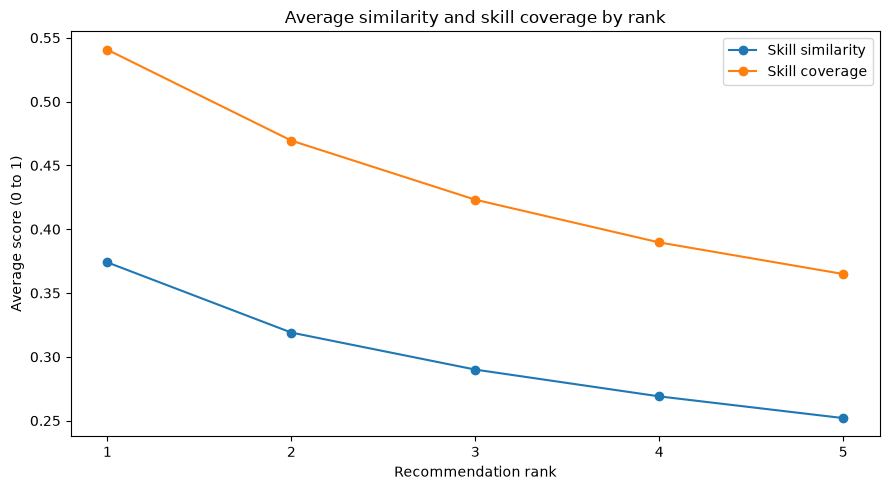

In [324]:
ranking_plot_data = ranking_analysis.copy()
ranking_plot_data['Average_Skill_Coverage'] = ranking_plot_data['Average_Skill_Coverage'] / 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ranking_plot_data.index, ranking_plot_data['Average_Similarity'], marker='o', label='Skill similarity')
ax.plot(ranking_plot_data.index, ranking_plot_data['Average_Skill_Coverage'], marker='o', label='Skill coverage')
ax.set_title('Average similarity and skill coverage by rank')
ax.set_xlabel('Recommendation rank')
ax.set_ylabel('Average score (0 to 1)')
ax.set_xticks(ranking_plot_data.index)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'ranking_similarity_coverage_cell333.png', dpi=160, bbox_inches='tight')
plt.show()


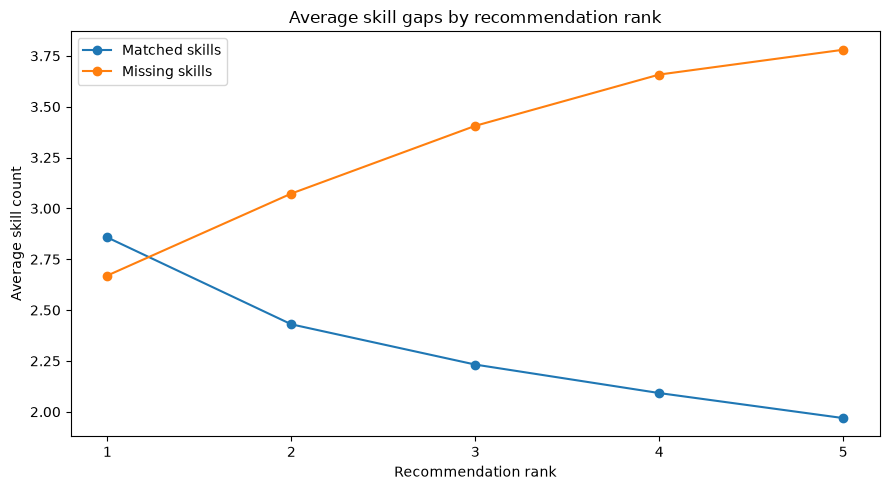

In [325]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ranking_analysis.index, ranking_analysis['Average_Matched_Skills'], marker='o', label='Matched skills')
ax.plot(ranking_analysis.index, ranking_analysis['Average_Missing_Skills'], marker='o', label='Missing skills')
ax.set_title('Average skill gaps by recommendation rank')
ax.set_xlabel('Recommendation rank')
ax.set_ylabel('Average skill count')
ax.set_xticks(ranking_analysis.index)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'ranking_skill_gaps_cell333.png', dpi=160, bbox_inches='tight')
plt.show()


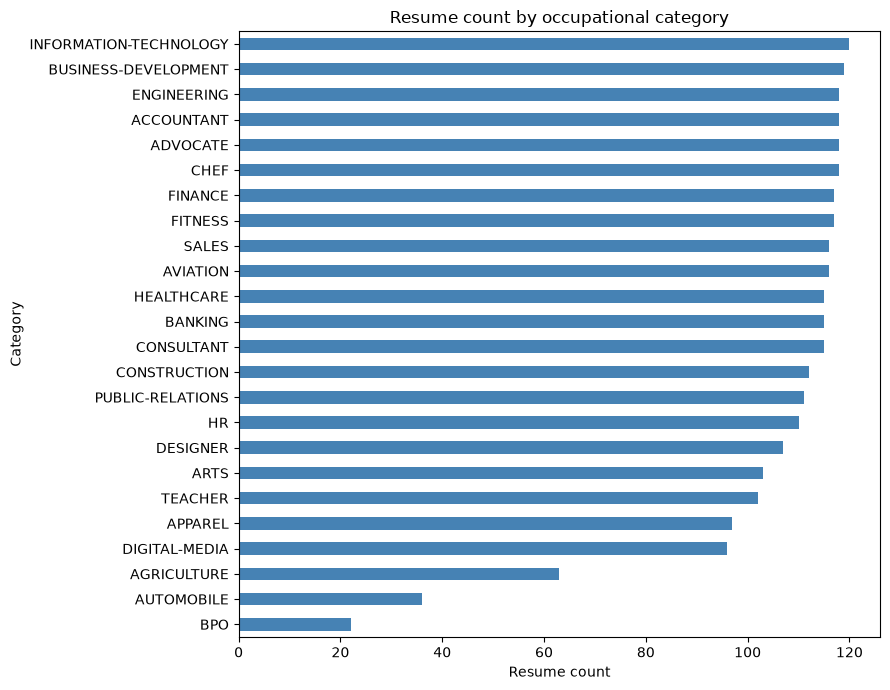

In [326]:
resume_category_counts = resume_df['Category'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
resume_category_counts.plot.barh(ax=ax, color='steelblue')
ax.set_title('Resume count by occupational category')
ax.set_xlabel('Resume count')
ax.set_ylabel('Category')
fig.tight_layout()
fig.savefig(output_dir / 'resume_category_counts.png', dpi=160, bbox_inches='tight')
plt.show()


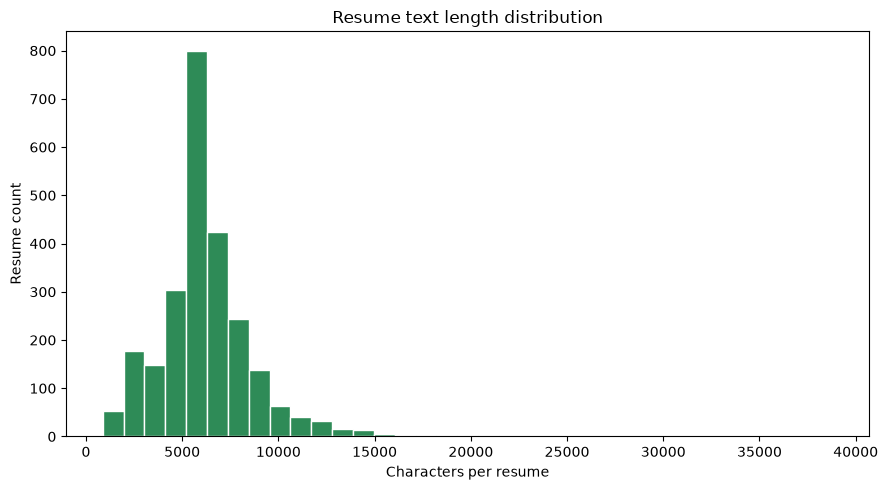

In [327]:
resume_lengths = resume_df['Resume_str'].fillna('').astype(str).str.len()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(resume_lengths, bins=35, color='seagreen', edgecolor='white')
ax.set_title('Resume text length distribution')
ax.set_xlabel('Characters per resume')
ax.set_ylabel('Resume count')
fig.tight_layout()
fig.savefig(output_dir / 'resume_text_lengths.png', dpi=160, bbox_inches='tight')
plt.show()


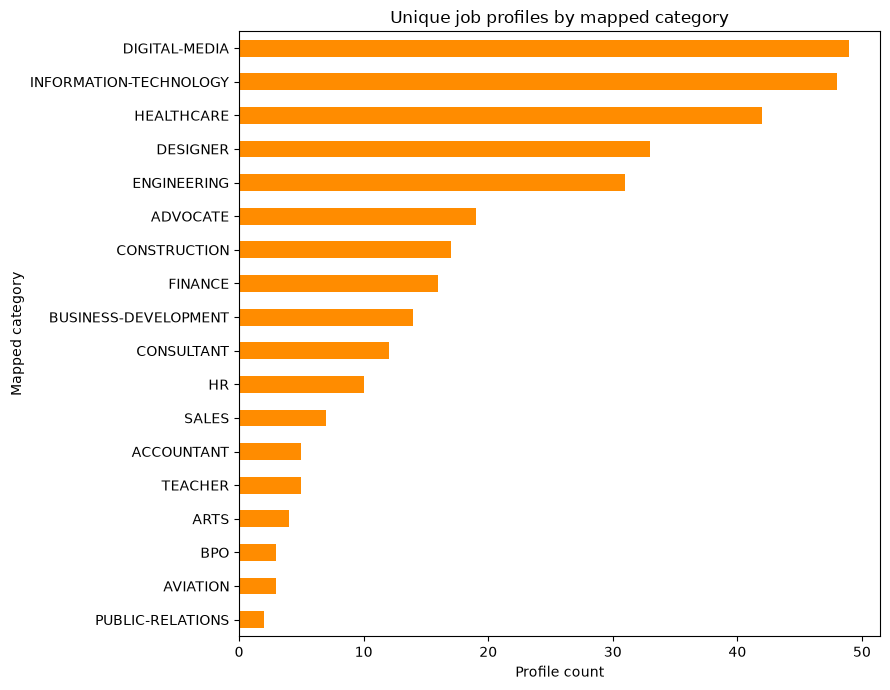

In [328]:
job_category_counts = job_profile_list['mapped_category'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
job_category_counts.plot.barh(ax=ax, color='darkorange')
ax.set_title('Unique job profiles by mapped category')
ax.set_xlabel('Profile count')
ax.set_ylabel('Mapped category')
fig.tight_layout()
fig.savefig(output_dir / 'job_profile_category_counts.png', dpi=160, bbox_inches='tight')
plt.show()


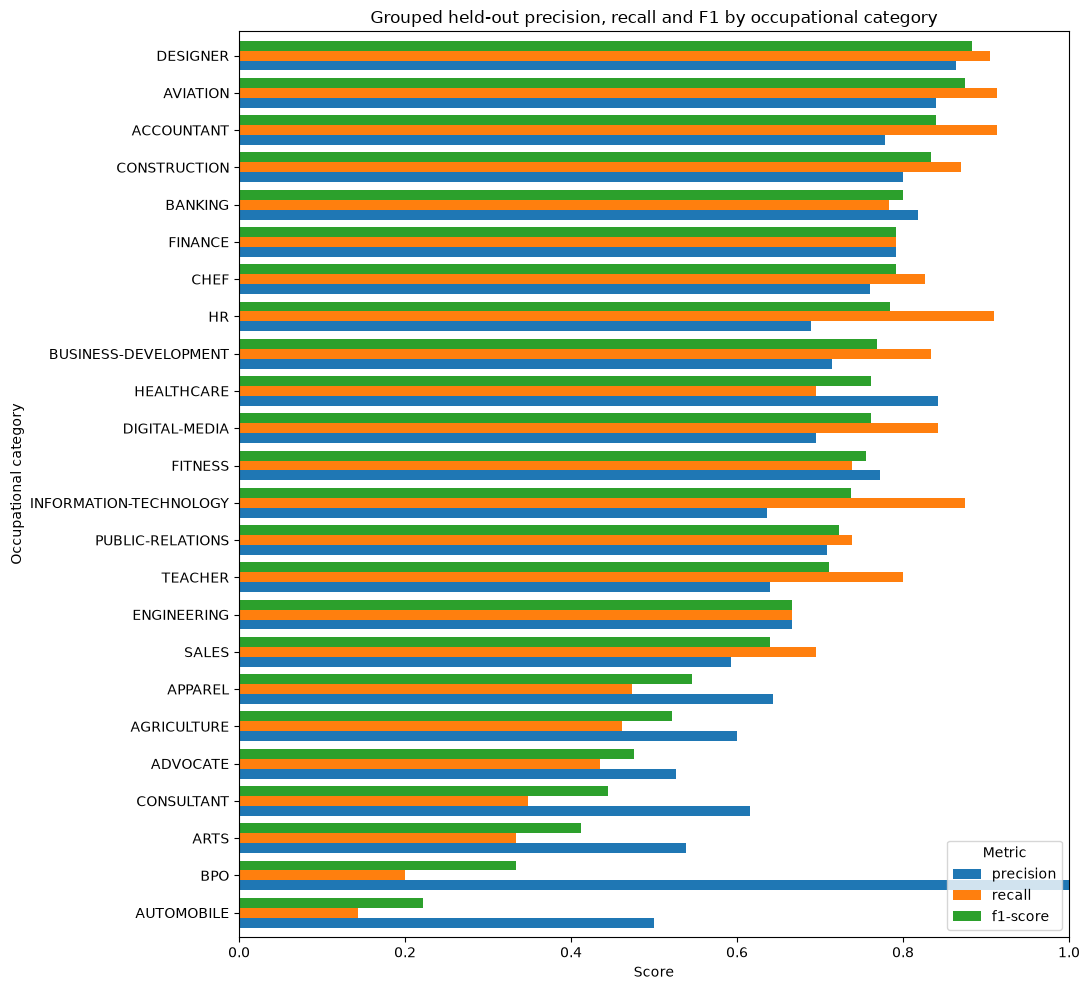

,precision,recall,f1-score
AUTOMOBILE,0.500000,0.142857,0.222222
BPO,1.000000,0.200000,0.333333
ARTS,0.538462,0.333333,0.411765
CONSULTANT,0.615385,0.347826,0.444444
ADVOCATE,0.526316,0.434783,0.476190
AGRICULTURE,0.600000,0.461538,0.521739
APPAREL,0.642857,0.473684,0.545455
SALES,0.592593,0.695652,0.640000
ENGINEERING,0.666667,0.666667,0.666667
TEACHER,0.640000,0.800000,0.711111


In [329]:
per_class_scores = classification_report_df.loc[class_labels, ['precision', 'recall', 'f1-score']].sort_values('f1-score')
fig, ax = plt.subplots(figsize=(11, 10))
per_class_scores.plot.barh(ax=ax, width=0.8)
ax.set_title('Grouped held-out precision, recall and F1 by occupational category')
ax.set_xlabel('Score')
ax.set_ylabel('Occupational category')
ax.set_xlim(0, 1)
ax.legend(title='Metric')
fig.tight_layout()
fig.savefig(output_dir / 'classification_per_class_scores.png', dpi=170, bbox_inches='tight')
plt.show()
per_class_scores


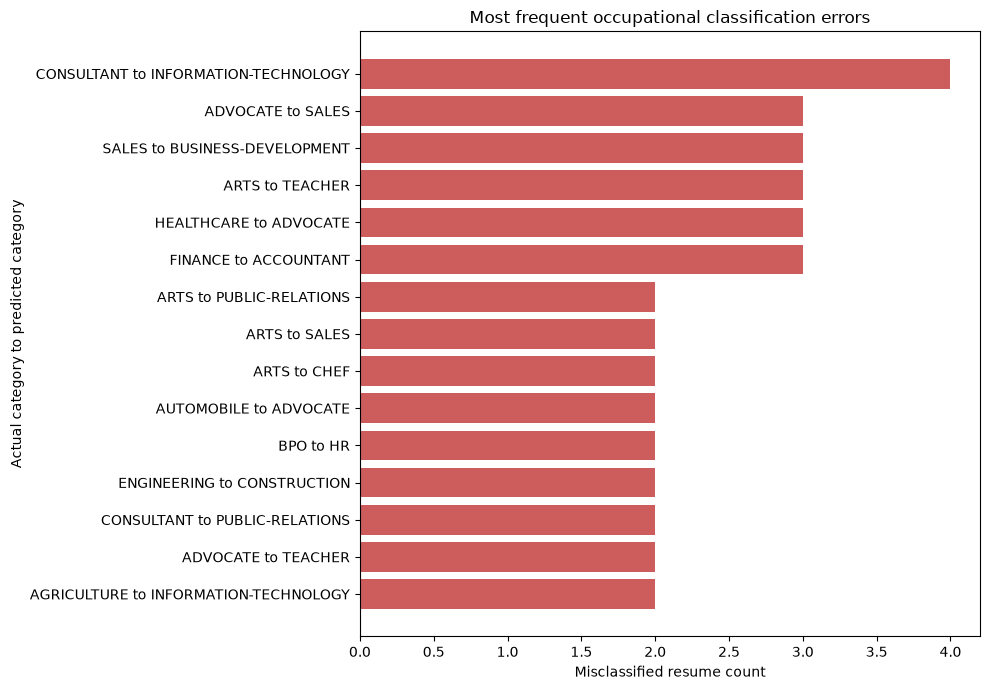

In [330]:
top_errors = confusion_pairs.head(15).sort_values()
error_labels = [f'{actual} to {predicted}' for actual, predicted in top_errors.index]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(error_labels, top_errors.values, color='indianred')
ax.set_title('Most frequent occupational classification errors')
ax.set_xlabel('Misclassified resume count')
ax.set_ylabel('Actual category to predicted category')
fig.tight_layout()
fig.savefig(output_dir / 'classification_error_pairs.png', dpi=160, bbox_inches='tight')
plt.show()


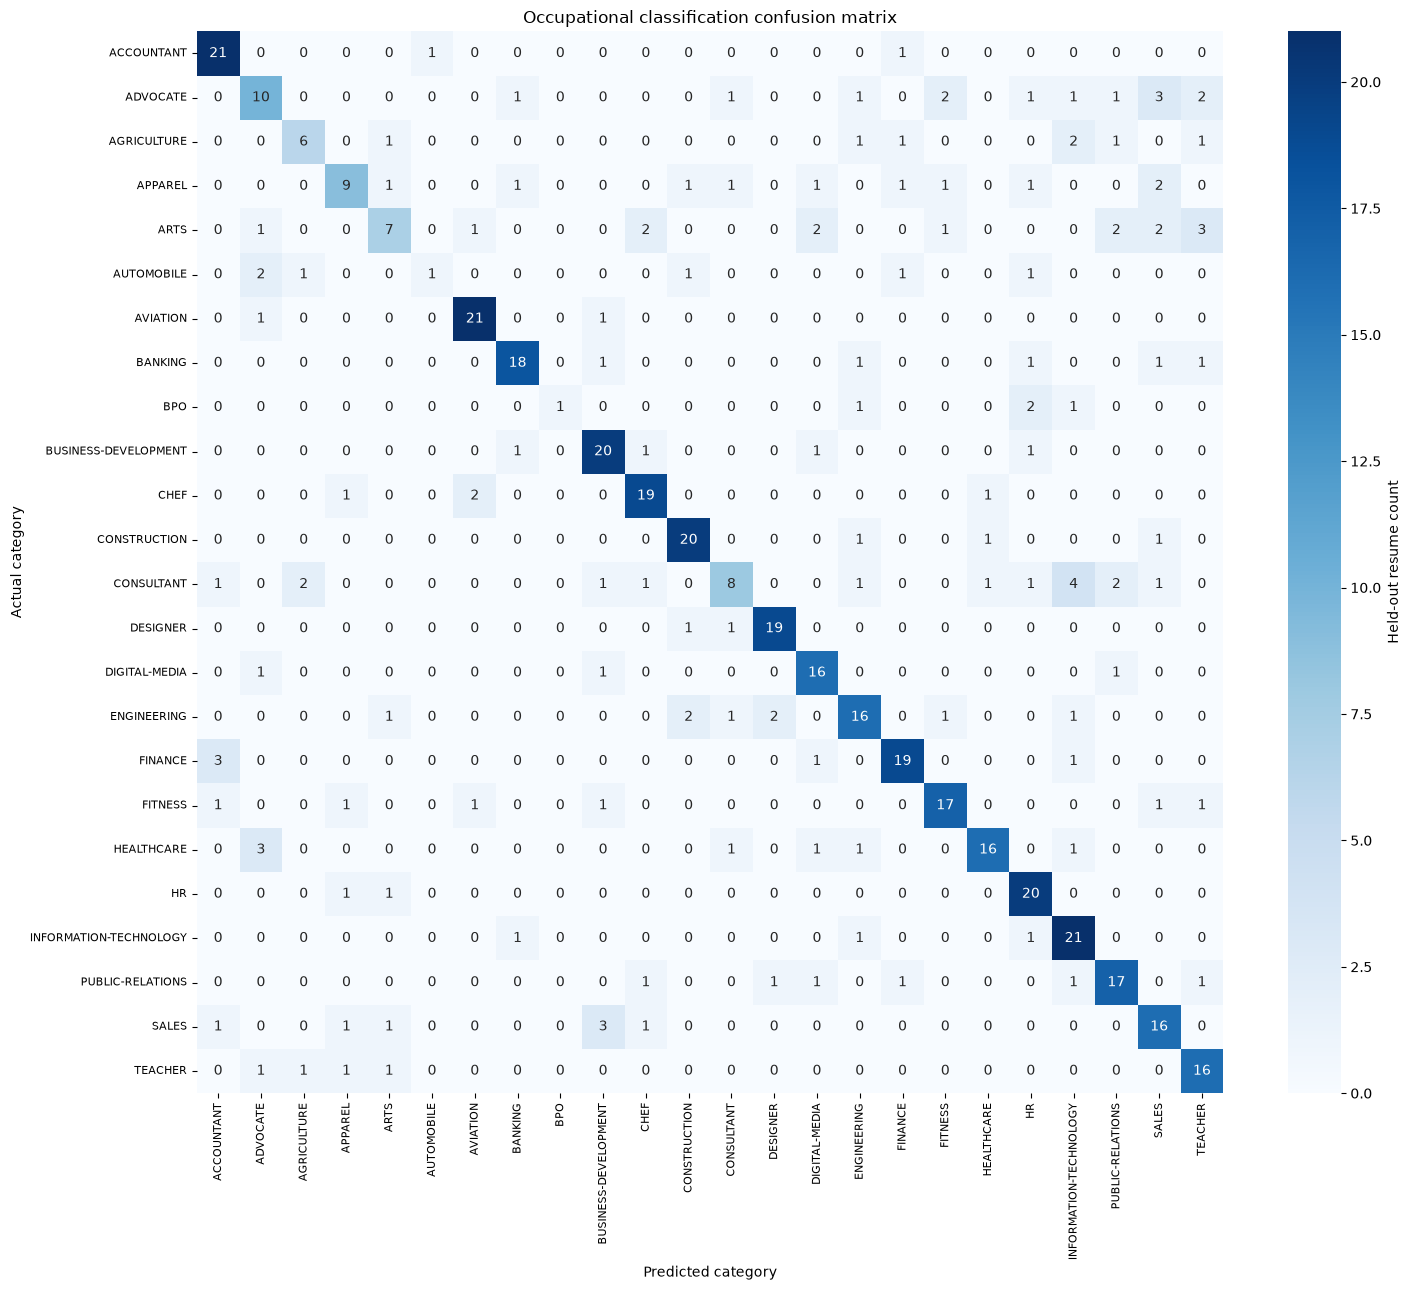

In [331]:
classification_confusion = confusion_matrix(y_test_cat, tuned_predictions, labels=class_labels)
classification_confusion_df = pd.DataFrame(classification_confusion, index=class_labels, columns=class_labels)
classification_confusion_df.to_csv(output_dir / 'classification_confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    classification_confusion,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar_kws={'label': 'Held-out resume count'},
    ax=ax,
)
ax.set_title('Occupational classification confusion matrix')
ax.set_xlabel('Predicted category')
ax.set_ylabel('Actual category')
ax.tick_params(axis='x', rotation=90, labelsize=8)
ax.tick_params(axis='y', rotation=0, labelsize=8)
fig.tight_layout()
fig.savefig(output_dir / 'classification_confusion_matrix.png', dpi=170, bbox_inches='tight')
plt.show()


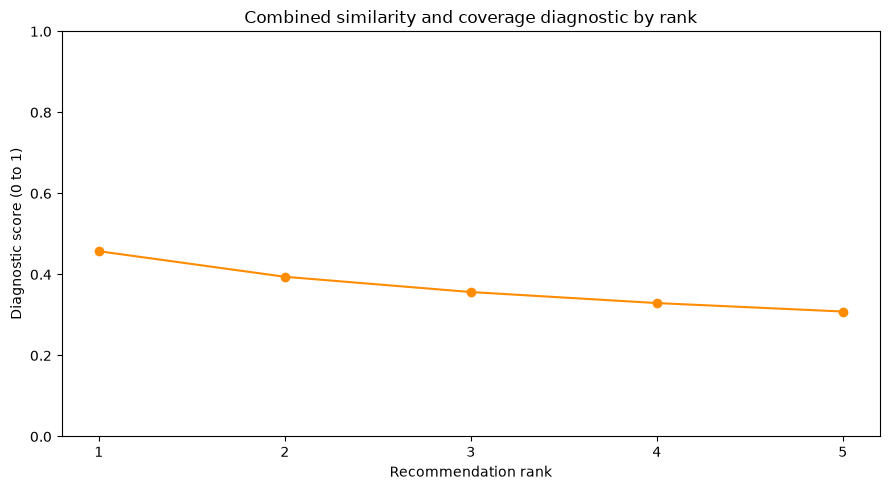

,Average_Similarity,Average_Skill_Coverage,Combined_Score_Diagnostic
Rank,,,
1,0.374,54.064,0.457320
2,0.319,46.944,0.394220
3,0.290,42.313,0.356565
4,0.269,38.964,0.329320
5,0.252,36.489,0.308445


In [332]:
ranking_plot_data = ranking_analysis.copy()
ranking_plot_data['Coverage_0_1'] = ranking_plot_data['Average_Skill_Coverage'] / 100
ranking_plot_data['Combined_Score_Diagnostic'] = (
    ranking_plot_data['Average_Similarity'] + ranking_plot_data['Coverage_0_1']
) / 2
ranking_plot_data[['Average_Similarity', 'Coverage_0_1', 'Combined_Score_Diagnostic']].to_csv(
    output_dir / 'ranking_score_diagnostics.csv'
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ranking_plot_data.index, ranking_plot_data['Combined_Score_Diagnostic'], marker='o', color='darkorange')
ax.set_title('Combined similarity and coverage diagnostic by rank')
ax.set_xlabel('Recommendation rank')
ax.set_ylabel('Diagnostic score (0 to 1)')
ax.set_xticks(ranking_plot_data.index)
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(output_dir / 'ranking_combined_diagnostic.png', dpi=160, bbox_inches='tight')
plt.show()
ranking_plot_data[['Average_Similarity', 'Average_Skill_Coverage', 'Combined_Score_Diagnostic']]


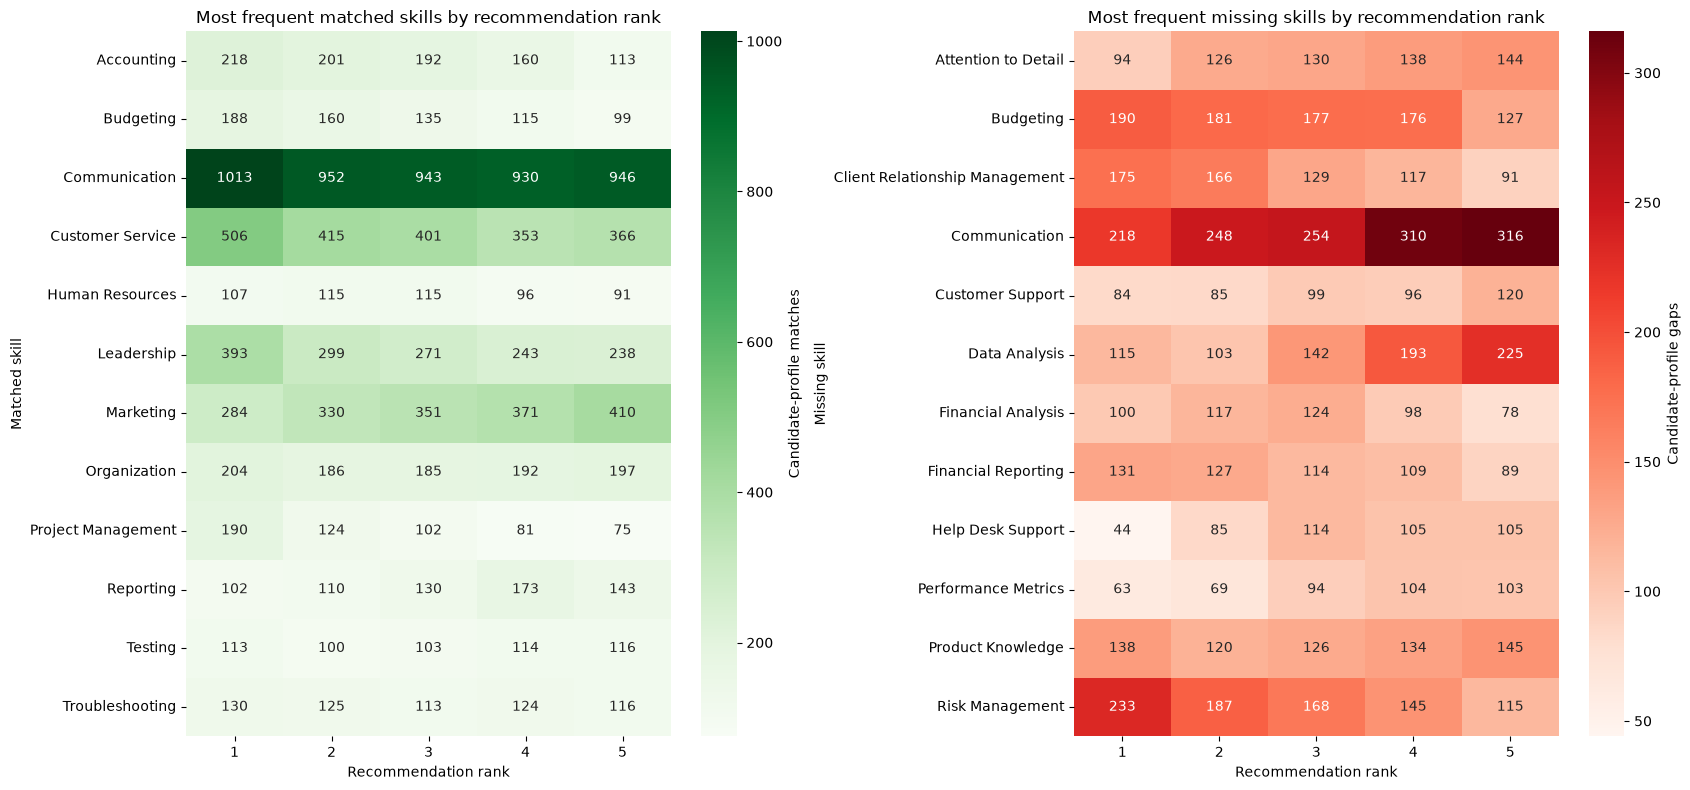

In [333]:
matched_skill_rows = recommendation_results[['Rank', 'Matched_Skills']].explode('Matched_Skills').dropna()
missing_skill_rows = recommendation_results[['Rank', 'Missing_Skills']].explode('Missing_Skills').dropna()
top_matched_skills = matched_skill_rows['Matched_Skills'].value_counts().head(12).index
top_missing_skills = missing_skill_rows['Missing_Skills'].value_counts().head(12).index
matched_skill_rank = (
    matched_skill_rows[matched_skill_rows['Matched_Skills'].isin(top_matched_skills)]
    .groupby(['Matched_Skills', 'Rank']).size().unstack(fill_value=0)
)
missing_skill_rank = (
    missing_skill_rows[missing_skill_rows['Missing_Skills'].isin(top_missing_skills)]
    .groupby(['Missing_Skills', 'Rank']).size().unstack(fill_value=0)
)
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
sns.heatmap(matched_skill_rank, cmap='Greens', annot=True, fmt='d', ax=axes[0], cbar_kws={'label': 'Candidate-profile matches'})
axes[0].set_title('Most frequent matched skills by recommendation rank')
axes[0].set_xlabel('Recommendation rank')
axes[0].set_ylabel('Matched skill')
sns.heatmap(missing_skill_rank, cmap='Reds', annot=True, fmt='d', ax=axes[1], cbar_kws={'label': 'Candidate-profile gaps'})
axes[1].set_title('Most frequent missing skills by recommendation rank')
axes[1].set_xlabel('Recommendation rank')
axes[1].set_ylabel('Missing skill')
fig.tight_layout()
fig.savefig(output_dir / 'ranking_skill_gap_heatmaps.png', dpi=160, bbox_inches='tight')
plt.show()


In [334]:
recommendation_method_comparison = pd.DataFrame([
    {
        'Method': 'TF-IDF similarity plus normalized skill coverage',
        'Configuration': '50% TF-IDF, 50% skill coverage',
        'Workflow_Role': 'Exploratory experiment',
        'Used_For_Final_Ranking': False,
    },
    {
        'Method': 'Role relevance percentile plus skill relevance percentile',
        'Configuration': '70% role, 30% skill',
        'Workflow_Role': 'Exploratory experiment',
        'Used_For_Final_Ranking': False,
    },
    {
        'Method': 'Cosine similarity between binary skill vectors',
        'Configuration': 'Skill-vector cosine similarity',
        'Workflow_Role': 'Official final ranking',
        'Used_For_Final_Ranking': True,
    },
])
recommendation_evaluation_status = pd.DataFrame([{
    'Verified_Candidate_Job_Relevance_Labels_Available': False,
    'Hiring_Outcome_Labels_Available': False,
    'Recommendation_Accuracy_Computed': False,
    'Final_Ranking_Method': 'Skill-vector cosine similarity',
    'Skill_Coverage_Used_As_Ranking_Score': False,
    'Experimental_50_50_Used_In_Final_Ranking': False,
    'Experimental_70_30_Used_In_Final_Ranking': False,
}])
recommendation_method_comparison.to_csv(output_dir / 'recommendation_method_comparison.csv', index=False)
recommendation_evaluation_status.to_csv(output_dir / 'recommendation_evaluation_status.csv', index=False)
recommendation_method_comparison, recommendation_evaluation_status

(                                                      Method  \
 0           TF-IDF similarity plus normalized skill coverage   
 1  Role relevance percentile plus skill relevance percentile   
 2             Cosine similarity between binary skill vectors   
 
                     Configuration           Workflow_Role  \
 0  50% TF-IDF, 50% skill coverage  Exploratory experiment   
 1             70% role, 30% skill  Exploratory experiment   
 2  Skill-vector cosine similarity  Official final ranking   
 
    Used_For_Final_Ranking  
 0                   False  
 1                   False  
 2                    True  ,
    Verified_Candidate_Job_Relevance_Labels_Available  \
 0                                              False   
 
    Hiring_Outcome_Labels_Available  Recommendation_Accuracy_Computed  \
 0                            False                             False   
 
              Final_Ranking_Method  Skill_Coverage_Used_As_Ranking_Score  \
 0  Skill-vector cosine similar